# Do a few early tokens decide the algorithm? — demo of `method.py`

**Question.** A code model writes a path-search program. Is its *algorithm* (BFS, DFS, A\*, Dijkstra, Bellman–Ford, …) fixed by the prompt before the first token, or do a few early "fork" tokens decide it? And when the prompt bans the model's favourite algorithm, what does the model write instead?

**Experiment** (Qwen3-8B, bf16, thinking off, vLLM 0.11.0)
* Two coding tasks built for this experiment, each with 40 seeded hidden tests:
  * **T1**, unweighted grid path: `solve(grid, start, goal)`.
  * **T2**, weighted shortest path: `solve(n, edges, s, t)`.
* Two prompt conditions, 10 paraphrases each:
  * **baseline**: "Please solve the following programming task."
  * **ban**: "Do not use breadth-first search (BFS)." on T1, "Do not use Dijkstra's algorithm." on T2.
* Every generated program gets one algorithm label:
  * primarily from a sandboxed **runtime tracer**, which instruments `heapq` / `deque` / `queue`, grid reads, edge passes and recursion depth;
  * from **AST rules** when the tracer cannot decide;
  * from an **LLM judge** when the two disagree.
* Measurements on one shared pool of about 10k labelled generations:
  1. **S6 pools.** The baseline prompt at temperature T ∈ {0.3, 0.7, 1.0, 1.3}, and the ban prompt at T = 1.0.
  2. **S7–S9 forking-paths screen.** One base path per prompt (40 in all) is restarted from its first k tokens, with 8 continuations per k: k = 4, 8, …, 92 on ban paths and k = 4, 8, 16, 32, 64 on baseline paths. Permutation-calibrated change points in the label distribution are localised to a single token. Each candidate is confirmed with 30 continuations and checked against control positions.
  3. **S10 prompt swap.** The prompt is swapped at the token where the model commits to an algorithm.
  4. **S11 temperature knob.** Heating only the fork window is compared with global temperature, against random-window and anchored controls.
  5. **S12 probes.** Residual-stream probes against a prompt-only predictor.

**What this notebook runs.** `method.py` has four phases. Three of them, `gen1`, `gen2` and `states`, need a 20 GB GPU, vLLM and the 16 GB model. The records they produced, 8,900 labelled generations, are this notebook's data. `mini_demo_data.json` holds the 40 base paths, and each base path carries every generation that belongs to its prompt. On a CPU, this notebook runs three things:
1. **The labeller.** The artifact's sandbox, tracer and AST rules check the 17 reference solutions, then relabel recorded model programs.
2. **The analysis phase.** This is `python method.py --phase analysis`, the script's default. On the recorded generations it computes change points and forks, the prompt swap, the knob table, the pre-registered verdict and the figures.
3. **Results.** Tables next to the artifact's stored `method_out.json`, the artifact's figures, and the label distribution along each ban path.

At the artifact's original settings, which are the ones set here, the notebook runs in about 2.5–3 minutes on 2 CPUs (144–189 s in the test runs, installs included). The only network access is to GitHub for the data and to the Hugging Face Hub for the Qwen3 tokenizer.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru, ruptures — NOT on Colab, always install (ruptures' only dependencies, numpy and scipy, are Colab packages)
_pip('loguru==0.7.3')
_pip('--no-deps', 'ruptures==1.1.10')

# numpy, scipy, pandas, matplotlib, transformers (+ tokenizers, huggingface_hub) — pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'pandas==2.2.2', 'matplotlib==3.10.0',
         'transformers==5.0.0', 'tokenizers==0.22.2', 'huggingface_hub==1.4.0')

In [2]:
from __future__ import annotations

# ---- method.py
import argparse
import json
import os
import resource
import sys
import time
from pathlib import Path

from loguru import logger

# ---- common.py (also json, sys, time, Path, logger)
import hashlib
import math

import numpy as np

# ---- analysis/final.py (also json, math, time, Path, numpy, logger); analysis/cpd.py needs only numpy
import ast
import collections
import keyword
import re

# ---- notebook: result tables and plots
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

pd.set_option("display.max_colwidth", 90)

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-1/experiment-3/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
examples = data["datasets"][0]["examples"]
print(data["datasets"][0]["dataset"], "-", len(examples), "examples (one per prompt); rows per generations file:",
      data["metadata"]["n_rows"])
print(len(data["metadata"]["codes"]), "programs stored with their code")
for ex in (examples[0], examples[10]):
    print(f'\n--- {ex["metadata_bp_id"]}: base path implements {ex["output"]}; it first names an algorithm at '
          f'generated token {ex["metadata_commit_idx"]} ({ex["metadata_evidence_term"]!r})')
    print(ex["input"])

GitHub data unavailable, using local mini_demo_data.json: <urlopen error [Errno 111] Connection refused>
fork_screen_base_paths - 40 examples (one per prompt); rows per generations file: {'pools': 1200, 'screen': 4480, 'localise': 312, 'confirm': 1108, 'swap': 1200, 'knob': 600}
627 programs stored with their code

--- T1|baseline|0: base path implements BFS; it first names an algorithm at generated token 6 ('deque')
Please solve the following programming task.

Write a Python function solve(grid, start, goal) that finds a path on a 2-D grid. grid is a list of equal-length strings in which . is a free cell and # is an obstacle; start and goal are (row, col) tuples. Moves go up, down, left or right between free cells. Return any valid path as a list of (row, col) tuples from start to goal inclusive, or [] if the goal is unreachable or either endpoint is blocked. The grid has at most 30 rows and 30 columns. Use only the Python standard library. Return only one ```python code block contai

## Configuration
All tunable sizes are set here. The comment after each value gives the artifact's original value. At the original values, with `N_PARAS = 10`, the analysis uses the same seeds and data as the artifact's own run, so its numbers can be compared directly with the stored `method_out.json` (section 7).

The values set below **are** the original values. The notebook was scaled up in three test runs on 2 CPUs (total notebook time, installs included):

| run | settings | time |
|---|---|---|
| 1 | `N_PARAS = 1`, 20 permutations, 2 T6 simulations, 10 bootstrap resamples, 2 relabelled programs | 50 s |
| 2 | `N_PARAS = 5`, about a quarter of the original counts, 40 relabelled programs | 61 s |
| 3 | all original values, 400 relabelled programs | 189 s |
| final | the same values; this saved run | 160 s |
| check | re-run of this exact file in a fresh environment; identical results | 144 s |

Relabelling the 400 programs takes 70–110 s of that time. Lower `N_RELABEL` for a quicker run.

In [5]:
# which phase of method.py runs (gen1 / gen2 / states need a GPU with vLLM and the 16 GB model)
PHASE = "analysis"        # original default: --phase analysis

# data subset
N_PARAS = 10              # paraphrases per task x condition (original: 10 -> 40 base paths)

# labeller: sandboxed tracer + AST rules + hidden tests
LABEL_WORKERS = 2         # sandbox subprocesses in parallel (original: 5; the unit test used 8)
N_RELABEL = 400           # G1/G2 programs relabelled again (400 = all stored here; the artifact labelled all ~6.4k once)

# statistics of the analysis phase
N_PERM_CPD = 1000         # permutations of the change-point null (original: 1000)
N_PERM_FORK = 2000        # permutations of the fork / control chi-square test (original: 2000)
T6_N_SIM = 200            # simulated paths per effect size, T6 detector check (original: 200)
N_BOOT = 1000             # bootstrap resamples, swap and knob tables (original: 1000)
N_BOOT_CONTRAST = 2000    # cluster-bootstrap resamples of the K1 / K4 contrasts (original: 2000)
N_RAREFY = 30             # rarefaction draws of the phrasing clusters (original: 30)

# judge labels: True = the recorded OpenRouter adjudication (summaries/judge.json); False = SKIP_JUDGE=1, i.e. the
# tracer / AST labels only, as in the artifact's stored method_out.json
USE_RECORDED_JUDGE = True

## 1. `common.py`: shared utilities
* Output folders: `generations/`, `summaries/`, `logs/`, `figures/`, `states/`. The artifact keeps them next to `method.py`; here they live in `fork_screen/`, which the notebook rebuilds in the working directory.
* `stable_seed`: every vLLM request is seeded with `sha256(task, condition, paraphrase, arm, prefix length, …) mod 2^31`, and so are the permutation tests below.
* The small statistics used everywhere:
  * `wilson`: Wilson intervals, as (p, lo, hi).
  * `hill1`: the Hill number of order 1, i.e. exp(Shannon entropy). 1 means a single algorithm, 2 means two equally common ones.
  * `entropy_bits`, `tvd` (total-variation distance) and `js_div` (Jensen–Shannon divergence).

In [6]:
"""Shared utilities: paths, logging, hashing, JSONL IO, seeds and the small statistics used everywhere."""

# (imports: see the imports cell)

ROOT = Path("fork_screen").resolve()  # notebook: the artifact folder, rebuilt here (was Path(__file__).resolve().parent)
GEN_DIR = ROOT / "generations"
SUM_DIR = ROOT / "summaries"
LOG_DIR = ROOT / "logs"
FIG_DIR = ROOT / "figures"
STATE_DIR = ROOT / "states"
for _d in (GEN_DIR, SUM_DIR, LOG_DIR, FIG_DIR, STATE_DIR):
    _d.mkdir(parents=True, exist_ok=True)

MODEL_ID = "Qwen/Qwen3-8B"
TASKS = ("T1", "T2")
CONDITIONS = ("baseline", "ban")


def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def stable_seed(*parts) -> int:
    h = hashlib.sha256(repr(tuple(parts)).encode()).hexdigest()
    return int(h, 16) % (2 ** 31 - 1000)


def sha256_file(p: Path) -> str:
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()


def log_hash(name: str, path: Path) -> str:
    h = sha256_file(path)
    with open(LOG_DIR / "hashes.log", "a") as fh:
        fh.write(f"{time.strftime('%Y-%m-%dT%H:%M:%S')}\t{time.time():.3f}\t{name}\t{path.name}\t{h}\n")
    return h


def append_jsonl(path: Path, rows: list[dict]) -> None:
    with open(path, "a") as fh:
        for r in rows:
            fh.write(json.dumps(r) + "\n")


def read_jsonl(path: Path) -> list[dict]:
    if not Path(path).exists():
        return []
    out = []
    with open(path) as fh:
        for line in fh:
            line = line.strip()
            if line:
                try:
                    out.append(json.loads(line))
                except json.JSONDecodeError:
                    continue  # a line still being written by a concurrent appender
    return out


def wilson(k: int, n: int, z: float = 1.96) -> tuple[float, float, float]:
    if n == 0:
        return (float("nan"), float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (p, max(0.0, c - h), min(1.0, c + h))


def hill1(labels: list) -> float:
    """Hill number of order 1 = exp(Shannon entropy in nats) of the label distribution."""
    if not labels:
        return float("nan")
    _, cnt = np.unique(np.asarray(labels, dtype=object).astype(str), return_counts=True)
    p = cnt / cnt.sum()
    return float(np.exp(-(p * np.log(p)).sum()))


def entropy_bits(counts) -> float:
    c = np.asarray(counts, dtype=float)
    if c.sum() <= 0:
        return float("nan")
    p = c[c > 0] / c.sum()
    return float(-(p * np.log2(p)).sum())


def tvd(p, q) -> float:
    p = np.asarray(p, dtype=float)
    q = np.asarray(q, dtype=float)
    if p.sum() == 0 or q.sum() == 0:
        return float("nan")
    return float(0.5 * np.abs(p / p.sum() - q / q.sum()).sum())


def js_div(p, q) -> float:
    p = np.asarray(p, dtype=float)
    q = np.asarray(q, dtype=float)
    p = p / p.sum()
    q = q / q.sum()
    m = 0.5 * (p + q)

    def kl(a, b):
        mask = a > 0
        return float((a[mask] * np.log2(a[mask] / b[mask])).sum())

    return 0.5 * kl(p, m) + 0.5 * kl(q, m)

## 2. `method.py`: the orchestrator
`python method.py --phase <phase>` runs one resumable phase. Phases pass data to each other only through files.

| phase | runs on | what it does | in this notebook |
|---|---|---|---|
| `gen1` | GPU, vLLM | Engine tests T4/T5, then the **S6 pools**: 1,200 samples. G1 is the baseline prompt at T = 1.0 (20 per paraphrase), G2 the ban prompt at T = 1.0 (10 per paraphrase), G3 the baseline prompt at T ∈ {0.3, 0.7, 1.3} (10 per paraphrase). | records in the demo data |
| `gen2` | GPU, vLLM | **S7** screen (4,480 continuations), **S8** provisional change points, **S9** localisation (312) plus confirmation and controls (1,108), **S10** prompt swap (1,200), **S11** knob arms (600) | records in the demo data |
| `states` | GPU, HF transformers | **S12** residual states of the 600 G1/G2 samples at 8 positions × layers 8–28 (790 MB), and next-token entropies at the fork candidates | entropies only |
| `analysis` | CPU, plus the OpenRouter judge | Judge adjudication, readouts, probes, verdict, figures, `method_out.json` | **runs in section 6** |

The cell below is `method.py`. Three things differ from the artifact:
* The imports from `common` are already defined, and `run_analysis` is defined in section 5.
* `main()` takes `PHASE` from the configuration cell instead of the command line.
* `main()` is called in section 6.

Calling `phase_gen1`, `phase_gen2` or `phase_states` here would fail: the `gen/` package (vLLM) and `analysis/states.py` (a CUDA model) are not rebuilt in this notebook.

In [7]:
#!/usr/bin/env python3
"""Do a few early tokens decide the algorithm? -- orchestrator for the whole screen.

Phases (each is resumable; outputs are checkpointed under generations/, summaries/, states/):
  gen1      vLLM process: engine tests T4/T5, S6 pools (staged: 1 paraphrase, then all 10)
  gen2      vLLM process: S7 screen, S8 change points, S9 localise + confirm, S10 prompt swap, S11 knob
  states    HF process:   S12 residual states at 8 positions x layers 8..28
  analysis  CPU:          judge adjudication, probes, S13 readouts, verdict, figures, method_out.json
Usage: .venv/bin/python method.py --phase gen1|gen2|states|analysis
"""

# (imports: see the imports cell)

# ROOT = Path(__file__).resolve().parent   -- notebook: ROOT is fork_screen/ (common.py cell)
sys.path.insert(0, str(ROOT))  # the tasks / labeller / harness packages are imported from there

# from loguru import logger                             -- imports cell
# from common import LOG_DIR, log_hash, setup_logging  -- notebook: defined in the common.py cell


def _ram_limit(gb: float) -> None:
    try:
        resource.setrlimit(resource.RLIMIT_AS, (int(gb * 1024 ** 3), int(gb * 1024 ** 3)))
    except (ValueError, OSError) as e:
        logger.warning(f"could not set RLIMIT_AS: {e}")


def _prompts(tok) -> dict:
    from prompts.build_prompts import build
    p = ROOT / "prompts" / "prompts.json"
    if not p.exists():
        p.write_text(json.dumps(build(tok), indent=1))
        log_hash("prompts", p)
    return json.loads(p.read_text())


def _ensure_prereg() -> None:
    hl = LOG_DIR / "hashes.log"
    if not hl.exists() or "prereg" not in hl.read_text():
        log_hash("prereg", ROOT / "prereg.json")


@logger.catch(reraise=True)
def phase_gen1() -> None:
    from transformers import AutoTokenizer

    from gen.engine import load_engine
    from gen.stages_pool import run_s6, run_t45
    from harness.pool import LabelPool
    _ensure_prereg()
    tok = AutoTokenizer.from_pretrained("Qwen/Qwen3-8B")
    prompts = _prompts(tok)
    pool = LabelPool(workers=5)
    llm = load_engine()
    t0 = time.time()
    if not (LOG_DIR / "test_engine.json").exists():
        run_t45(llm, tok, prompts, pool)
    run_s6(llm, tok, prompts, pool, stage_tag="stage1", limit_paras=1)
    logger.info(f"S6 stage1 done at {time.time() - t0:.0f}s")
    run_s6(llm, tok, prompts, pool, stage_tag="full")
    logger.info(f"S6 full done at {time.time() - t0:.0f}s")
    pool.shutdown()


@logger.catch(reraise=True)
def phase_gen2() -> None:
    from transformers import AutoTokenizer

    from gen.engine import load_engine
    from gen.stages_screen import run_gen2
    from harness.pool import LabelPool
    tok = AutoTokenizer.from_pretrained("Qwen/Qwen3-8B")
    prompts = _prompts(tok)
    pool = LabelPool(workers=5)
    llm = load_engine()
    run_gen2(llm, tok, prompts, pool)
    pool.shutdown()


@logger.catch(reraise=True)
def phase_states() -> None:
    from analysis.states import run_states
    run_states()


@logger.catch(reraise=True)
def phase_analysis() -> None:
    # from analysis.final import run_analysis  -- notebook: run_analysis() is defined in section 5
    run_analysis()


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--phase", default="analysis", choices=["gen1", "gen2", "states", "analysis"])
    args = ap.parse_args(["--phase", PHASE])  # notebook: no command line; PHASE comes from the config cell
    setup_logging(f"method_{args.phase}")
    os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
    if args.phase == "analysis":  # CUDA needs large virtual reservations: no RLIMIT_AS on GPU phases
        _ram_limit(40)
    logger.info(f"phase {args.phase} start")
    {"gen1": phase_gen1, "gen2": phase_gen2, "states": phase_states, "analysis": phase_analysis}[args.phase]()
    logger.info(f"phase {args.phase} done")


# if __name__ == "__main__":
#     main()        -- notebook: main() runs in section 6, after run_analysis() is defined

### 2b. The GPU phases' records
The cell below writes the records back to the paths the code reads:
* `generations/*.jsonl` (pools, screen, localise, confirm, swap, knob).
* The side files the analysis needs:
  * `summaries/gen2_provisional.json`: the S9 fork candidates and control positions.
  * `summaries/next_token.json`: next-token entropies.
  * `summaries/judge.json`: the recorded OpenRouter adjudication.
  * `prereg.json` and `predictions.json`, written before S10 and S11; their hashes go into `method_out.json`.
  * The engine and state test logs, and the hidden-test time limits.
* `prompts/prompts.json`, holding the prompt text.

This cell is notebook glue: in the artifact, `gen1`/`gen2` wrote these files themselves. Only the first `N_PARAS` paraphrases of every task × condition are written.

In [8]:
sel = [ex for ex in examples if ex["metadata_paraphrase_id"] < N_PARAS]
bps = {ex["metadata_bp_id"] for ex in sel}
CODES = data["metadata"]["codes"]
ARMS = {"screen": "A1_screen", "localise": "A2_localise", "confirm": "A2_confirm", "swap": "A3_swap"}
for fname in ("pools", "screen", "localise", "confirm", "swap", "knob"):
    rows = []
    for ex in sel:
        for r in ex["rows"][fname]:
            row = {"task": ex["metadata_task"], "condition": ex["metadata_condition"],
                   "paraphrase_id": ex["metadata_paraphrase_id"], **r}
            if fname in ARMS:          # a continuation restarts from this example's base path ...
                row.update(arm=ARMS[fname], base_path_id=ex["metadata_bp_id"])
            if fname == "swap":        # ... and a swap continuation runs under the prompt it is swapped to
                row["condition"] = r["swap_prompt"]
            if row.get("code_sha256") in CODES:
                row["code"] = CODES[row["code_sha256"]]
            rows.append(row)
    (GEN_DIR / f"{fname}.jsonl").unlink(missing_ok=True)
    append_jsonl(GEN_DIR / f"{fname}.jsonl", rows)
    print(f"generations/{fname}.jsonl: {len(rows):5d} rows")

for rel, content in data["metadata"]["recorded_files"].items():
    if rel == "summaries/gen2_provisional.json":     # fork candidates / control positions of the selected paths
        content = {k: [x for x in v if x["bp_id"] in bps] for k, v in content.items()}
    if rel == "summaries/next_token.json":
        content = [x for x in content if x["bp_id"] in bps]
    (ROOT / rel).parent.mkdir(parents=True, exist_ok=True)
    (ROOT / rel).write_text(content if isinstance(content, str) else json.dumps(content, indent=1))
(ROOT / "prompts").mkdir(exist_ok=True)
(ROOT / "prompts" / "prompts.json").write_text(json.dumps(
    {ex["metadata_bp_id"]: {"task": ex["metadata_task"], "condition": ex["metadata_condition"],
                            "paraphrase_id": ex["metadata_paraphrase_id"], "segment": ex["metadata_prompt_segment"],
                            "user_text": ex["input"]} for ex in examples}, indent=1))
(SUM_DIR / "t6_sensitivity.json").unlink(missing_ok=True)   # T6 is recomputed with this notebook's settings
if USE_RECORDED_JUDGE:
    os.environ.pop("SKIP_JUDGE", None)
else:
    os.environ["SKIP_JUDGE"] = "1"                           # run_analysis(): tracer / AST labels only
print("side files:", ", ".join(sorted(data["metadata"]["recorded_files"])), "+ prompts/prompts.json")

generations/pools.jsonl:  1200 rows
generations/screen.jsonl:  4480 rows
generations/localise.jsonl:   312 rows
generations/confirm.jsonl:  1108 rows
generations/swap.jsonl:  1200 rows


generations/knob.jsonl:   600 rows


side files: logs/hashes.log, logs/test_engine.json, logs/test_states.json, predictions.json, prereg.json, summaries/gen2_deviations.json, summaries/gen2_provisional.json, summaries/judge.json, summaries/next_token.json, tasks/limits.json + prompts/prompts.json


## 3. The labeller
A model response becomes one algorithm label inside a sandbox. `harness/pool.py` starts one `python -I harness/run_program.py` subprocess per distinct program, cached by its SHA-256. The child process does four things:
1. **Extracts** the first ```` ```python ```` block (`harness/extract.py`).
2. **Computes the AST label** (`labeller/ast_rules.py`).
3. **Traces the program.** It installs the runtime tracer (`labeller/tracer.py`), executes the program and calls `solve()` on crafted inputs, recording:
   * which containers it uses and how (FIFO pops, LIFO pops, heap pushes and their priorities);
   * the order in which it first reads grid cells;
   * recursion depth, passes over the edge list, and executed lines.

   Ordered signature rules turn these records into a label. When they cannot decide, the AST label is used.
4. **Runs the 40 hidden tests**, with a time limit per case, under `RLIMIT_AS` / `RLIMIT_CPU`. It stops early on a timeout or after 3 failures.

The child imports the task and labeller modules from disk. So the next cells write the artifact's files, unchanged, into `fork_screen/` with `%%writefile`. Writing a file does not run its code.

In [9]:
for sub in ("tasks", "labeller", "harness"):
    (ROOT / sub).mkdir(parents=True, exist_ok=True)
    (ROOT / sub / "__init__.py").write_text("")

### `tasks/t1_grid.py`: T1, unweighted grid path
* `SPEC` is the task text that follows the condition sentence in every prompt.
* `CATALOGUE` is the label set (BFS, DFS, bidirectional BFS, IDDFS, A\*/greedy best-first, unit-cost Dijkstra), completed by `other` and `no_code`. `BANNED_MODE = "BFS"`.
* `make_cases()` generates the 40 hidden tests from a seed: edge cases, random grids, mazes, open grids, serpentines and unreachable goals.
* `validate()` accepts any valid path.
* `REFERENCES` holds 9 reference solutions, at least one per algorithm, and `BAD_PROGRAMS` holds programs that must fail.

In [10]:
%%writefile fork_screen/tasks/t1_grid.py
"""T1: unweighted grid path. Spec, seeded hidden-test generator, references and validator."""

from __future__ import annotations

import random
from collections import deque

TASK_ID = "T1"
SPEC = (
    "Write a Python function solve(grid, start, goal) that finds a path on a 2-D grid. grid is a list of "
    "equal-length strings in which . is a free cell and # is an obstacle; start and goal are (row, col) tuples. "
    "Moves go up, down, left or right between free cells. Return any valid path as a list of (row, col) tuples "
    "from start to goal inclusive, or [] if the goal is unreachable or either endpoint is blocked. The grid has at "
    "most 30 rows and 30 columns. Use only the Python standard library. Return only one ```python code block "
    "containing the function and its imports."
)

# Catalogue (merged modes). 'other' and 'no_code' complete the outcome space.
CATALOGUE = ["BFS", "DFS", "bidirectional_BFS", "IDDFS", "astar_greedy", "unit_dijkstra"]
BANNED_MODE = "BFS"
CATALOGUE_DEFS = {
    "BFS": "breadth-first search with a FIFO queue (deque.popleft, list.pop(0) or queue.Queue), expanding cells in rings of increasing distance from the start",
    "DFS": "depth-first search with a LIFO stack or recursion (no growing depth limit), following one branch as deep as possible",
    "bidirectional_BFS": "a search with two frontiers grown from start and from goal that meet in the middle",
    "IDDFS": "iterative-deepening depth-first search: repeated depth-limited DFS with a growing depth limit",
    "astar_greedy": "A* or greedy best-first search: a priority queue ordered by a heuristic such as the Manhattan distance to the goal (with or without path cost)",
    "unit_dijkstra": "Dijkstra's algorithm on the grid: a priority queue keyed only by path length / distance from the start (no heuristic)",
    "other": "any other approach (e.g. brute-force enumeration, dynamic programming, flood fill without a queue, wall following)",
}


def free(grid: list[str], cell: tuple[int, int]) -> bool:
    r, c = cell
    return 0 <= r < len(grid) and 0 <= c < len(grid[0]) and grid[r][c] == "."


def bfs_dist(grid: list[str], start: tuple[int, int]) -> dict:
    """Reference BFS distances from start (used by the validator and the tracer)."""
    if not free(grid, start):
        return {}
    dist = {start: 0}
    q = deque([start])
    R, C = len(grid), len(grid[0])
    while q:
        r, c = q.popleft()
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == "." and (nr, nc) not in dist:
                dist[(nr, nc)] = dist[(r, c)] + 1
                q.append((nr, nc))
    return dist


def reachable(grid: list[str], start, goal) -> bool:
    start, goal = tuple(start), tuple(goal)
    if not free(grid, start) or not free(grid, goal):
        return False
    return goal in bfs_dist(grid, start)


def validate(case: dict, out) -> tuple[bool, str]:
    grid, start, goal = case["grid"], tuple(case["start"]), tuple(case["goal"])
    exp_reach = case["reachable"]
    if not isinstance(out, (list, tuple)):
        return False, f"output is {type(out).__name__}, not a list"
    if not exp_reach:
        return (len(out) == 0, "expected [] (unreachable or blocked)" if len(out) else "ok")
    if len(out) == 0:
        return False, "returned [] but goal is reachable"
    try:
        path = [tuple(int(x) for x in cell) for cell in out]
    except (TypeError, ValueError):
        return False, "cells are not (row, col) pairs"
    if any(len(p) != 2 for p in path):
        return False, "cells are not (row, col) pairs"
    if path[0] != start:
        return False, "path does not start at start"
    if path[-1] != goal:
        return False, "path does not end at goal"
    for p in path:
        if not free(grid, p):
            return False, f"cell {p} is a wall or out of bounds"
    for a, b in zip(path, path[1:]):
        if abs(a[0] - b[0]) + abs(a[1] - b[1]) != 1:
            return False, f"non-adjacent step {a}->{b}"
    return True, "ok"


# ----------------------------------------------------------------------------- generators
def _rand_grid(rng: random.Random, R: int, C: int, dens: float) -> list[str]:
    return ["".join("#" if rng.random() < dens else "." for _ in range(C)) for _ in range(R)]


def _rand_free(rng: random.Random, grid: list[str]) -> tuple[int, int]:
    cells = [(r, c) for r in range(len(grid)) for c in range(len(grid[0])) if grid[r][c] == "."]
    return rng.choice(cells)


def _maze(rng: random.Random, k: int) -> list[str]:
    """Random-DFS maze on a (2k+1) x (2k+1) grid."""
    n = 2 * k + 1
    g = [["#"] * n for _ in range(n)]
    stack = [(1, 1)]
    g[1][1] = "."
    while stack:
        r, c = stack[-1]
        nbrs = [(r + dr, c + dc, r + dr // 2, c + dc // 2) for dr, dc in ((2, 0), (-2, 0), (0, 2), (0, -2))
                if 0 < r + dr < n and 0 < c + dc < n and g[r + dr][c + dc] == "#"]
        if not nbrs:
            stack.pop()
            continue
        nr, nc, wr, wc = rng.choice(nbrs)
        g[wr][wc] = "."
        g[nr][nc] = "."
        stack.append((nr, nc))
    return ["".join(row) for row in g]


def _serpentine(R: int, C: int, flip: bool) -> list[str]:
    g = [["."] * C for _ in range(R)]
    for i, r in enumerate(range(1, R - 1, 2)):
        gap = (C - 1) if (i % 2 == 0) != flip else 0
        for c in range(C):
            if c != gap:
                g[r][c] = "#"
    return ["".join(row) for row in g]


def make_cases(seed: int = 1234) -> list[dict]:
    rng = random.Random(seed)
    cases: list[dict] = []

    def add(name, grid, start, goal):
        cases.append({"name": name, "grid": grid, "start": list(start), "goal": list(goal),
                      "reachable": reachable(grid, start, goal)})

    # 8 edge cases
    add("start_eq_goal", ["....", ".#..", "...."], (1, 2), (1, 2))
    add("start_on_wall", ["....", ".#..", "...."], (1, 1), (2, 3))
    add("goal_on_wall", ["....", ".#..", "...."], (0, 0), (1, 1))
    add("one_by_one", ["."], (0, 0), (0, 0))
    add("corridor_1xN", ["." * 25], (0, 0), (0, 24))
    add("corridor_Nx1", ["."] * 25, (24, 0), (0, 0))
    add("walled_goal", [".....", ".###.", ".#.#.", ".###.", "....."], (0, 0), (2, 2))
    add("enclosed_start", ["###....", "#.#....", "###....", "......."], (1, 1), (3, 6))
    # 12 random grids 10x10..30x30, density 0.10-0.35
    for i in range(12):
        R, C = rng.randint(10, 30), rng.randint(10, 30)
        g = _rand_grid(rng, R, C, rng.uniform(0.10, 0.35))
        s, t = _rand_free(rng, g), _rand_free(rng, g)
        add(f"random_{i}", g, s, t)
    # 6 random-DFS mazes up to 29x29
    for i, k in enumerate([5, 7, 9, 11, 13, 14]):
        g = _maze(rng, k)
        n = len(g)
        add(f"maze_{i}", g, (1, 1), (n - 2, n - 2))
    # 4 open 30x30
    for i in range(4):
        g = ["." * 30] * 30
        add(f"open_{i}", g, (rng.randrange(30), rng.randrange(30)), (rng.randrange(30), rng.randrange(30)))
    # 4 serpentine long-path grids
    for i, (R, C) in enumerate([(29, 29), (30, 30), (27, 30), (30, 25)]):
        g = _serpentine(R, C, flip=bool(i % 2))
        add(f"serpentine_{i}", g, (0, 0), (R - 1, 0 if (len(range(1, R - 1, 2)) % 2 == 0) else C - 1))
    # 6 large unreachable grids (a full wall separates the endpoints)
    for i in range(6):
        g = [list(row) for row in _rand_grid(rng, 30, 30, 0.15)]
        if i % 2 == 0:
            wc = rng.randint(8, 21)
            for r in range(30):
                g[r][wc] = "#"
            s = (rng.randrange(30), rng.randrange(0, wc))
            t = (rng.randrange(30), rng.randrange(wc + 1, 30))
        else:
            wr = rng.randint(8, 21)
            for c in range(30):
                g[wr][c] = "#"
            s = (rng.randrange(0, wr), rng.randrange(30))
            t = (rng.randrange(wr + 1, 30), rng.randrange(30))
        g[s[0]][s[1]] = "."
        g[t[0]][t[1]] = "."
        add(f"unreachable_{i}", ["".join(row) for row in g], s, t)
    # order small -> large so pathological programs fail early on cheap cases
    cases.sort(key=lambda cs: len(cs["grid"]) * len(cs["grid"][0]))
    for i, cs in enumerate(cases):
        cs["idx"] = i
    return cases


def case_args(case: dict) -> tuple:
    return (list(case["grid"]), tuple(case["start"]), tuple(case["goal"]))


# ----------------------------------------------------------------------------- references
REFERENCES: dict[str, tuple[str, str]] = {}

REFERENCES["ref_bfs"] = ("BFS", '''
from collections import deque

def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    sr, sc = start
    gr, gc = goal
    if grid[sr][sc] == '#' or grid[gr][gc] == '#':
        return []
    parent = {start: None}
    q = deque([start])
    while q:
        cur = q.popleft()
        if cur == goal:
            path = []
            while cur is not None:
                path.append(cur)
                cur = parent[cur]
            return path[::-1]
        r, c = cur
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.' and (nr, nc) not in parent:
                parent[(nr, nc)] = cur
                q.append((nr, nc))
    return []
''')

REFERENCES["ref_bfs_listpop0"] = ("BFS", '''
def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    if grid[start[0]][start[1]] != '.' or grid[goal[0]][goal[1]] != '.':
        return []
    prev = {start: None}
    frontier = [start]
    while frontier:
        cur = frontier.pop(0)
        if cur == goal:
            out = []
            while cur is not None:
                out.append(cur)
                cur = prev[cur]
            return out[::-1]
        for dr, dc in ((0, 1), (1, 0), (0, -1), (-1, 0)):
            nr, nc = cur[0] + dr, cur[1] + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.' and (nr, nc) not in prev:
                prev[(nr, nc)] = cur
                frontier.append((nr, nc))
    return []
''')

REFERENCES["ref_dfs_iter"] = ("DFS", '''
def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    if grid[start[0]][start[1]] == '#' or grid[goal[0]][goal[1]] == '#':
        return []
    stack = [start]
    parent = {start: None}
    while stack:
        cur = stack.pop()
        if cur == goal:
            path = []
            while cur is not None:
                path.append(cur)
                cur = parent[cur]
            return path[::-1]
        r, c = cur
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.' and (nr, nc) not in parent:
                parent[(nr, nc)] = cur
                stack.append((nr, nc))
    return []
''')

REFERENCES["ref_dfs_rec"] = ("DFS", '''
import sys

def solve(grid, start, goal):
    sys.setrecursionlimit(10000)
    R, C = len(grid), len(grid[0])
    if grid[start[0]][start[1]] == '#' or grid[goal[0]][goal[1]] == '#':
        return []
    seen = set()
    path = []

    def dfs(r, c):
        if (r, c) == goal:
            path.append((r, c))
            return True
        seen.add((r, c))
        path.append((r, c))
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.' and (nr, nc) not in seen:
                if dfs(nr, nc):
                    return True
        path.pop()
        return False

    return path if dfs(start[0], start[1]) else []
''')

REFERENCES["ref_bidir_bfs"] = ("bidirectional_BFS", '''
from collections import deque

def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    if grid[start[0]][start[1]] == '#' or grid[goal[0]][goal[1]] == '#':
        return []
    if start == goal:
        return [start]
    par_s = {start: None}
    par_g = {goal: None}
    qs, qg = deque([start]), deque([goal])

    def nbrs(cell):
        r, c = cell
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.':
                yield (nr, nc)

    def build(meet):
        left = []
        cur = meet
        while cur is not None:
            left.append(cur)
            cur = par_s[cur]
        left.reverse()
        cur = par_g[meet]
        while cur is not None:
            left.append(cur)
            cur = par_g[cur]
        return left

    while qs and qg:
        for _ in range(len(qs)):
            cur = qs.popleft()
            for nb in nbrs(cur):
                if nb not in par_s:
                    par_s[nb] = cur
                    if nb in par_g:
                        return build(nb)
                    qs.append(nb)
        for _ in range(len(qg)):
            cur = qg.popleft()
            for nb in nbrs(cur):
                if nb not in par_g:
                    par_g[nb] = cur
                    if nb in par_s:
                        return build(nb)
                    qg.append(nb)
    return []
''')

REFERENCES["ref_iddfs"] = ("IDDFS", '''
def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    if grid[start[0]][start[1]] == '#' or grid[goal[0]][goal[1]] == '#':
        return []
    n_free = sum(row.count('.') for row in grid)
    cut = [False]

    def dls(cell, depth, limit, path, best):
        if cell == goal:
            return True
        if depth == limit:
            cut[0] = True
            return False
        r, c = cell
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            nr, nc = r + dr, c + dc
            nxt = (nr, nc)
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.':
                if best.get(nxt, 10 ** 9) <= depth + 1:
                    continue
                best[nxt] = depth + 1
                path.append(nxt)
                if dls(nxt, depth + 1, limit, path, best):
                    return True
                path.pop()
        return False

    for limit in range(n_free + 1):
        path = [start]
        cut[0] = False
        if dls(start, 0, limit, path, {start: 0}):
            return path
        if not cut[0]:
            return []
    return []
''')

REFERENCES["ref_astar"] = ("astar_greedy", '''
import heapq

def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    if grid[start[0]][start[1]] == '#' or grid[goal[0]][goal[1]] == '#':
        return []

    def h(cell):
        return abs(cell[0] - goal[0]) + abs(cell[1] - goal[1])

    open_heap = [(h(start), 0, start)]
    g = {start: 0}
    came = {start: None}
    while open_heap:
        f, cost, cur = heapq.heappop(open_heap)
        if cur == goal:
            path = []
            while cur is not None:
                path.append(cur)
                cur = came[cur]
            return path[::-1]
        if cost > g[cur]:
            continue
        r, c = cur
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.':
                ng = cost + 1
                if ng < g.get((nr, nc), float('inf')):
                    g[(nr, nc)] = ng
                    came[(nr, nc)] = cur
                    heapq.heappush(open_heap, (ng + h((nr, nc)), ng, (nr, nc)))
    return []
''')

REFERENCES["ref_greedy"] = ("astar_greedy", '''
import heapq

def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    if grid[start[0]][start[1]] == '#' or grid[goal[0]][goal[1]] == '#':
        return []
    pq = [(abs(start[0] - goal[0]) + abs(start[1] - goal[1]), start)]
    came = {start: None}
    while pq:
        _, cur = heapq.heappop(pq)
        if cur == goal:
            path = []
            while cur is not None:
                path.append(cur)
                cur = came[cur]
            return path[::-1]
        r, c = cur
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.' and (nr, nc) not in came:
                came[(nr, nc)] = cur
                heapq.heappush(pq, (abs(nr - goal[0]) + abs(nc - goal[1]), (nr, nc)))
    return []
''')

REFERENCES["ref_unit_dijkstra"] = ("unit_dijkstra", '''
import heapq

def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    if grid[start[0]][start[1]] == '#' or grid[goal[0]][goal[1]] == '#':
        return []
    dist = {start: 0}
    prev = {start: None}
    pq = [(0, start)]
    while pq:
        d, cur = heapq.heappop(pq)
        if d > dist[cur]:
            continue
        if cur == goal:
            path = []
            while cur is not None:
                path.append(cur)
                cur = prev[cur]
            return path[::-1]
        r, c = cur
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.':
                nd = d + 1
                if nd < dist.get((nr, nc), float('inf')):
                    dist[(nr, nc)] = nd
                    prev[(nr, nc)] = cur
                    heapq.heappush(pq, (nd, (nr, nc)))
    return []
''')

# Programs that are expected to FAIL (validator / limit tests), never part of the catalogue references.
BAD_PROGRAMS: dict[str, str] = {
    "bad_nonadjacent": '''
def solve(grid, start, goal):
    if grid[start[0]][start[1]] == '#' or grid[goal[0]][goal[1]] == '#':
        return []
    return [start, goal] if start != goal else [start]
''',
    "bad_always_empty": '''
def solve(grid, start, goal):
    return []
''',
}

Writing fork_screen/tasks/t1_grid.py


### `tasks/t2_wsp.py`: T2, weighted shortest path
* Catalogue: Dijkstra, Bellman–Ford/SPFA (one label), bidirectional Dijkstra, Floyd–Warshall and Dial's algorithm. `BANNED_MODE = "dijkstra"`.
* Hidden tests:
  * edge cases: zero weights, a zero-weight cycle, self-loops, parallel edges;
  * random, dense, long-chain and equal-path graphs.

  Every expected answer is checked by both Dijkstra and Floyd–Warshall.
* 8 reference solutions.

In [11]:
%%writefile fork_screen/tasks/t2_wsp.py
"""T2: weighted shortest path. Spec, seeded hidden-test generator, references and validator."""

from __future__ import annotations

import heapq
import random

TASK_ID = "T2"
SPEC = (
    "Write a Python function solve(n, edges, s, t) that returns the length of the shortest path from node s to node "
    "t in a directed graph with nodes 0..n-1. edges is a list of (u, v, w) tuples, an edge from u to v with "
    "non-negative integer weight w <= 100; the graph may contain cycles, self-loops and parallel edges, and n <= 100. "
    "Return the shortest distance as an integer, 0 if s == t, or -1 if t is unreachable from s. Use only the Python "
    "standard library. Return only one ```python code block containing the function and its imports."
)

CATALOGUE = ["dijkstra", "bellman_ford_spfa", "bidirectional_dijkstra", "floyd_warshall", "dial"]
BANNED_MODE = "dijkstra"
CATALOGUE_DEFS = {
    "dijkstra": "Dijkstra's algorithm: repeatedly settle the unvisited node with the smallest tentative distance (binary heap / priority queue, or a linear scan for the minimum)",
    "bellman_ford_spfa": "Bellman-Ford (relax all edges repeatedly, up to n-1 rounds or until no change) or SPFA / queue-based label-correcting: a FIFO queue (deque, list or Queue) to which a node is (re-)appended whenever its tentative distance improves via dist[v] > dist[u] + w, so nodes can be processed several times. This counts as bellman_ford_spfa even if the code or its comments call it 'BFS' or '0-1 BFS'",
    "bidirectional_dijkstra": "bidirectional Dijkstra: two Dijkstra searches, forward from s and backward from t on reversed edges, meeting in the middle",
    "floyd_warshall": "Floyd-Warshall: all-pairs dynamic programming with a triple loop d[i][j] = min(d[i][j], d[i][k] + d[k][j])",
    "dial": "Dial's algorithm: Dijkstra with a bucket queue indexed by integer distance",
    "other": "any other approach (e.g. plain BFS that visits each node at most once and ignores weights, DFS enumeration of paths, memoised recursion, a true 0-1 BFS that never re-enqueues a node, A*)",
}


def ref_dijkstra(n: int, edges, s: int, t: int) -> int:
    if s == t:
        return 0
    adj = [[] for _ in range(n)]
    for u, v, w in edges:
        adj[u].append((v, w))
    dist = [None] * n
    dist[s] = 0
    pq = [(0, s)]
    while pq:
        d, u = heapq.heappop(pq)
        if d > dist[u]:
            continue
        if u == t:
            return d
        for v, w in adj[u]:
            nd = d + w
            if dist[v] is None or nd < dist[v]:
                dist[v] = nd
                heapq.heappush(pq, (nd, v))
    return -1


def ref_floyd(n: int, edges, s: int, t: int) -> int:
    INF = float("inf")
    d = [[INF] * n for _ in range(n)]
    for i in range(n):
        d[i][i] = 0
    for u, v, w in edges:
        if w < d[u][v]:
            d[u][v] = w
    for k in range(n):
        dk = d[k]
        for i in range(n):
            dik = d[i][k]
            if dik == INF:
                continue
            di = d[i]
            for j in range(n):
                if dik + dk[j] < di[j]:
                    di[j] = dik + dk[j]
    return -1 if d[s][t] == INF else int(d[s][t])


def validate(case: dict, out) -> tuple[bool, str]:
    exp = case["expected"]
    if isinstance(out, bool) or not isinstance(out, (int, float)):
        return False, f"output is {type(out).__name__}, not an int"
    if out != exp:
        return False, f"wrong distance {out!r} (expected {exp})"
    return True, "ok"


# ----------------------------------------------------------------------------- generators
def _rand_edges(rng: random.Random, n: int, m: int, wmax: int = 100, wmin: int = 0) -> list[tuple[int, int, int]]:
    return [(rng.randrange(n), rng.randrange(n), rng.randint(wmin, wmax)) for _ in range(m)]


def make_cases(seed: int = 4321) -> list[dict]:
    rng = random.Random(seed)
    cases: list[dict] = []

    def add(name, n, edges, s, t):
        e = [list(x) for x in edges]
        exp = ref_dijkstra(n, edges, s, t)
        chk = ref_floyd(n, edges, s, t)
        assert exp == chk, f"reference mismatch on {name}: {exp} vs {chk}"
        cases.append({"name": name, "n": n, "edges": e, "s": s, "t": t, "expected": exp})

    # 9 edge cases
    add("s_eq_t", 4, [(0, 1, 3), (1, 2, 4), (2, 0, 1)], 2, 2)
    add("n_one", 1, [], 0, 0)
    add("no_edges", 5, [], 0, 3)
    add("unreachable", 6, [(0, 1, 2), (1, 2, 2), (3, 4, 1), (4, 5, 1)], 0, 5)
    add("zero_weights", 5, [(0, 1, 0), (1, 2, 0), (2, 3, 5), (0, 3, 6), (3, 4, 0)], 0, 4)
    add("zero_cycle", 5, [(0, 1, 0), (1, 2, 0), (2, 0, 0), (2, 3, 7), (1, 3, 9), (3, 4, 1)], 0, 4)
    add("self_loops", 4, [(0, 0, 5), (0, 1, 2), (1, 1, 0), (1, 2, 2), (2, 2, 1), (2, 3, 2)], 0, 3)
    add("parallel_edges", 4, [(0, 1, 9), (0, 1, 3), (0, 1, 7), (1, 2, 5), (1, 2, 1), (2, 3, 4), (0, 3, 20)], 0, 3)
    add("source_no_out", 5, [(1, 0, 1), (2, 1, 1), (3, 4, 2)], 0, 4)
    # 15 random graphs, n in [5, 100], |E| <= 1000
    for i in range(15):
        n = rng.randint(5, 100)
        m = rng.randint(n, min(1000, 6 * n))
        add(f"random_{i}", n, _rand_edges(rng, n, m), rng.randrange(n), rng.randrange(n))
    # 6 dense graphs, n = 60-100
    for i in range(6):
        n = rng.randint(60, 100)
        m = n * n // 3
        add(f"dense_{i}", n, _rand_edges(rng, n, m, wmin=1), 0, n - 1)
    # 5 long chains, n = 100: a cheap 99-hop chain plus tempting expensive shortcuts and cheap dead ends
    for i in range(5):
        n = 100
        edges = [(k, k + 1, rng.randint(1, 3)) for k in range(n - 1)]
        chain_len = sum(w for _, _, w in edges)
        for _ in range(60):
            a = rng.randrange(0, n - 10)
            b = rng.randrange(a + 2, n)
            seg = sum(edges[k][2] for k in range(a, b))
            edges.append((a, b, min(100, seg + rng.randint(1, 30))))  # never better than the chain
        for _ in range(20):
            a = rng.randrange(n)
            edges.append((a, rng.randrange(n), 0 if rng.random() < 0.3 else rng.randint(0, 2)))  # cheap noise edges
        edges = [e for e in edges if not (e[2] <= 2 and e[1] > e[0] + 1 and e[0] < n - 1)]  # no cheap forward skips
        rng.shuffle(edges)
        add(f"chain_{i}", n, edges, 0, n - 1)
        assert chain_len >= 0
    # 5 graphs with many equal-weight paths (layered grid DAG + back edges)
    for i in range(5):
        L, Wd = rng.randint(6, 10), rng.randint(4, 9)
        n = L * Wd + 2
        edges = []
        w = rng.randint(1, 5)
        for j in range(Wd):
            edges.append((0, 1 + j, w))
            edges.append((1 + (L - 1) * Wd + j, n - 1, w))
        for l in range(L - 1):
            for j in range(Wd):
                for j2 in range(Wd):
                    edges.append((1 + l * Wd + j, 1 + (l + 1) * Wd + j2, w))
        for _ in range(20):
            a, b = rng.randrange(n), rng.randrange(n)
            edges.append((b, a, rng.randint(50, 100)))
        rng.shuffle(edges)
        add(f"equal_paths_{i}", n, edges, 0, n - 1)
    cases.sort(key=lambda cs: cs["n"] + len(cs["edges"]))
    for i, cs in enumerate(cases):
        cs["idx"] = i
    return cases


def case_args(case: dict) -> tuple:
    return (case["n"], [tuple(e) for e in case["edges"]], case["s"], case["t"])


# ----------------------------------------------------------------------------- references
REFERENCES: dict[str, tuple[str, str]] = {}

REFERENCES["ref_dijkstra"] = ("dijkstra", '''
import heapq

def solve(n, edges, s, t):
    if s == t:
        return 0
    adj = [[] for _ in range(n)]
    for u, v, w in edges:
        adj[u].append((v, w))
    INF = float('inf')
    dist = [INF] * n
    dist[s] = 0
    pq = [(0, s)]
    while pq:
        d, u = heapq.heappop(pq)
        if d > dist[u]:
            continue
        if u == t:
            return d
        for v, w in adj[u]:
            nd = d + w
            if nd < dist[v]:
                dist[v] = nd
                heapq.heappush(pq, (nd, v))
    return -1
''')

REFERENCES["ref_dijkstra_visited"] = ("dijkstra", '''
import heapq
from collections import defaultdict

def solve(n, edges, s, t):
    graph = defaultdict(list)
    for u, v, w in edges:
        graph[u].append((w, v))
    visited = set()
    heap = [(0, s, (s,))]
    while heap:
        cost, node, trail = heapq.heappop(heap)
        if node in visited:
            continue
        visited.add(node)
        if node == t:
            return cost
        for w, nxt in graph[node]:
            if nxt not in visited:
                heapq.heappush(heap, (cost + w, nxt, trail + (nxt,)))
    return -1
''')

REFERENCES["ref_dijkstra_obfuscated"] = ("dijkstra", '''
from heapq import heappush as aa, heappop as bb

def solve(n, edges, s, t):
    qq = {}
    for x, y, z in edges:
        qq.setdefault(x, []).append((y, z))
    zz = {s: 0}
    kk = [(0, s)]
    while kk:
        a1, b1 = bb(kk)
        if a1 > zz.get(b1, a1):
            continue
        if b1 == t:
            return a1
        for c1, d1 in qq.get(b1, ()):
            e1 = a1 + d1
            if e1 < zz.get(c1, e1 + 1):
                zz[c1] = e1
                aa(kk, (e1, c1))
    return 0 if s == t else -1
''')

REFERENCES["ref_bellman_ford"] = ("bellman_ford_spfa", '''
def solve(n, edges, s, t):
    if s == t:
        return 0
    INF = float('inf')
    dist = [INF] * n
    dist[s] = 0
    for _ in range(n - 1):
        changed = False
        for u, v, w in edges:
            if dist[u] + w < dist[v]:
                dist[v] = dist[u] + w
                changed = True
        if not changed:
            break
    return -1 if dist[t] == INF else dist[t]
''')

REFERENCES["ref_spfa"] = ("bellman_ford_spfa", '''
from collections import deque

def solve(n, edges, s, t):
    if s == t:
        return 0
    adj = [[] for _ in range(n)]
    for u, v, w in edges:
        adj[u].append((v, w))
    INF = float('inf')
    dist = [INF] * n
    dist[s] = 0
    in_queue = [False] * n
    q = deque([s])
    in_queue[s] = True
    while q:
        u = q.popleft()
        in_queue[u] = False
        for v, w in adj[u]:
            if dist[u] + w < dist[v]:
                dist[v] = dist[u] + w
                if not in_queue[v]:
                    q.append(v)
                    in_queue[v] = True
    return -1 if dist[t] == INF else dist[t]
''')

REFERENCES["ref_bidir_dijkstra"] = ("bidirectional_dijkstra", '''
import heapq

def solve(n, edges, s, t):
    if s == t:
        return 0
    fwd = [[] for _ in range(n)]
    bwd = [[] for _ in range(n)]
    for u, v, w in edges:
        fwd[u].append((v, w))
        bwd[v].append((u, w))
    INF = float('inf')
    df = {s: 0}
    db = {t: 0}
    pf = [(0, s)]
    pb = [(0, t)]
    done_f, done_b = set(), set()
    best = INF
    while pf and pb:
        if pf[0][0] + pb[0][0] >= best:
            break
        if pf[0][0] <= pb[0][0]:
            d, u = heapq.heappop(pf)
            if u in done_f:
                continue
            done_f.add(u)
            for v, w in fwd[u]:
                nd = d + w
                if nd < df.get(v, INF):
                    df[v] = nd
                    heapq.heappush(pf, (nd, v))
                if v in db:
                    best = min(best, nd + db[v])
        else:
            d, u = heapq.heappop(pb)
            if u in done_b:
                continue
            done_b.add(u)
            for v, w in bwd[u]:
                nd = d + w
                if nd < db.get(v, INF):
                    db[v] = nd
                    heapq.heappush(pb, (nd, v))
                if v in df:
                    best = min(best, nd + df[v])
    return -1 if best == INF else best
''')

REFERENCES["ref_floyd_warshall"] = ("floyd_warshall", '''
def solve(n, edges, s, t):
    INF = float('inf')
    d = [[INF] * n for _ in range(n)]
    for i in range(n):
        d[i][i] = 0
    for u, v, w in edges:
        if w < d[u][v]:
            d[u][v] = w
    for k in range(n):
        for i in range(n):
            for j in range(n):
                if d[i][k] + d[k][j] < d[i][j]:
                    d[i][j] = d[i][k] + d[k][j]
    return -1 if d[s][t] == INF else d[s][t]
''')

REFERENCES["ref_dial"] = ("dial", '''
def solve(n, edges, s, t):
    if s == t:
        return 0
    adj = [[] for _ in range(n)]
    maxw = 0
    for u, v, w in edges:
        adj[u].append((v, w))
        maxw = max(maxw, w)
    INF = float('inf')
    dist = [INF] * n
    dist[s] = 0
    buckets = [[] for _ in range(maxw * n + 1)]
    buckets[0].append(s)
    done = [False] * n
    for d in range(len(buckets)):
        for u in buckets[d]:
            if done[u] or d != dist[u]:
                continue
            done[u] = True
            if u == t:
                return d
            for v, w in adj[u]:
                if d + w < dist[v]:
                    dist[v] = d + w
                    buckets[d + w].append(v)
    return -1
''')

BAD_PROGRAMS: dict[str, str] = {
    "bad_bruteforce_paths": '''
def solve(n, edges, s, t):
    adj = {}
    for u, v, w in edges:
        adj.setdefault(u, []).append((v, w))
    best = [None]
    def go(u, seen, cost):
        if u == t:
            if best[0] is None or cost < best[0]:
                best[0] = cost
            return
        for v, w in adj.get(u, []):
            if v not in seen:
                seen.add(v)
                go(v, seen, cost + w)
                seen.discard(v)
    go(s, {s}, 0)
    return -1 if best[0] is None else best[0]
''',
    "bad_wrong_distance": '''
def solve(n, edges, s, t):
    return 1 if s != t else 0
''',
}

Writing fork_screen/tasks/t2_wsp.py


### `labeller/evidence.py`: the commitment token
`commit_idx` is the index of the generated token that holds the first character of the first algorithm-lexicon match in the response, such as `deque`, `stack`, `heapq` or `bfs`. The prompt swap (S10) cuts there, and the probes read the residual states there (`k_pre`).

In [12]:
%%writefile fork_screen/labeller/evidence.py
"""S3d: commitment evidence. commit_idx = generated-token index holding the first character of the first lexicon match."""

from __future__ import annotations

import re

LEX = {
    "T1": ["bfs", "breadth", "queue", "deque", "popleft", "dfs", "depth-first", "depth first", "stack", "recurs",
           "iddfs", "iterative deepening", "a*", "a-star", "astar", "heuristic", "manhattan", "greedy", "best-first",
           "heap", "heapq", "priority", "dijkstra", "bidirectional"],
    "T2": ["dijkstra", "heap", "heapq", "priority", "bellman", "ford", "spfa", "floyd", "warshall", "dial", "bucket",
           "bidirectional", "queue", "deque"],
}
STRICT = {
    "T1": ["bfs", "breadth-first", "breadth first", "dfs", "depth-first", "depth first", "iddfs",
           "iterative deepening", "a*", "a-star", "astar", "greedy", "best-first", "dijkstra", "bidirectional"],
    "T2": ["dijkstra", "bellman", "ford", "spfa", "floyd", "warshall", "dial", "bidirectional"],
}


def _pattern(terms: list[str]) -> re.Pattern:
    alts = []
    for t in sorted(terms, key=len, reverse=True):
        e = re.escape(t)
        if t in ("ford", "dial", "stack", "heap", "queue", "deque", "greedy", "priority", "bucket"):
            e = r"(?<![a-z])" + e  # word-start boundary for short common words ('afford', 'radial')
        alts.append(e)
    return re.compile("|".join(alts), re.I)


PAT = {t: _pattern(v) for t, v in LEX.items()}
PAT_STRICT = {t: _pattern(v) for t, v in STRICT.items()}


def char_to_token(tokenizer, ids: list[int], char_idx: int) -> int | None:
    """Smallest k such that len(decode(ids[:k+1])) > char_idx (cumulative decode lengths)."""
    lo_len = 0
    for k in range(len(ids)):
        L = len(tokenizer.decode(ids[: k + 1], skip_special_tokens=False))
        if L > char_idx:
            return k
        lo_len = L
    return None


def commitment(tokenizer, task: str, gen_ids: list[int], text: str | None = None) -> dict:
    if text is None:
        text = tokenizer.decode(gen_ids, skip_special_tokens=False)
    out = {"commit_idx": None, "evidence_term": None, "commit_char": None,
           "commit_idx_strict": None, "evidence_term_strict": None}
    m = PAT[task].search(text)
    if m:
        out["commit_char"] = m.start()
        out["evidence_term"] = m.group(0)
        out["commit_idx"] = char_to_token(tokenizer, gen_ids, m.start())
    ms = PAT_STRICT[task].search(text)
    if ms:
        out["evidence_term_strict"] = ms.group(0)
        out["commit_idx_strict"] = char_to_token(tokenizer, gen_ids, ms.start())
    return out

Writing fork_screen/labeller/evidence.py


### `labeller/ast_rules.py`: AST rules (secondary labeller)
Static features of the syntax tree, mapped to one label by ordered rules:
* imports;
* heap / deque / queue calls, and `pop(0)` versus `pop()`;
* self-recursion and iterative-deepening loops;
* Floyd–Warshall triple loops, Bellman–Ford loops over the edge list, and SPFA in-queue flags;
* Manhattan heuristics and two-frontier searches.

In [13]:
%%writefile fork_screen/labeller/ast_rules.py
"""AST labeller (secondary): static feature extraction plus ordered rules mapping features to a catalogue label."""

from __future__ import annotations

import ast
import re

HEUR_NAMES = re.compile(r"(heur|manhattan|^h$|^h_|_h$|estimate|astar|a_star)", re.I)
BIDIR_NAMES = re.compile(r"(bidir|backward|_bwd|bwd_|reverse|_rev|rev_|from_goal|from_end|_b$|_t$|goal_|end_)", re.I)
BUCKET_NAMES = re.compile(r"bucket", re.I)
INQ_NAMES = re.compile(r"(in_?q|in_queue|inqueue|queued|in_que)", re.I)


def _name(node) -> str:
    if isinstance(node, ast.Name):
        return node.id
    if isinstance(node, ast.Attribute):
        return node.attr
    return ""


ALIASES: dict[str, str] = {}


def _call_name(call: ast.Call) -> str:
    nm = _name(call.func)
    return ALIASES.get(nm, nm)


def _loop_vars(node) -> set[str]:
    out = set()
    if isinstance(node, ast.For):
        for n in ast.walk(node.target):
            if isinstance(n, ast.Name):
                out.add(n.id)
    return out


def extract_features(code: str) -> dict:
    f: dict = {"parse_ok": False}
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return f
    f["parse_ok"] = True
    ALIASES.clear()
    for n in ast.walk(tree):
        if isinstance(n, ast.ImportFrom):
            for al in n.names:
                if al.asname:
                    ALIASES[al.asname] = al.name
    funcs = {n.name: n for n in ast.walk(tree) if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef))}
    f["has_solve"] = "solve" in funcs
    imports = set()
    for n in ast.walk(tree):
        if isinstance(n, ast.Import):
            for a in n.names:
                imports.add(a.name)
        elif isinstance(n, ast.ImportFrom):
            for a in n.names:
                imports.add(f"{n.module}.{a.name}")
    f["imports"] = sorted(imports)
    f["imp_heapq"] = any(i.startswith("heapq") for i in imports)
    f["imp_deque"] = any(i in ("collections.deque",) for i in imports) or ("collections" in imports)
    f["imp_queue"] = sorted(i for i in imports if i.startswith("queue"))
    calls = [n for n in ast.walk(tree) if isinstance(n, ast.Call)]
    cn = [_call_name(c) for c in calls]
    f["heappush"] = sum(1 for c in cn if c in ("heappush", "heappushpop", "heapreplace"))
    f["heappop"] = cn.count("heappop")
    heap_vars = set()
    for c in calls:
        if _call_name(c) in ("heappush", "heappop", "heappushpop", "heapreplace", "heapify") and c.args:
            heap_vars.add(ast.unparse(c.args[0]))
    f["n_heap_vars"] = len(heap_vars)
    f["pq_class"] = any(c in ("PriorityQueue",) for c in cn)
    f["fifo_queue_class"] = any(c == "Queue" for c in cn)
    f["lifo_queue_class"] = any(c == "LifoQueue" for c in cn)
    f["popleft"] = cn.count("popleft")
    f["appendleft"] = cn.count("appendleft")
    pop0 = popn = 0
    for c in calls:
        if isinstance(c.func, ast.Attribute) and c.func.attr == "pop":
            if not c.args:
                popn += 1
            elif isinstance(c.args[0], ast.Constant) and c.args[0].value == 0:
                pop0 += 1
            elif isinstance(c.args[0], ast.UnaryOp) and isinstance(c.args[0].op, ast.USub):
                popn += 1
    f["pop0"], f["pop_end"] = pop0, popn
    n_deque_ctor = sum(1 for c in cn if c == "deque")
    f["n_deque_ctor"] = n_deque_ctor
    # self recursion
    rec_funcs = set()
    for name, fn in funcs.items():
        for n in ast.walk(fn):
            if isinstance(n, ast.Call) and _call_name(n) == name and n is not fn:
                rec_funcs.add(name)
    f["recursive_funcs"] = sorted(rec_funcs)
    # IDDFS: an outer loop whose loop var is passed to a recursive (or depth-limited) function
    iddfs = False
    inside_rec = set()
    for name in rec_funcs:
        for n in ast.walk(funcs[name]):
            inside_rec.add(id(n))
    for loop in [n for n in ast.walk(tree) if isinstance(n, (ast.For, ast.While))]:
        if id(loop) in inside_rec:
            continue  # a loop inside the recursive function itself is DFS neighbour expansion, not deepening
        lv = _loop_vars(loop)
        for n in ast.walk(loop):
            if isinstance(n, ast.Call) and _call_name(n) in rec_funcs:
                argnames = {a.id for a in ast.walk(n) if isinstance(a, ast.Name)}
                if lv & argnames:
                    iddfs = True
    lower = code.lower()
    if re.search(r"iddfs|iterative[_ ]deepening|depth[_ ]limit(ed)?", lower) and (rec_funcs or "limit" in lower):
        iddfs = True
    f["iddfs"] = iddfs
    # Floyd-Warshall triple loop with d[i][k] + d[k][j]
    fw = False
    for n in ast.walk(tree):
        if isinstance(n, ast.BinOp) and isinstance(n.op, ast.Add):
            l, r = n.left, n.right
            if (isinstance(l, ast.Subscript) and isinstance(r, ast.Subscript) and isinstance(l.value, ast.Subscript)
                    and isinstance(r.value, ast.Subscript)):
                try:
                    li, lk = ast.unparse(l.value.slice), ast.unparse(l.slice)
                    rk, rj = ast.unparse(r.value.slice), ast.unparse(r.slice)
                except Exception:  # noqa: BLE001
                    continue
                if lk == rk and li != lk and rj != rk:
                    fw = True
    nested3 = False
    for a in ast.walk(tree):
        if isinstance(a, ast.For):
            for b in ast.walk(a):
                if b is not a and isinstance(b, ast.For):
                    for c in ast.walk(b):
                        if c is not b and isinstance(c, ast.For):
                            nested3 = True
    f["floyd"] = fw and nested3
    # Bellman-Ford: loop over range(n-1)/range(n)/while-changed containing a loop over the edges list
    bf = False
    for loop in [n for n in ast.walk(tree) if isinstance(n, (ast.For, ast.While))]:
        outer_ok = False
        if isinstance(loop, ast.For) and isinstance(loop.iter, ast.Call) and _call_name(loop.iter) == "range":
            outer_ok = True
        if isinstance(loop, ast.While):
            src = ast.unparse(loop.test)
            if re.search(r"(chang|updat|relax|improv|modif)", src, re.I) or src.strip() == "True":
                outer_ok = True
        if not outer_ok:
            continue
        has_inner_loop = False
        relax = False
        for inner in ast.walk(loop):
            if inner is not loop and isinstance(inner, ast.For):
                has_inner_loop = True
                it = ast.unparse(inner.iter)
                if re.fullmatch(r"(edges|edge_list|E|graph_edges|all_edges)", it.strip()):
                    bf = True
            if isinstance(inner, ast.Compare) and len(inner.comparators) == 1:
                sides = [inner.left, inner.comparators[0]]
                if any(isinstance(sd, ast.BinOp) and isinstance(sd.op, ast.Add) for sd in sides) and \
                        any(isinstance(sd, ast.Subscript) for sd in sides):
                    relax = True
        if has_inner_loop and relax and isinstance(loop, ast.For):
            rng_src = ast.unparse(loop.iter)
            if re.search(r"range\((n|V|num_nodes|len\(\w+\))\s*(-\s*1)?\)", rng_src):
                bf = True
        if has_inner_loop and relax and isinstance(loop, ast.While):
            bf = True
    f["bellman_ford"] = bf
    # SPFA: FIFO queue with in-queue flags or a membership test on the queue
    inq = bool(re.search(r"\b(in_?q\w*|in_queue\w*|inqueue\w*|queued\w*)\b", code, re.I))
    memb_q = False
    for n in ast.walk(tree):
        if isinstance(n, ast.Compare) and any(isinstance(o, (ast.In, ast.NotIn)) for o in n.ops):
            rhs = ast.unparse(n.comparators[0])
            if re.fullmatch(r"(q|queue|dq|que|deq|fifo)\w*", rhs.strip(), re.I):
                memb_q = True
    f["spfa"] = (f["popleft"] > 0 or pop0 > 0 or f["fifo_queue_class"]) and (inq or memb_q or "spfa" in lower)
    # queue-based label-correcting (SPFA without flags): a while loop with a FIFO pop, a weighted relaxation test
    # and an append of the relaxed node inside it
    relax_fifo = False
    for loop in [n for n in ast.walk(tree) if isinstance(n, ast.While)]:
        sub = list(ast.walk(loop))
        fifo_pop = any(isinstance(n, ast.Call) and (_call_name(n) in ("popleft", "get") or (
            isinstance(n.func, ast.Attribute) and n.func.attr == "pop" and n.args and
            isinstance(n.args[0], ast.Constant) and n.args[0].value == 0)) for n in sub)
        relax = any(isinstance(n, ast.Compare) and len(n.comparators) == 1 and any(
            isinstance(sd, ast.BinOp) and isinstance(sd.op, ast.Add) for sd in (n.left, n.comparators[0]))
            for n in sub)
        app = any(isinstance(n, ast.Call) and _call_name(n) in ("append", "put", "appendleft") for n in sub)
        if fifo_pop and relax and app:
            relax_fifo = True
    f["relax_fifo"] = relax_fifo
    f["bucket"] = bool(BUCKET_NAMES.search(code)) or bool(re.search(r"\bdial\b", lower))
    # bidirectional: two heaps / two FIFO queues / names
    two_q = n_deque_ctor >= 2 and f["popleft"] >= 2
    f["bidirectional"] = (f["n_heap_vars"] >= 2 and f["heappop"] >= 2) or two_q or bool(
        re.search(r"bidirection|bi_direction|bi-direction|meet[_ ]in[_ ]the[_ ]middle", lower))
    # heuristic (Manhattan) in the priority
    manh = False
    for n in ast.walk(tree):
        if isinstance(n, ast.BinOp) and isinstance(n.op, ast.Add):
            if (isinstance(n.left, ast.Call) and _call_name(n.left) == "abs" and isinstance(n.right, ast.Call)
                    and _call_name(n.right) == "abs"):
                manh = True
    heur_fn = any(HEUR_NAMES.search(nm) for nm in funcs)
    f["heuristic"] = manh or heur_fn or bool(re.search(r"heuristic|manhattan|a\*|astar|a_star|best[-_ ]first|greedy",
                                                          lower))
    # min-scan Dijkstra (no heap)
    f["min_scan"] = any(c == "min" for c in cn) and bool(re.search(r"(visited|unvisited|done|settled|processed|"
                                                                     r"finalized|used)", lower))
    f["dijkstra_word"] = "dijkstra" in lower
    return f


def label_t1(f: dict) -> str:
    if not f.get("parse_ok") or not f.get("has_solve"):
        return "no_code"
    if f["bidirectional"]:
        return "bidirectional_BFS"
    if f["heappush"] or f["pq_class"]:
        return "astar_greedy" if f["heuristic"] else "unit_dijkstra"
    if f["iddfs"]:
        return "IDDFS"
    if f["popleft"] or f["pop0"] or f["fifo_queue_class"]:
        return "BFS"
    if f["recursive_funcs"] or f["pop_end"] or f["lifo_queue_class"]:
        return "DFS"
    return "other"


def label_t2(f: dict) -> str:
    if not f.get("parse_ok") or not f.get("has_solve"):
        return "no_code"
    if f["floyd"]:
        return "floyd_warshall"
    if f["bidirectional"] and (f["heappush"] or f["pq_class"]):
        return "bidirectional_dijkstra"
    if f["heappush"] or f["pq_class"]:
        return "dijkstra"
    if f["bucket"]:
        return "dial"
    if f["bellman_ford"] or f["spfa"] or f.get("relax_fifo"):
        return "bellman_ford_spfa"
    if f["min_scan"]:
        return "dijkstra"
    if (f["popleft"] or f["pop0"] or f["fifo_queue_class"]) and not f["appendleft"]:
        return "other"
    return "other"


def ast_label(task: str, code: str) -> tuple[str, dict]:
    f = extract_features(code)
    return (label_t1(f) if task == "T1" else label_t2(f)), f

Writing fork_screen/labeller/ast_rules.py


### `labeller/tracer.py`: runtime tracer (primary labeller)
It runs inside the sandbox child. `install()` swaps `heapq`, `collections.deque` and `queue.*` for recording versions before the candidate code is executed.

**T1.** `trace_t1` calls `solve()` on two open 15×15 grids, a 15×15 maze and an open 11×11 grid, with rows that log every cell read. `classify_t1` then applies these signatures:

| signature | label |
|---|---|
| two heaps or two FIFO queues, or early reads next to the goal | bidirectional BFS |
| heap priority regressed on (distance from start, distance to goal): the goal term carries weight | A\*/greedy |
| heap priority with no weight on distance to goal | unit-cost Dijkstra |
| ≥ 12 re-reads near the start | IDDFS |
| FIFO pops | BFS |
| LIFO pops or recursion | DFS |
| no queue: first-read order follows BFS distance rings (Spearman ≥ 0.85, coverage ≥ 0.9) | BFS |
| no queue: any other read order | DFS |

**T2.** `trace_t2` runs random graphs with n = 10, 20 and 40, plus a graph built to provoke re-enqueues:

| signature | label |
|---|---|
| two heaps | bidirectional Dijkstra |
| heap pushes | Dijkstra |
| FIFO queue with re-enqueues | SPFA |
| executed lines grow as n^≥2.6 | Floyd–Warshall |
| repeated `min()` scans | array Dijkstra |
| repeated passes over the edge list | Bellman–Ford |

In [14]:
%%writefile fork_screen/labeller/tracer.py
"""Runtime tracer (primary labeller). Runs INSIDE the sandboxed harness subprocess.

Instruments heapq / collections.deque / queue.* before the candidate code is executed, then calls the candidate
solve() on crafted inputs while recording container traffic, grid-cell reads (T1), edge-list passes (T2), the call
depth of candidate functions (recursion), builtin min() calls and line events (growth exponent). The recorded
features are mapped to one catalogue label by explicit, ordered signature rules; None means 'unresolved' and the
caller falls back to the AST label.
"""

from __future__ import annotations

import builtins
import collections
import heapq
import math
import queue
import random
import signal
import sys

CAND_FILE = "<candidate>"
MAX_ITEMS = 6000
MAX_READS = 40000


class TraceTimeout(BaseException):
    """Raised by SIGALRM inside candidate code; BaseException so `except Exception` cannot swallow it."""


class Rec:
    def __init__(self) -> None:
        self.reset()

    def reset(self) -> None:
        self.on = False
        self.heap_push = 0
        self.heap_pop = 0
        self.heap_ids: dict[int, int] = {}
        self.heap_items: list = []
        self.deques: dict[int, dict] = {}
        self.deque_items: list = []
        self.q = {"fifo_put": 0, "fifo_get": 0, "lifo_put": 0, "lifo_get": 0, "pq_put": 0, "pq_get": 0}
        self.q_ids: dict[int, int] = {}
        self.pq_items: list = []
        self.reads: list = []
        self.edge_iters = 0
        self.edge_getitem = 0
        self.depth = 0
        self.max_depth = 0
        self.code_depth: dict = {}
        self.self_rec_max = 0
        self.top_calls: dict[str, int] = {}
        self.lines = 0
        self.min_calls = 0

    def dq(self, d, op: str, x=None) -> None:
        st = self.deques.get(id(d))
        if st is None:
            st = {"append": 0, "appendleft": 0, "pop": 0, "popleft": 0}
            self.deques[id(d)] = st
        st[op] += 1
        if x is not None and op in ("append", "appendleft") and len(self.deque_items) < MAX_ITEMS:
            self.deque_items.append((id(d), x))


REC = Rec()

# --------------------------------------------------------------------------- instrumentation
_orig = {
    "heappush": heapq.heappush, "heappop": heapq.heappop, "heappushpop": heapq.heappushpop,
    "heapreplace": heapq.heapreplace, "heapify": heapq.heapify,
}


def _hp_push(h, item):
    if REC.on:
        REC.heap_push += 1
        REC.heap_ids[id(h)] = REC.heap_ids.get(id(h), 0) + 1
        if len(REC.heap_items) < MAX_ITEMS:
            REC.heap_items.append((id(h), item))
    return _orig["heappush"](h, item)


def _hp_pop(h):
    if REC.on:
        REC.heap_pop += 1
    return _orig["heappop"](h)


def _hp_pushpop(h, item):
    if REC.on:
        REC.heap_push += 1
        REC.heap_pop += 1
        REC.heap_ids[id(h)] = REC.heap_ids.get(id(h), 0) + 1
        if len(REC.heap_items) < MAX_ITEMS:
            REC.heap_items.append((id(h), item))
    return _orig["heappushpop"](h, item)


def _hp_replace(h, item):
    if REC.on:
        REC.heap_push += 1
        REC.heap_pop += 1
        REC.heap_ids[id(h)] = REC.heap_ids.get(id(h), 0) + 1
        if len(REC.heap_items) < MAX_ITEMS:
            REC.heap_items.append((id(h), item))
    return _orig["heapreplace"](h, item)


def _hp_heapify(h):
    return _orig["heapify"](h)


_Deque = collections.deque


class RecDeque(_Deque):
    def append(self, x):
        if REC.on:
            REC.dq(self, "append", x)
        return _Deque.append(self, x)

    def appendleft(self, x):
        if REC.on:
            REC.dq(self, "appendleft", x)
        return _Deque.appendleft(self, x)

    def pop(self):
        if REC.on:
            REC.dq(self, "pop")
        return _Deque.pop(self)

    def popleft(self):
        if REC.on:
            REC.dq(self, "popleft")
        return _Deque.popleft(self)

    def extend(self, it):
        it = list(it)
        if REC.on:
            for x in it:
                REC.dq(self, "append", x)
        return _Deque.extend(self, it)


def _make_q(base, kind):
    class _Q(base):
        def put(self, item, block=True, timeout=None):
            if REC.on:
                REC.q[f"{kind}_put"] += 1
                REC.q_ids[id(self)] = REC.q_ids.get(id(self), 0) + 1
                if kind == "pq" and len(REC.pq_items) < MAX_ITEMS:
                    REC.pq_items.append((id(self), item))
                if kind == "fifo" and len(REC.deque_items) < MAX_ITEMS:
                    REC.deque_items.append((id(self), item))
            return base.put(self, item, block, timeout)

        def get(self, block=True, timeout=None):
            if REC.on:
                REC.q[f"{kind}_get"] += 1
            return base.get(self, block, timeout)

    _Q.__name__ = base.__name__
    _Q.__qualname__ = base.__qualname__
    return _Q


_installed = False


def install() -> None:
    global _installed
    if _installed:
        return
    heapq.heappush = _hp_push
    heapq.heappop = _hp_pop
    heapq.heappushpop = _hp_pushpop
    heapq.heapreplace = _hp_replace
    heapq.heapify = _hp_heapify
    collections.deque = RecDeque
    queue.Queue = _make_q(queue.Queue, "fifo")
    queue.LifoQueue = _make_q(queue.LifoQueue, "lifo")
    queue.PriorityQueue = _make_q(queue.PriorityQueue, "pq")
    _installed = True


# --------------------------------------------------------------------------- tracked inputs
class TRow(str):
    def __new__(cls, s: str, r: int):
        obj = str.__new__(cls, s)
        obj._r = r
        return obj

    def __getitem__(self, c):
        if REC.on and isinstance(c, int) and len(REC.reads) < MAX_READS:
            REC.reads.append((self._r, c if c >= 0 else c + len(self)))
        return str.__getitem__(self, c)


class TEdges(list):
    def __iter__(self):
        if REC.on:
            REC.edge_iters += 1
        return list.__iter__(self)

    def __getitem__(self, i):
        if REC.on:
            REC.edge_getitem += 1
        return list.__getitem__(self, i)


# --------------------------------------------------------------------------- profiling hooks
def _prof(frame, event, arg):
    if event == "call":
        code = frame.f_code
        if code.co_filename == CAND_FILE:
            REC.depth += 1
            if REC.depth > REC.max_depth:
                REC.max_depth = REC.depth
            cnt = REC.code_depth.get(code, 0) + 1
            REC.code_depth[code] = cnt
            if cnt > REC.self_rec_max:
                REC.self_rec_max = cnt
            if cnt == 1:
                REC.top_calls[code.co_name] = REC.top_calls.get(code.co_name, 0) + 1
    elif event == "return":
        code = frame.f_code
        if code.co_filename == CAND_FILE:
            REC.depth -= 1
            REC.code_depth[code] = REC.code_depth.get(code, 1) - 1
    elif event == "c_call":
        if arg is builtins.min and frame.f_code.co_filename == CAND_FILE:
            REC.min_calls += 1


def _ltrace(frame, event, arg):
    if event == "line":
        REC.lines += 1
    return _ltrace


def _gtrace(frame, event, arg):
    if frame.f_code.co_filename == CAND_FILE:
        return _ltrace
    return None


def _on_alarm(signum, frame):
    raise TraceTimeout()


def run_traced(fn, args: tuple, time_limit: float, lines: bool = False) -> dict:
    """Call fn(*args) with recording on; returns a snapshot of the recorder (kept even on timeout/crash)."""
    REC.reset()
    old = signal.signal(signal.SIGALRM, _on_alarm)
    status = "ok"
    out = None
    try:
        signal.setitimer(signal.ITIMER_REAL, time_limit)
        sys.setprofile(_prof)
        if lines:
            sys.settrace(_gtrace)
        REC.on = True
        out = fn(*args)
    except TraceTimeout:
        status = "timeout"
    except RecursionError:
        status = "recursion_error"
    except BaseException as e:  # noqa: BLE001 - candidate code may raise anything
        status = f"error:{type(e).__name__}"
    finally:
        REC.on = False
        sys.setprofile(None)
        sys.settrace(None)
        signal.setitimer(signal.ITIMER_REAL, 0)
        signal.signal(signal.SIGALRM, old)
    snap = {k: getattr(REC, k) for k in (
        "heap_push", "heap_pop", "heap_ids", "heap_items", "deques", "deque_items", "q", "q_ids", "pq_items",
        "reads", "edge_iters", "edge_getitem", "max_depth", "self_rec_max", "top_calls", "lines", "min_calls")}
    snap = dict(snap)
    snap["status"] = status
    snap["out"] = out
    return snap


# --------------------------------------------------------------------------- helpers
def _first_num(x, depth=0):
    if isinstance(x, bool):
        return None
    if isinstance(x, (int, float)):
        return float(x)
    if isinstance(x, (tuple, list)) and x and depth < 2:
        return _first_num(x[0], depth + 1)
    return None


def _is_cell(x) -> bool:
    return (isinstance(x, (tuple, list)) and len(x) == 2 and all(isinstance(v, int) and not isinstance(v, bool)
                                                                  for v in x))


def _find_cell(item, depth=0):
    if _is_cell(item):
        return tuple(item)
    if isinstance(item, (tuple, list)) and depth < 3:
        for el in item:
            c = _find_cell(el, depth + 1)
            if c is not None:
                return c
        ints = [v for v in item if isinstance(v, int) and not isinstance(v, bool)]
        if len(ints) >= 3 and isinstance(item[-1], int) and isinstance(item[-2], int):
            return (item[-2], item[-1])
    return None


def _node_of(item):
    if isinstance(item, bool):
        return None
    if isinstance(item, int):
        return item
    if isinstance(item, (tuple, list)) and item:
        ints = [v for v in item if isinstance(v, int) and not isinstance(v, bool)]
        if ints:
            return ints[-1]
    return None


def _spearman(a: list, b: list) -> float:
    n = len(a)
    if n < 5:
        return float("nan")

    def ranks(v):
        order = sorted(range(n), key=lambda i: v[i])
        r = [0.0] * n
        i = 0
        while i < n:
            j = i
            while j + 1 < n and v[order[j + 1]] == v[order[i]]:
                j += 1
            avg = (i + j) / 2.0
            for k in range(i, j + 1):
                r[order[k]] = avg
            i = j + 1
        return r

    ra, rb = ranks(a), ranks(b)
    ma, mb = sum(ra) / n, sum(rb) / n
    cov = sum((x - ma) * (y - mb) for x, y in zip(ra, rb))
    va = math.sqrt(sum((x - ma) ** 2 for x in ra))
    vb = math.sqrt(sum((y - mb) ** 2 for y in rb))
    if va == 0 or vb == 0:
        return float("nan")
    return cov / (va * vb)


def _lstsq3(rows: list[tuple[float, float, float]]):
    """Least squares p = a*x + b*y + c; returns (a, b, c) or None if rank deficient."""
    n = len(rows)
    if n < 6:
        return None
    sx = sy = sp = sxx = syy = sxy = sxp = syp = 0.0
    for x, y, p in rows:
        sx += x; sy += y; sp += p
        sxx += x * x; syy += y * y; sxy += x * y
        sxp += x * p; syp += y * p
    m = [[sxx, sxy, sx], [sxy, syy, sy], [sx, sy, float(n)]]
    v = [sxp, syp, sp]
    # Gaussian elimination
    for i in range(3):
        piv = max(range(i, 3), key=lambda r: abs(m[r][i]))
        if abs(m[piv][i]) < 1e-9:
            return None
        m[i], m[piv] = m[piv], m[i]
        v[i], v[piv] = v[piv], v[i]
        for r in range(3):
            if r != i:
                f = m[r][i] / m[i][i]
                for c in range(3):
                    m[r][c] -= f * m[i][c]
                v[r] -= f * v[i]
    return tuple(v[i] / m[i][i] for i in range(3))


# --------------------------------------------------------------------------- T1 crafted inputs + rules
def _t1_inputs() -> dict:
    open15 = ["." * 15 for _ in range(15)]
    rng = random.Random(7)
    k = 7
    n = 2 * k + 1
    g = [["#"] * n for _ in range(n)]
    st = [(1, 1)]
    g[1][1] = "."
    while st:
        r, c = st[-1]
        nb = [(r + dr, c + dc, r + dr // 2, c + dc // 2) for dr, dc in ((2, 0), (-2, 0), (0, 2), (0, -2))
              if 0 < r + dr < n and 0 < c + dc < n and g[r + dr][c + dc] == "#"]
        if not nb:
            st.pop()
            continue
        nr, nc, wr, wc = rng.choice(nb)
        g[wr][wc] = "."
        g[nr][nc] = "."
        st.append((nr, nc))
    maze = ["".join(row) for row in g]
    open11 = ["." * 11 for _ in range(11)]
    return {
        "O1": (open15, (0, 0), (14, 14)),
        "O2": (open15, (7, 1), (7, 13)),
        "M": (maze, (1, 1), (n - 2, n - 2)),
        "D": (open11, (5, 2), (5, 8)),
    }


def _bfs_d(grid, start):
    R, C = len(grid), len(grid[0])
    d = {start: 0}
    q = _Deque([start])
    while q:
        r, c = q.popleft()
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == "." and (nr, nc) not in d:
                d[(nr, nc)] = d[(r, c)] + 1
                q.append((nr, nc))
    return d


def _t1_features(snap: dict, grid, start, goal) -> dict:
    ds = _bfs_d(grid, start)
    f: dict = {"status": snap["status"]}
    f["heap_push"] = snap["heap_push"] + snap["q"]["pq_put"]
    f["n_heaps"] = sum(1 for v in snap["heap_ids"].values() if v >= 3) + sum(
        1 for i, v in snap["q_ids"].items() if v >= 3 and any(qi == i for qi, _ in snap["pq_items"][:50]))
    fifo_deques = [st for st in snap["deques"].values() if st["popleft"] >= 3]
    f["n_fifo_deques"] = len(fifo_deques)
    f["fifo_pops"] = sum(st["popleft"] for st in snap["deques"].values()) + snap["q"]["fifo_get"]
    f["lifo_pops"] = sum(st["pop"] for st in snap["deques"].values()) + snap["q"]["lifo_get"]
    f["self_rec_max"] = snap["self_rec_max"]
    f["top_calls_max_rec"] = 0
    f["n_reads"] = len(snap["reads"])
    # first-read order
    first: dict = {}
    counts: dict = {}
    for i, cell in enumerate(snap["reads"]):
        counts[cell] = counts.get(cell, 0) + 1
        if cell not in first:
            first[cell] = i
    f["n_cells_read"] = len(first)
    cells = [c for c in first if c in ds]
    if len(cells) >= 8:
        order = [first[c] for c in cells]
        dist = [ds[c] for c in cells]
        f["spearman_ring"] = _spearman(order, dist)
    else:
        f["spearman_ring"] = float("nan")
    dg = ds.get(tuple(goal))
    if dg is not None and dg >= 4:
        inner = [c for c in ds if ds[c] <= dg - 2]
        f["coverage"] = sum(1 for c in inner if c in first) / max(1, len(inner))
    else:
        f["coverage"] = float("nan")
    near_start = [counts[c] for c in counts if c in ds and ds[c] <= 1]
    f["max_reread_near_start"] = max(near_start) if near_start else 0
    f["max_reread_any"] = max(counts.values()) if counts else 0
    # bidirectional: cells adjacent to goal (not the goal) first read within the first 20% of reads
    total = len(snap["reads"])
    near_goal = [first[c] for c in first if abs(c[0] - goal[0]) + abs(c[1] - goal[1]) == 1]
    f["near_goal_early"] = bool(total >= 20 and near_goal and min(near_goal) < 0.2 * total and
                                abs(start[0] - goal[0]) + abs(start[1] - goal[1]) >= 8)
    # heap priority regression p = a*d_start + b*d_goal + c
    rows = []
    items = snap["heap_items"] + snap["pq_items"]
    for _, item in items:
        p = _first_num(item)
        cell = _find_cell(item[1:] if isinstance(item, (tuple, list)) and len(item) > 1 else item)
        if p is None or cell is None or cell not in ds:
            continue
        rows.append((float(ds[cell]), float(abs(cell[0] - goal[0]) + abs(cell[1] - goal[1])), p))
    f["n_prio_rows"] = len(rows)
    reg = _lstsq3(rows)
    f["prio_a"], f["prio_b"] = (reg[0], reg[1]) if reg else (None, None)
    return f


def classify_t1(feats: dict) -> tuple[str | None, str]:
    """Ordered signature rules. Returns (label or None, rule name)."""
    o2 = feats.get("O2") or {}
    o1 = feats.get("O1") or {}
    allf = [feats[k] for k in ("O2", "O1", "M", "D") if feats.get(k)]
    if not allf:
        return None, "no_trace"
    heap = max(f.get("heap_push", 0) for f in allf)
    n_heaps = max(f.get("n_heaps", 0) for f in allf)
    n_fifo_dq = max(f.get("n_fifo_deques", 0) for f in allf)
    fifo = sum(f.get("fifo_pops", 0) for f in allf)
    lifo = sum(f.get("lifo_pops", 0) for f in allf)
    rec = max(f.get("self_rec_max", 0) for f in allf)
    reread = max(o1.get("max_reread_near_start", 0), o2.get("max_reread_near_start", 0))
    bidir_reads = bool(o2.get("near_goal_early")) or bool(o1.get("near_goal_early"))
    if n_heaps >= 2 or n_fifo_dq >= 2 or bidir_reads:
        return "bidirectional_BFS", "two_frontiers"
    if heap >= 3:
        for f in (o2, o1, feats.get("D") or {}):
            if f.get("prio_b") is not None:
                return ("astar_greedy", "heap_prio_goal") if f["prio_b"] > 0.3 else ("unit_dijkstra", "heap_prio_len")
        return None, "heap_no_prio"
    if reread >= 12:
        return "IDDFS", "rereads_start"
    if fifo >= 3 and fifo >= lifo:
        return "BFS", "fifo"
    if lifo >= 3 or rec >= 5:
        return "DFS", "lifo_or_recursion"
    sp = o2.get("spearman_ring", float("nan"))
    if sp != sp:
        sp = o1.get("spearman_ring", float("nan"))
    cov = o2.get("coverage", float("nan"))
    if cov != cov:
        cov = o1.get("coverage", float("nan"))
    if sp == sp and max(f.get("n_reads", 0) for f in allf) >= 20:
        if sp >= 0.85 and cov == cov and cov >= 0.9:
            return "BFS", "ring_order"
        return "DFS", "non_ring_order"
    return None, "unresolved"


def trace_t1(solve, time_limit: float = 2.0) -> dict:
    out: dict = {"inputs": {}}
    for name, (grid, s, g) in _t1_inputs().items():
        tgrid = [TRow(row, r) for r, row in enumerate(grid)]
        snap = run_traced(solve, (tgrid, s, g), time_limit)
        out["inputs"][name] = _t1_features(snap, grid, s, g)
    lab, rule = classify_t1(out["inputs"])
    out["runtime_label"], out["rule"] = lab, rule
    return out


# --------------------------------------------------------------------------- T2 crafted inputs + rules
def _t2_graph(n: int, seed: int):
    rng = random.Random(seed)
    edges = [(i, i + 1, 50) for i in range(n - 1)]
    edges += [(rng.randrange(n), rng.randrange(n), rng.randint(1, 20)) for _ in range(4 * n)]
    rng.shuffle(edges)
    return edges


def trace_t2(solve, time_limit: float = 2.0) -> dict:
    out: dict = {"inputs": {}}
    lines = {}
    for n in (10, 20, 40):
        edges = _t2_graph(n, 100 + n)
        snap = run_traced(solve, (n, TEdges(edges), 0, n - 1), time_limit, lines=True)
        m = len(edges)
        dq_nodes: dict = {}
        for did, item in snap["deque_items"]:
            node = _node_of(item)
            if node is not None:
                dq_nodes[(did, node)] = dq_nodes.get((did, node), 0) + 1
        f = {
            "status": snap["status"],
            "heap_push": snap["heap_push"] + snap["q"]["pq_put"],
            "n_heaps": sum(1 for v in snap["heap_ids"].values() if v >= 3),
            "fifo_pops": sum(st["popleft"] for st in snap["deques"].values()) + snap["q"]["fifo_get"],
            "lifo_pops": sum(st["pop"] for st in snap["deques"].values()) + snap["q"]["lifo_get"],
            "appendleft": sum(st["appendleft"] for st in snap["deques"].values()),
            "reenqueue": sum(1 for v in dq_nodes.values() if v >= 2),
            "edge_passes": snap["edge_iters"] + snap["edge_getitem"] / max(1, m),
            "self_rec_max": snap["self_rec_max"],
            "min_calls": snap["min_calls"],
            "lines": snap["lines"],
        }
        out["inputs"][f"G{n}"] = f
        if snap["status"] == "ok":
            lines[n] = max(1, snap["lines"])
    # re-enqueue provoking graph
    re_edges = [(0, 1, 1), (1, 2, 1), (2, 3, 1), (0, 3, 10), (3, 4, 1)]
    snap = run_traced(solve, (5, TEdges(re_edges), 0, 4), time_limit)
    dq_nodes = {}
    for did, item in snap["deque_items"]:
        node = _node_of(item)
        if node is not None:
            dq_nodes[(did, node)] = dq_nodes.get((did, node), 0) + 1
    out["inputs"]["RE"] = {"status": snap["status"], "reenqueue": sum(1 for v in dq_nodes.values() if v >= 2),
                           "fifo_pops": sum(st["popleft"] for st in snap["deques"].values()) + snap["q"]["fifo_get"]}
    if len(lines) >= 2:
        xs = [math.log(k) for k in sorted(lines)]
        ys = [math.log(lines[k]) for k in sorted(lines)]
        mx, my = sum(xs) / len(xs), sum(ys) / len(ys)
        den = sum((x - mx) ** 2 for x in xs)
        out["exponent"] = sum((x - mx) * (y - my) for x, y in zip(xs, ys)) / den if den else None
    else:
        out["exponent"] = None
    lab, rule = classify_t2(out)
    out["runtime_label"], out["rule"] = lab, rule
    return out


def classify_t2(tr: dict) -> tuple[str | None, str]:
    ins = tr["inputs"]
    g = ins.get("G40") or ins.get("G20") or ins.get("G10")
    if g is None:
        return None, "no_trace"
    allg = [ins[k] for k in ("G10", "G20", "G40") if k in ins]
    timeouts = [k for k in ("G10", "G20", "G40") if ins.get(k, {}).get("status") == "timeout"]
    heap = max(f["heap_push"] for f in allg)
    n_heaps = max(f["n_heaps"] for f in allg)
    fifo = max(f["fifo_pops"] for f in allg)
    reenq = max([f["reenqueue"] for f in allg] + [ins.get("RE", {}).get("reenqueue", 0)])
    passes = max(f["edge_passes"] for f in allg)
    rec = max(f["self_rec_max"] for f in allg)
    expo = tr.get("exponent")
    if n_heaps >= 2:
        return "bidirectional_dijkstra", "two_heaps"
    if heap >= 3:
        return "dijkstra", "heap"
    if fifo >= 3 and reenq >= 1 and max(f["appendleft"] for f in allg) == 0:
        return "bellman_ford_spfa", "fifo_reenqueue"
    if timeouts or rec >= 3:
        return None, "timeout_or_recursion"
    if expo is not None and expo >= 2.6:
        return "floyd_warshall", "cubic"
    if g["min_calls"] >= 10:
        return "dijkstra", "min_scan"
    if passes >= 2:
        return "bellman_ford_spfa", "multi_edge_pass"
    return None, "unresolved"

Writing fork_screen/labeller/tracer.py


### `harness/`: the sandbox
* `extract.py` pulls the first ```` ```python ```` block out of a response.
* `run_program.py` is the child process described at the top of section 3.
* `pool.py` is the parent side: a thread pool of `python -I` subprocesses with a wall-clock timeout, an on-disk cache keyed by code hash, and AST labels recomputed in the parent with the current rules.

In [15]:
%%writefile fork_screen/harness/extract.py
"""Code-block extraction shared by the parent process and the sandboxed child."""

from __future__ import annotations

import hashlib
import re

_FENCE = re.compile(r"```[ \t]*(?:python3?|py|Python)[ \t]*\r?\n(.*?)(?:\r?\n[ \t]*```|\Z)", re.S)


def extract_code(text: str) -> str | None:
    """First ```python block (closing fence optional: the closing-fence stop string strips it)."""
    m = _FENCE.search(text or "")
    if not m:
        return None
    code = m.group(1)
    return code if code.strip() else None


def sha256(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8", "replace")).hexdigest()

Writing fork_screen/harness/extract.py


In [16]:
%%writefile fork_screen/harness/run_program.py
"""Sandboxed runner: `python -I harness/run_program.py --task T1 --code FILE --out FILE`.

Extracts the first ```python block, installs the runtime tracer, executes the candidate, traces solve() on crafted
inputs, runs the hidden tests with per-case limits, computes the AST label and writes one JSON result.
"""

from __future__ import annotations

import argparse
import builtins
import io
import json
import resource
import signal
import sys
import time
from pathlib import Path

ROOT = Path(__file__).resolve().parent.parent
sys.path.insert(0, str(ROOT))

from harness.extract import extract_code  # noqa: E402
from labeller import tracer  # noqa: E402
from labeller.ast_rules import ast_label  # noqa: E402


class CaseTimeout(BaseException):
    pass


def _alarm(signum, frame):
    raise CaseTimeout()


def _set_limits() -> None:
    try:
        resource.setrlimit(resource.RLIMIT_AS, (4 * 1024 ** 3, 4 * 1024 ** 3))
        resource.setrlimit(resource.RLIMIT_CPU, (120, 125))
    except (ValueError, OSError):
        pass
    sys.setrecursionlimit(20000)


def _jsonable(x, depth=0):
    if depth > 4:
        return str(x)[:200]
    if isinstance(x, (str, int, float, bool)) or x is None:
        return x
    if isinstance(x, dict):
        return {str(k): _jsonable(v, depth + 1) for k, v in list(x.items())[:200]}
    if isinstance(x, (list, tuple)):
        return [_jsonable(v, depth + 1) for v in list(x)[:200]]
    return str(x)[:200]


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--task", required=True, choices=["T1", "T2"])
    ap.add_argument("--code", required=True)
    ap.add_argument("--out", required=True)
    ap.add_argument("--no-tests", action="store_true")
    ap.add_argument("--raw", action="store_true", help="file holds bare code, not a model response")
    args = ap.parse_args()
    _set_limits()
    t0 = time.perf_counter()
    text = Path(args.code).read_text()
    code = text if args.raw else extract_code(text)
    res: dict = {"passed": False, "wall_s": None, "n_failed": None, "n_run": 0, "first_error": None,
                 "tracer_features": None, "runtime_label": None, "runtime_rule": None, "ast_label": None,
                 "label": None, "labeller_source": None, "exec_error": None}
    if code is None:
        res.update(label="no_code", labeller_source="no_block", ast_label="no_code", runtime_label="no_code",
                   first_error="no ```python block")
        Path(args.out).write_text(json.dumps(res))
        return
    alab, afeat = ast_label(args.task, code)
    res["ast_label"] = alab
    res["ast_features"] = {k: v for k, v in afeat.items() if k != "imports"}
    tracer.install()
    real_stdout, real_stderr = sys.stdout, sys.stderr
    sink = io.StringIO()
    ns: dict = {"__name__": "candidate", "__builtins__": builtins}
    signal.signal(signal.SIGALRM, _alarm)
    try:
        compiled = compile(code, tracer.CAND_FILE, "exec")
        sys.stdout = sys.stderr = sink
        signal.setitimer(signal.ITIMER_REAL, 5.0)
        exec(compiled, ns)  # noqa: S102 - sandboxed child process with rlimits
    except CaseTimeout:
        res["exec_error"] = "timeout at import"
    except BaseException as e:  # noqa: BLE001
        res["exec_error"] = f"{type(e).__name__}: {str(e)[:200]}"
    finally:
        signal.setitimer(signal.ITIMER_REAL, 0)
        sys.stdout, sys.stderr = real_stdout, real_stderr
    solve = ns.get("solve")
    if not callable(solve):
        res.update(label="no_code", labeller_source="no_solve", runtime_label="no_code", ast_label="no_code",
                   first_error=res["exec_error"] or "no callable solve")
        Path(args.out).write_text(json.dumps(res))
        return
    # ---------------- tracer phase
    try:
        sys.stdout = sys.stderr = io.StringIO()
        tr = tracer.trace_t1(solve) if args.task == "T1" else tracer.trace_t2(solve)
    except BaseException as e:  # noqa: BLE001
        tr = {"runtime_label": None, "rule": f"tracer_crash:{type(e).__name__}"}
    finally:
        sys.stdout, sys.stderr = real_stdout, real_stderr
    res["runtime_label"] = tr.get("runtime_label")
    res["runtime_rule"] = tr.get("rule")
    res["tracer_features"] = _jsonable({k: v for k, v in tr.items() if k not in ("runtime_label", "rule")})
    if res["runtime_label"] is not None:
        res["label"], res["labeller_source"] = res["runtime_label"], "runtime"
    else:
        res["label"], res["labeller_source"] = alab, "ast_fallback"
    # ---------------- hidden tests
    if not args.no_tests:
        if args.task == "T1":
            from tasks import t1_grid as T
        else:
            from tasks import t2_wsp as T
        spec = json.loads((ROOT / "tasks" / f"{args.task}_cases.json").read_text())
        cases, limits = spec["cases"], spec["limits"]
        n_failed = 0
        n_run = 0
        tt = time.perf_counter()
        for case, lim in zip(cases, limits):
            n_run += 1
            a = T.case_args(case)
            ok, why = False, ""
            try:
                sys.stdout = sys.stderr = io.StringIO()
                signal.signal(signal.SIGALRM, _alarm)
                c0 = time.perf_counter()
                signal.setitimer(signal.ITIMER_REAL, lim)
                out = solve(*a)
                signal.setitimer(signal.ITIMER_REAL, 0)
                el = time.perf_counter() - c0
                if el > lim:
                    ok, why = False, f"case {case['name']}: over limit {el:.2f}s > {lim:.2f}s"
                else:
                    ok, why = T.validate(case, out)
                    if not ok:
                        why = f"case {case['name']}: {why}"
            except CaseTimeout:
                ok, why = False, f"case {case['name']}: timeout > {lim:.2f}s"
            except RecursionError:
                ok, why = False, f"case {case['name']}: RecursionError"
            except BaseException as e:  # noqa: BLE001
                ok, why = False, f"case {case['name']}: {type(e).__name__}: {str(e)[:160]}"
            finally:
                signal.setitimer(signal.ITIMER_REAL, 0)
                sys.stdout, sys.stderr = real_stdout, real_stderr
            if not ok:
                n_failed += 1
                if res["first_error"] is None:
                    res["first_error"] = why
                if "timeout" in why or "over limit" in why or n_failed >= 3:
                    break  # fail fast: pathological programs must not hold a worker
        res["n_failed"] = n_failed
        res["n_run"] = n_run
        res["n_cases"] = len(cases)
        res["passed"] = n_failed == 0 and n_run == len(cases)
        res["test_wall_s"] = time.perf_counter() - tt
    res["wall_s"] = time.perf_counter() - t0
    Path(args.out).write_text(json.dumps(res))


if __name__ == "__main__":
    main()

Writing fork_screen/harness/run_program.py


In [17]:
%%writefile fork_screen/harness/pool.py
"""Parent-side labelling pool: one sandboxed subprocess per distinct program, cached by code sha256."""

from __future__ import annotations

import json
import subprocess
import sys
import tempfile
import threading
from concurrent.futures import Future, ThreadPoolExecutor
from pathlib import Path

from loguru import logger

from harness.extract import extract_code, sha256

ROOT = Path(__file__).resolve().parent.parent
RUNNER = ROOT / "harness" / "run_program.py"
CACHE_DIR = ROOT / "scratch" / "label_cache"
TMP_DIR = ROOT / "scratch" / "tmp"


def _wall_timeout(task: str) -> float:
    spec = json.loads((ROOT / "tasks" / f"{task}_cases.json").read_text())
    return float(sum(spec["limits"])) + 30.0


class LabelPool:
    """Thread pool launching `python -I harness/run_program.py` subprocesses; results cached on disk."""

    def __init__(self, workers: int = 5) -> None:
        CACHE_DIR.mkdir(parents=True, exist_ok=True)
        TMP_DIR.mkdir(parents=True, exist_ok=True)
        self.ex = ThreadPoolExecutor(max_workers=workers)
        self.lock = threading.Lock()
        self.inflight: dict[str, Future] = {}
        self.wall = {t: _wall_timeout(t) for t in ("T1", "T2")}
        self.n_run = 0
        self.n_cache = 0

    def _run(self, task: str, code: str, key: str) -> dict:
        cpath = CACHE_DIR / f"{key}.json"
        if cpath.exists():
            try:
                return json.loads(cpath.read_text())
            except json.JSONDecodeError:
                pass
        with tempfile.NamedTemporaryFile("w", suffix=".py", dir=TMP_DIR, delete=False) as fh:
            fh.write(code)
            code_file = fh.name
        out_file = code_file + ".json"
        try:
            proc = subprocess.run([sys.executable, "-I", str(RUNNER), "--task", task, "--code", code_file, "--out",
                                   out_file, "--raw"], capture_output=True, timeout=self.wall[task], text=True)
            if Path(out_file).exists():
                res = json.loads(Path(out_file).read_text())
            else:
                res = {"passed": False, "label": None, "labeller_source": "crash", "runtime_label": None,
                       "ast_label": None, "first_error": f"runner died rc={proc.returncode}: {proc.stderr[-300:]}"}
        except subprocess.TimeoutExpired:
            res = {"passed": False, "label": None, "labeller_source": "wall_timeout", "runtime_label": None,
                   "ast_label": None, "first_error": "wall timeout"}
        finally:
            for p in (code_file, out_file):
                try:
                    Path(p).unlink()
                except FileNotFoundError:
                    pass
        if res.get("label") is None:
            # child died before labelling (e.g. os._exit, segfault, wall timeout): fall back to AST in the parent
            from labeller.ast_rules import ast_label
            lab, _ = ast_label(task, code)
            res["ast_label"] = res.get("ast_label") or lab
            res["label"], res["labeller_source"] = res["ast_label"], "ast_fallback_crash"
        cpath.write_text(json.dumps(res))
        with self.lock:
            self.n_run += 1
        return res

    def submit(self, task: str, text: str) -> Future:
        """Label one model response (full text). Returns a Future of the result dict (with code + sha)."""
        code = extract_code(text)
        if code is None:
            fut: Future = Future()
            fut.set_result({"passed": False, "label": "no_code", "labeller_source": "no_block",
                            "runtime_label": "no_code", "ast_label": "no_code", "code": None, "code_sha256": None,
                            "first_error": "no ```python block", "wall_s": 0.0})
            return fut
        key = f"{task}_{sha256(code)}"
        with self.lock:
            if key in self.inflight:
                self.n_cache += 1
                return self.inflight[key]
            fut = self.ex.submit(self._wrap, task, code, key)
            self.inflight[key] = fut
        return fut

    def _wrap(self, task: str, code: str, key: str) -> dict:
        try:
            res = self._run(task, code, key)
        except Exception as e:  # noqa: BLE001
            logger.exception(f"label job failed: {e}")
            res = {"passed": False, "label": "other", "labeller_source": "pool_error", "first_error": str(e)}
        res = dict(res)
        # AST labels are recomputed in the parent with the current rules (cache entries may predate a rule fix)
        from labeller.ast_rules import ast_label
        if res.get("labeller_source") not in ("no_solve", "no_block"):
            alab, _ = ast_label(task, code)
            res["ast_label"] = alab
            if res.get("labeller_source") in ("ast_fallback", "ast_fallback_crash"):
                res["label"] = alab
        res["code"] = code
        res["code_sha256"] = key.split("_", 1)[1]
        return res

    def shutdown(self) -> None:
        self.ex.shutdown(wait=True)

Writing fork_screen/harness/pool.py


### 3b. Hidden tests
`tasks/build_tasks.py` (step S1) did three things:
* generated 40 hidden tests per task from fixed seeds;
* timed every reference solution 3× under a 5-process load;
* set each case's time limit to max(1 s, 10 × the slowest reference).

Here the cases are regenerated from the same seeds. They are identical to the artifact's `tasks/T*_cases.json`. The limits are the recorded ones, because re-timing the references takes minutes.

In [18]:
from tasks import t1_grid, t2_wsp

MODS = {"T1": t1_grid, "T2": t2_wsp}
limits = json.loads((ROOT / "tasks" / "limits.json").read_text())
for task, T in MODS.items():
    cases = T.make_cases()
    (ROOT / "tasks" / f"{task}_cases.json").write_text(json.dumps({"cases": cases, "limits": limits[task]}))
    print(task, "cases", len(cases), "| sum of limits", round(sum(limits[task]), 1), "s |",
          ", ".join(c["name"] for c in cases[:5]), "...", ", ".join(c["name"] for c in cases[-3:]))

T1 cases 40 | sum of limits 115.8 s | one_by_one, start_eq_goal, start_on_wall, goal_on_wall, corridor_1xN ... unreachable_3, unreachable_4, unreachable_5


T2 cases 40 | sum of limits 40.0 s | n_one, no_edges, s_eq_t, source_no_out, unreachable ... dense_5, dense_2, dense_1


### 3c. Does the labeller recognise each algorithm? (`tests/test_labeller.py`)
The artifact's unit test sends every reference solution through the sandbox:
* Each reference must pass the hidden tests and get its catalogue label from **both** the tracer and the AST rules.
* Bad programs, an infinite loop and a 10⁸-step loop must not pass.
* Responses with no code block, or no `solve`, must be labelled `no_code`.

In the recorded run (`logs/test_labeller.json`) exactly one check failed, as declared in advance: T2 `ref_dial` has no runtime signature, so the tracer returns *unresolved* and the AST label `dial` is used. Expect the same `ALL_OK False` here. The infinite loop and the 10⁸ loop each spend a few seconds on their timeouts.

In [19]:
"""T2/T3 unit tests: references through the sandboxed harness (tracer + AST), bad programs, harness limits, cache."""
import json
import sys
import time
from pathlib import Path

# ROOT = Path(__file__).resolve().parent.parent   -- notebook: ROOT is fork_screen/ (common.py cell)
sys.path.insert(0, str(ROOT))
from harness.pool import LabelPool  # noqa: E402
from tasks import t1_grid, t2_wsp  # noqa: E402

pool = LabelPool(workers=LABEL_WORKERS)  # notebook: config cell (original 8)
jobs = []
for task, T in (("T1", t1_grid), ("T2", t2_wsp)):
    for name, (lab, code) in T.REFERENCES.items():
        jobs.append((task, name, lab, "```python\n" + code + "\n```", True))
    for name, code in T.BAD_PROGRAMS.items():
        jobs.append((task, name, "FAIL", "```python\n" + code + "\n```", False))
jobs.append(("T1", "infinite_loop", "FAIL", "```python\ndef solve(grid, start, goal):\n    while True:\n        pass\n```", False))
jobs.append(("T1", "big_loop", "FAIL", "```python\ndef solve(grid, start, goal):\n    x = 0\n    for i in range(10**8):\n        x += i\n    return []\n```", False))
jobs.append(("T1", "no_block", "no_code", "def solve(grid, start, goal):\n    return []", False))
jobs.append(("T1", "no_solve", "no_code", "```python\ndef foo():\n    return 1\n```", False))
t0 = time.time()
futs = [(j, pool.submit(j[0], j[3])) for j in jobs]
summary = []
ok_all = True
for (task, name, lab, text, should_pass), fut in futs:
    r = fut.result()
    if lab == "FAIL":
        good = not r["passed"]
    elif lab == "no_code":
        good = r["label"] == "no_code" and not r["passed"]
    else:
        good = r["passed"] and r["runtime_label"] == lab and r["ast_label"] == lab
    ok_all &= good
    print(f"{'OK ' if good else 'BAD'} {task} {name:26s} exp={lab:22s} rt={r.get('runtime_label')!s:22s} "
          f"ast={r.get('ast_label')!s:22s} pass={r['passed']} rule={r.get('runtime_rule')} wall={r.get('wall_s')} err={str(r.get('first_error'))[:70]}")
    summary.append({"task": task, "name": name, "expected": lab, "runtime_label": r.get("runtime_label"),
                    "ast_label": r.get("ast_label"), "passed": r["passed"], "ok": good})
# cache test
f2 = pool.submit("T1", jobs[0][3]).result()
print("cache hit (n_cache>0):", pool.n_cache > 0, "elapsed", round(time.time() - t0, 1))
pool.shutdown()
(ROOT / "logs" / "test_labeller.json").write_text(json.dumps({"all_ok": ok_all, "rows": summary}, indent=1))
print("ALL_OK", ok_all)

OK  T1 ref_bfs                    exp=BFS                    rt=BFS                    ast=BFS                    pass=True rule=fifo wall=0.0611891710141208 err=None
OK  T1 ref_bfs_listpop0           exp=BFS                    rt=BFS                    ast=BFS                    pass=True rule=ring_order wall=0.06359679801971652 err=None


OK  T1 ref_dfs_iter               exp=DFS                    rt=DFS                    ast=DFS                    pass=True rule=non_ring_order wall=0.03654824901605025 err=None
OK  T1 ref_dfs_rec                exp=DFS                    rt=DFS                    ast=DFS                    pass=True rule=lifo_or_recursion wall=0.04090545399230905 err=None


OK  T1 ref_bidir_bfs              exp=bidirectional_BFS      rt=bidirectional_BFS      ast=bidirectional_BFS      pass=True rule=two_frontiers wall=0.05313223000848666 err=None


OK  T1 ref_iddfs                  exp=IDDFS                  rt=IDDFS                  ast=IDDFS                  pass=True rule=rereads_start wall=4.857824584003538 err=None
OK  T1 ref_astar                  exp=astar_greedy           rt=astar_greedy           ast=astar_greedy           pass=True rule=heap_prio_goal wall=0.27561153899296187 err=None
OK  T1 ref_greedy                 exp=astar_greedy           rt=astar_greedy           ast=astar_greedy           pass=True rule=heap_prio_goal wall=0.05512272799387574 err=None
OK  T1 ref_unit_dijkstra          exp=unit_dijkstra          rt=unit_dijkstra          ast=unit_dijkstra          pass=True rule=heap_prio_len wall=0.07567708397982642 err=None
OK  T1 bad_nonadjacent            exp=FAIL                   rt=None                   ast=other                  pass=False rule=unresolved wall=0.04118257301161066 err=case corridor_1xN: non-adjacent step (0, 0)->(0, 24)
OK  T1 bad_always_empty           exp=FAIL                   rt=None 

OK  T2 ref_floyd_warshall         exp=floyd_warshall         rt=floyd_warshall         ast=floyd_warshall         pass=True rule=cubic wall=0.8282519959902856 err=None
BAD T2 ref_dial                   exp=dial                   rt=None                   ast=dial                   pass=True rule=unresolved wall=0.08686990197747946 err=None


OK  T2 bad_bruteforce_paths       exp=FAIL                   rt=None                   ast=other                  pass=False rule=timeout_or_recursion wall=5.165333786979318 err=case random_13: timeout > 1.00s
OK  T2 bad_wrong_distance         exp=FAIL                   rt=None                   ast=other                  pass=False rule=unresolved wall=0.05059329199139029 err=case no_edges: wrong distance 1 (expected -1)


OK  T1 infinite_loop              exp=FAIL                   rt=None                   ast=other                  pass=False rule=unresolved wall=9.029425991000608 err=case one_by_one: timeout > 1.00s


OK  T1 big_loop                   exp=FAIL                   rt=None                   ast=other                  pass=False rule=unresolved wall=9.029945590998977 err=case one_by_one: timeout > 1.00s
OK  T1 no_block                   exp=no_code                rt=no_code                ast=no_code                pass=False rule=None wall=0.0 err=no ```python block
OK  T1 no_solve                   exp=no_code                rt=no_code                ast=no_code                pass=False rule=None wall=None err=no callable solve
cache hit (n_cache>0): True elapsed 20.5
ALL_OK False


### 3d. Relabel recorded model programs
Programs from the decoder pools (G1, the baseline prompt; G2, the ban prompt) go through the same sandbox again:
* first the base-path programs (sample 0 of each prompt), sent as the full model response;
* then further pool samples, sent as their code block.

Tracer and AST labels are deterministic. Pass/fail can change only for a program that runs close to a time limit.

In [20]:
pool = LabelPool(workers=LABEL_WORKERS)
cand = [dict(r, task=ex["metadata_task"], bp_id=ex["metadata_bp_id"]) for ex in sel for r in ex["rows"]["pools"]
        if r["arm"] in ("G1", "G2") and r.get("code_sha256") in CODES]
cand.sort(key=lambda r: (r["sample_id"], r["bp_id"]))  # every base path (sample 0) first, then further samples
cand = cand[:N_RELABEL]
t0 = time.time()
futs = [(r, pool.submit(r["task"], r.get("text") or "```python\n" + CODES[r["code_sha256"]] + "\n```")) for r in cand]
rows = []
for r, fut in futs:
    res = fut.result()
    rows.append({"prompt": r["bp_id"], "sample": r["sample_id"], "recorded label": r["label"],
                 "new label": res["label"], "new runtime / AST": f'{res["runtime_label"]} / {res["ast_label"]}',
                 "tracer rule": res.get("runtime_rule"), "recorded pass": r["passed"], "new pass": res["passed"]})
pool.shutdown()
relabel = pd.DataFrame(rows)
print(f"{len(relabel)} programs labelled in {time.time() - t0:.1f}s with {LABEL_WORKERS} workers: label as recorded "
      f"for {(relabel['recorded label'] == relabel['new label']).mean():.0%}, "
      f"pass/fail as recorded for {(relabel['recorded pass'] == relabel['new pass']).mean():.0%}")
print(relabel.groupby(relabel["prompt"].str.rsplit("|", n=1).str[0])["new label"].value_counts().to_string())
display(relabel.head(20))

400 programs labelled in 85.4s with 2 workers: label as recorded for 100%, pass/fail as recorded for 100%
prompt       new label        
T1|ban       DFS                   78
             BFS                   21
             unit_dijkstra          1
T1|baseline  BFS                  100
T2|ban       bellman_ford_spfa     80
             dijkstra              20
T2|baseline  dijkstra             100


,prompt,sample,recorded label,new label,new runtime / AST,tracer rule,recorded pass,new pass
0,T1|ban|0,0,DFS,DFS,DFS / DFS,non_ring_order,True,True
1,T1|ban|1,0,DFS,DFS,DFS / DFS,lifo_or_recursion,False,False
2,T1|ban|2,0,DFS,DFS,DFS / DFS,lifo_or_recursion,True,True
3,T1|ban|3,0,BFS,BFS,BFS / BFS,fifo,True,True
4,T1|ban|4,0,DFS,DFS,DFS / DFS,lifo_or_recursion,True,True
5,T1|ban|5,0,DFS,DFS,DFS / DFS,non_ring_order,True,True
6,T1|ban|6,0,DFS,DFS,DFS / DFS,lifo_or_recursion,False,False
7,T1|ban|7,0,DFS,DFS,DFS / DFS,lifo_or_recursion,True,True
8,T1|ban|8,0,DFS,DFS,DFS / DFS,lifo_or_recursion,False,False
9,T1|ban|9,0,DFS,DFS,DFS / DFS,lifo_or_recursion,True,True


### 3e. Where does each base path commit to an algorithm?
`commitment()` decodes the base path's own token ids with the Qwen3 tokenizer, the same one `run_analysis()` loads. It finds the token that first names an algorithm or its container.
* **Baseline prompt.** This is the import line, within 6 tokens: `from collections import deque` on T1, `import heapq` on T2.
* **Ban prompt.** 17 of the 20 base paths also commit in the import line, but there the container no longer fixes the algorithm:
  * Six T1 ban paths import `deque` and then use it as a DFS stack.
  * Seven T2 ban paths import `deque`. Six of them become SPFA; T2|ban|7 adds `import heapq` on the next line and becomes Dijkstra.
  * T1|ban|0, |1 and |8 first name their algorithm (`Stack`, `recurs`) after 13–140 tokens.

In [21]:
from transformers import AutoTokenizer

from labeller.evidence import commitment

tok = AutoTokenizer.from_pretrained("Qwen/Qwen3-8B")
rows = []
for ex in sel:
    b = next(r for r in ex["rows"]["pools"] if r["sample_id"] == 0 and r["arm"] in ("G1", "G2"))
    ev = commitment(tok, ex["metadata_task"], b["gen_token_ids"])
    k = ev["commit_idx"]
    rows.append({"base path": ex["metadata_bp_id"], "final label": b["label"], "tokens": len(b["gen_token_ids"]),
                 "commit_idx": k, "recorded": b["commit_idx"], "evidence": ev["evidence_term"],
                 "text up to the commitment token": "…" + tok.decode(b["gen_token_ids"][:(k or 0) + 1])[-50:]
                 .replace("\n", "⏎")})
commit_df = pd.DataFrame(rows)
print("commit_idx equals the recorded one for", int((commit_df["commit_idx"] == commit_df["recorded"]).sum()), "of",
      len(commit_df), "base paths")
display(commit_df)

PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


commit_idx equals the recorded one for 40 of 40 base paths


,base path,final label,tokens,commit_idx,recorded,evidence,text up to the commitment token
0,T1|baseline|0,BFS,264,6,6,deque,…```python⏎from collections import deque
1,T1|baseline|1,BFS,437,6,6,deque,…```python⏎from collections import deque
2,T1|baseline|2,BFS,304,6,6,deque,…```python⏎from collections import deque
3,T1|baseline|3,BFS,334,6,6,deque,…```python⏎from collections import deque
4,T1|baseline|4,BFS,342,6,6,deque,…```python⏎from collections import deque
5,T1|baseline|5,BFS,288,6,6,deque,…```python⏎from collections import deque
6,T1|baseline|6,BFS,262,6,6,deque,…```python⏎from collections import deque
7,T1|baseline|7,BFS,350,6,6,deque,…```python⏎from collections import deque
8,T1|baseline|8,BFS,347,6,6,deque,…```python⏎from collections import deque
9,T1|baseline|9,BFS,336,6,6,deque,…```python⏎from collections import deque


## 4. Change points (`analysis/cpd.py`)
For one base path, row *i* of the count matrix `C` holds the label counts of the continuations restarted after k_i tokens. Row 0 holds the prompt's other pool samples.
* `split_stats` gives, for every split, the multinomial likelihood-ratio statistic G = 2·N·JS between the left and right segments.
* `binseg` takes the best split and calibrates it against a permutation null: continuation labels are shuffled across positions, with each position's count kept. It then recurses, finding up to 3 change points at α = 0.05.
* `perm_chi2` is the permutation χ² test between two positions. It confirms forks and tests controls.
* `pelt_cv` is the PELT sensitivity analysis: a custom multinomial cost, with the penalty chosen by 5-fold cross-validation.

In [22]:
"""S8 change points + S9 tests.

Binary segmentation on G(i) = 2 * N_seg * JS_w(P_left, P_right) (nats) -- the multinomial likelihood-ratio statistic --
with a permutation null (continuation labels permuted across the segment's positions, sizes kept). PELT with a custom
multinomial cost (ruptures) is the Forking-Fast-aligned sensitivity analysis.
"""

# (imports: numpy as np -- imports cell)


def _xlogx(c: np.ndarray) -> np.ndarray:
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(c > 0, c * np.log(np.where(c > 0, c, 1.0)), 0.0)


def seg_loglik(counts: np.ndarray) -> np.ndarray:
    """Max multinomial log-likelihood of pooled counts (..., K): sum c log(c/N)."""
    n = counts.sum(-1)
    return _xlogx(counts).sum(-1) - _xlogx(n)


def split_stats(C: np.ndarray) -> np.ndarray:
    """G for every split of the (npos, K) matrix into [:i] and [i:], i = 1..npos-1. Shape (..., npos-1)."""
    cum = np.cumsum(C, axis=-2)
    left = cum[..., :-1, :]
    total = cum[..., -1:, :]
    right = total - left
    return 2.0 * (seg_loglik(left) + seg_loglik(right) - seg_loglik(total))


def perm_max_g(C: np.ndarray, n_perm: int, rng: np.random.Generator) -> np.ndarray:
    """Null distribution of max_i G(i): permute individual labels across positions, keeping per-position sizes."""
    npos, K = C.shape
    sizes = C.sum(1).astype(int)
    labels = np.repeat(np.arange(K), C.sum(0).astype(int))
    N = labels.size
    if N == 0 or npos < 2:
        return np.zeros(n_perm)
    perms = np.argsort(rng.random((n_perm, N)), axis=1)
    pl = labels[perms]  # (n_perm, N)
    onehot = np.zeros((n_perm, N, K), dtype=np.float64)
    np.put_along_axis(onehot, pl[..., None], 1.0, axis=2)
    bounds = np.cumsum(sizes)[:-1]
    cum = np.cumsum(onehot, axis=1)  # (n_perm, N, K)
    left = cum[:, bounds - 1, :]  # (n_perm, npos-1, K)
    total = cum[:, -1:, :]
    right = total - left
    g = 2.0 * (seg_loglik(left) + seg_loglik(right) - seg_loglik(total))
    # splits at positions with zero size are ill-defined; sizes > 0 here by construction
    return g.max(1)


def binseg(C: np.ndarray, n_perm: int = 1000, alpha: float = 0.05, max_cp: int = 3,
           seed: int = 0) -> list[dict]:
    """Permutation-calibrated binary segmentation. Returns change points as indices i (split between i-1 and i)."""
    rng = np.random.default_rng(seed)
    found: list[dict] = []
    stack = [(0, C.shape[0])]
    while stack and len(found) < max_cp:
        a, b = stack.pop(0)
        if b - a < 2:
            continue
        sub = C[a:b]
        if sub.sum() == 0:
            continue
        g = split_stats(sub)
        i = int(np.argmax(g))
        gmax = float(g[i])
        null = perm_max_g(sub, n_perm, rng)
        thr = float(np.quantile(null, 1 - alpha))
        p = float((1 + (null >= gmax).sum()) / (1 + n_perm))
        if gmax > thr and gmax > 1e-9:
            cp = a + i + 1
            found.append({"index": cp, "G": gmax, "threshold": thr, "p_perm": p, "segment": [a, b]})
            stack.append((a, cp))
            stack.append((cp, b))
    return sorted(found, key=lambda d: d["index"])


def perm_chi2(c1, c2, n_perm: int = 2000, seed: int = 0) -> float:
    """Monte-Carlo permutation p-value of the chi-square statistic for two count vectors."""
    c1 = np.asarray(c1, float)
    c2 = np.asarray(c2, float)
    K = len(c1)
    keep = (c1 + c2) > 0
    c1, c2 = c1[keep], c2[keep]
    if len(c1) < 2 or c1.sum() == 0 or c2.sum() == 0:
        return 1.0

    def chi(a, b):
        tot = a + b
        n1, n2 = a.sum(-1, keepdims=True), b.sum(-1, keepdims=True)
        N = n1 + n2
        e1 = tot * n1 / N
        e2 = tot * n2 / N
        with np.errstate(divide="ignore", invalid="ignore"):
            return np.nansum((a - e1) ** 2 / np.where(e1 > 0, e1, 1) + (b - e2) ** 2 / np.where(e2 > 0, e2, 1), -1)

    obs = float(chi(c1[None], c2[None])[0])
    rng = np.random.default_rng(seed)
    labels = np.repeat(np.arange(len(c1)), (c1 + c2).astype(int))
    n1 = int(c1.sum())
    perms = np.argsort(rng.random((n_perm, labels.size)), axis=1)
    pl = labels[perms]
    a = np.stack([(pl[:, :n1] == k).sum(1) for k in range(len(c1))], 1).astype(float)
    b = np.stack([(pl[:, n1:] == k).sum(1) for k in range(len(c1))], 1).astype(float)
    null = chi(a, b)
    del K
    return float((1 + (null >= obs - 1e-12).sum()) / (1 + n_perm))


def pelt_cv(C: np.ndarray, label_lists: list[list[int]], K: int, seed: int = 0,
            pens: tuple = (1, 2, 4, 6, 8, 12, 16, 24, 32)) -> dict:
    """PELT with a custom multinomial cost; penalty chosen by 5-fold CV over continuations (held-out log-lik)."""
    import ruptures as rpt
    from ruptures.base import BaseCost

    class MultiCost(BaseCost):
        model = "multinomial"
        min_size = 1

        def fit(self, signal):
            self.cum = np.vstack([np.zeros((1, signal.shape[1])), np.cumsum(signal, 0)])
            return self

        def error(self, start, end):
            c = self.cum[end] - self.cum[start]
            return float(-2.0 * seg_loglik(c))

    rng = np.random.default_rng(seed)
    folds = [[rng.integers(0, 5, size=len(ll)) for ll in label_lists]]
    best_pen, best_ll = None, -np.inf
    npos = C.shape[0]
    for pen in pens:
        ll_tot = 0.0
        for f in range(5):
            tr = np.zeros((npos, K))
            te = []
            for j, ll in enumerate(label_lists):
                fo = folds[0][j]
                for lab, ff in zip(ll, fo):
                    if ff == f:
                        te.append((j, lab))
                    else:
                        tr[j, lab] += 1
            if tr.sum() == 0:
                continue
            algo = rpt.Pelt(custom_cost=MultiCost(), min_size=1, jump=1).fit(tr)
            bks = algo.predict(pen=pen)
            seg_of = np.zeros(npos, int)
            start = 0
            for si, e in enumerate(bks):
                seg_of[start:e] = si
                start = e
            seg_counts = {}
            for si in set(seg_of):
                seg_counts[si] = tr[seg_of == si].sum(0) + 0.5
            for j, lab in te:
                pc = seg_counts[seg_of[j]]
                ll_tot += np.log(pc[lab] / pc.sum())
        if ll_tot > best_ll:
            best_ll, best_pen = ll_tot, pen
    algo = rpt.Pelt(custom_cost=MultiCost(), min_size=1, jump=1).fit(C)
    bks = algo.predict(pen=best_pen)
    return {"penalty": best_pen, "breakpoints": [int(b) for b in bks[:-1]], "cv_loglik": float(best_ll)}

## 5. The analysis phase (`analysis/final.py`)
`run_analysis()` reads the six `generations/*.jsonl` files and turns them into the pre-registered readouts. This first cell sets the label sets (`CATS`), the banned modes, the screen grids (`GRID_FULL` = 4, 8, …, 92 for ban paths; `GRID_BASELINE` for baseline paths) and the knob arms.

In [23]:
"""S13/S14: judge adjudication, screen readouts, swap, knob table, probes, verdict, figures and method_out.json."""

# from analysis.cpd import binseg, pelt_cv, perm_chi2   -- notebook: defined in the cpd.py cell (section 4)
# from common import (FIG_DIR, GEN_DIR, LOG_DIR, ROOT, STATE_DIR, SUM_DIR, entropy_bits, hill1, js_div, read_jsonl,
#                     sha256_file, stable_seed, tvd, wilson)   -- notebook: defined in the common.py cell
from labeller.evidence import PAT
from tasks import t1_grid, t2_wsp

CATS = {"T1": t1_grid.CATALOGUE + ["other", "no_code"], "T2": t2_wsp.CATALOGUE + ["other", "no_code"]}
BANNED = {"T1": t1_grid.BANNED_MODE, "T2": t2_wsp.BANNED_MODE}
TASKN = {"T1": "T1_unweighted_grid_path", "T2": "T2_weighted_shortest_path"}
GRID_FULL = list(range(4, 93, 4))
GRID_BASELINE = [4, 8, 16, 32, 64]
KNOB_ARMS = [("global_T0.3", "G3_T0.3"), ("global_T0.7", "G3_T0.7"), ("global_T1.0", "G1"),
             ("global_T1.3", "G3_T1.3"), ("FORK", "A4_FORK"), ("RANDOM_WINDOW", "A4_RANDOM_WINDOW"),
             ("ANCHORED", "A4_ANCHORED")]


def counts_of(task, labels):
    c = np.zeros(len(CATS[task]))
    for lab in labels:
        c[CATS[task].index(lab if lab in CATS[task] else "other")] += 1
    return c

### Judge and final labels
`adjudicate()` works in two stages:
1. **Gold set.** The references, plus 10 G1 and 5 G2 programs per task, go to two OpenRouter judges, with a third adjudicating when they disagree. The **labeller gate** compares the sandbox labels with the adjudicated ones.
2. **Disputes.** Every program whose tracer and AST labels disagree, or that is labelled `other`, goes to one judge.

`adjudicate()` needs an OpenRouter key and is **not called here**. `run_analysis()` instead reads the recorded result, as it does whenever `summaries/judge.json` exists: the gate passed on both tasks, 6 programs were disputed, and it cost $0.024.

`apply_final_labels()` writes `label_final`. For disputed programs in the confirmation, swap, knob and G1/G2 sets it uses the judge's label; for everything else, the sandbox label.

In [24]:
# =============================================================================================== judge
def adjudicate(rows_by_file: dict) -> dict:
    from labeller.judge import JUDGE_A, JUDGE_B, JUDGE_C, Budget, make_prompt, run_judge
    budget = Budget()
    out: dict = {"models": [JUDGE_A, JUDGE_B, JUDGE_C]}
    pools = rows_by_file["pools"]
    # ---------------- gold set: references + 10 G1 + 5 G2 per task
    gold = []
    for task, T in (("T1", t1_grid), ("T2", t2_wsp)):
        for name, (lab, code) in T.REFERENCES.items():
            gold.append({"task": task, "id": name, "code": code, "ref_label": lab, "kind": "reference"})
        for arm, k in (("G1", 10), ("G2", 5)):
            cand = [r for r in pools if r["task"] == task and r["arm"] == arm and r.get("code")]
            cand.sort(key=lambda r: (r["paraphrase_id"], r["sample_id"]))
            step = max(1, len(cand) // k)
            for r in cand[::step][:k]:
                gold.append({"task": task, "id": f"{arm}|{r['paraphrase_id']}|{r['sample_id']}", "code": r["code"],
                             "ref_label": None, "kind": arm, "runtime_label": r["runtime_label"],
                             "ast_label": r["ast_label"], "final_label": r["label"]})
    # tracer/AST labels for references come from logs/test_labeller.json (sandboxed run)
    tl = json.loads((LOG_DIR / "test_labeller.json").read_text()) if (LOG_DIR / "test_labeller.json").exists() else {}
    ref_rt = {(x["task"], x["name"]): x for x in tl.get("rows", [])}
    from labeller.ast_rules import ast_label
    for g in gold:
        if g["kind"] == "reference":
            x = ref_rt.get((g["task"], g["id"]), {})
            g["runtime_label"] = x.get("runtime_label")
            g["ast_label"] = ast_label(g["task"], g["code"])[0]
            g["final_label"] = g["runtime_label"] or g["ast_label"]
    items = []
    for g in gold:
        pr, labels = make_prompt(g["task"], g["code"])
        items.append({"model": JUDGE_A, "prompt": pr, "labels": labels})
        items.append({"model": JUDGE_B, "prompt": pr, "labels": labels})
    t0 = time.time()
    res = run_judge(items, budget)
    adj_items, adj_idx = [], []
    for i, g in enumerate(gold):
        a, b = res[2 * i]["label"], res[2 * i + 1]["label"]
        g["judge_a"], g["judge_b"] = a, b
        if a is not None and a == b:
            g["adjudicated"] = a
        else:
            pr, labels = make_prompt(g["task"], g["code"])
            adj_items.append({"model": JUDGE_C, "prompt": pr, "labels": labels})
            adj_idx.append(i)
    for i, r in zip(adj_idx, run_judge(adj_items, budget)):
        g = gold[i]
        g["adjudicated"] = r["label"] or g.get("judge_a") or g.get("judge_b")
    logger.info(f"gold set judged: {len(gold)} programs, spent ${budget.spent:.4f} in {time.time() - t0:.0f}s")

    def kappa(a, b):
        labs = sorted(set(a) | set(b))
        if len(a) == 0:
            return float("nan")
        po = np.mean([x == y for x, y in zip(a, b)])
        pe = sum((a.count(l) / len(a)) * (b.count(l) / len(b)) for l in labs)
        return float((po - pe) / (1 - pe)) if pe < 1 else 1.0

    gate = {}
    for task in ("T1", "T2"):
        gs = [g for g in gold if g["task"] == task]
        refs = [g for g in gs if g["kind"] == "reference"]
        rt = [str(g["runtime_label"]) for g in gs]
        al = [str(g["ast_label"]) for g in gs]
        fin = [str(g["final_label"]) for g in gs]
        adj = [str(g.get("adjudicated")) for g in gs]
        gate[task] = {
            "n_gold": len(gs),
            "refs_runtime_correct": sum(g["runtime_label"] == g["ref_label"] for g in refs),
            "refs_ast_correct": sum(g["ast_label"] == g["ref_label"] for g in refs),
            "refs_final_correct": sum(g["final_label"] == g["ref_label"] for g in refs),
            "n_refs": len(refs),
            "kappa_tracer_vs_ast": kappa(rt, al),
            "kappa_final_vs_ast": kappa(fin, al),
            "agree_final_vs_adjudicated": float(np.mean([x == y for x, y in zip(fin, adj)])),
            "agree_tracer_vs_adjudicated": float(np.mean([x == y for x, y in zip(rt, adj)])),
            "judges_agree_rate": float(np.mean([g.get("judge_a") == g.get("judge_b") for g in gs])),
            "refs_adjudicated_correct": sum(g.get("adjudicated") == g["ref_label"] for g in refs),
        }
        gt = gate[task]
        gt["pass"] = bool(gt["refs_final_correct"] == gt["n_refs"] and gt["refs_ast_correct"] == gt["n_refs"]
                          and gt["kappa_final_vs_ast"] >= 0.8 and gt["agree_final_vs_adjudicated"] >= 0.9)
    out["gold"] = [{k: v for k, v in g.items() if k != "code"} for g in gold]
    out["gate"] = gate
    # ---------------- disagreements / 'other' in confirmation, swap, knob and decoder sets (single judge B)
    targets = []
    for fname in ("confirm", "swap", "knob", "pools"):
        for r in rows_by_file.get(fname, []):
            if fname == "pools" and r["arm"] not in ("G1", "G2"):
                continue
            if not r.get("code"):
                continue
            if (r.get("runtime_label") and r.get("ast_label") and r["runtime_label"] != r["ast_label"]) or \
                    r["label"] == "other":
                targets.append(r)
    uniq = {}
    for r in targets:
        uniq.setdefault((r["task"], r["code_sha256"]), r)
    keys = list(uniq.keys())
    est = len(keys) * 0.0006
    logger.info(f"judging {len(keys)} distinct disputed programs (est ${est:.3f}); spent so far ${budget.spent:.4f}")
    items = []
    for k in keys:
        pr, labels = make_prompt(k[0], uniq[k]["code"])
        items.append({"model": JUDGE_B, "prompt": pr, "labels": labels})
    jres = run_judge(items, budget) if not budget.stopped else []
    jmap = {k: r["label"] for k, r in zip(keys, jres) if r.get("label")}
    out["disputed_judged"] = len(jmap)
    out["disputed_total"] = len(keys)
    out["cost_usd"] = budget.spent
    out["calls"] = budget.calls
    out["budget_stopped"] = budget.stopped
    out["jmap"] = {f"{k[0]}|{k[1]}": v for k, v in jmap.items()}
    return out


def apply_final_labels(rows_by_file: dict, jmap: dict) -> None:
    for fname, rows in rows_by_file.items():
        for r in rows:
            r["label_final"] = r["label"]
            disputed = r.get("runtime_label") and r.get("ast_label") and r["runtime_label"] != r["ast_label"]
            key = f"{r['task']}|{r.get('code_sha256')}"
            judged_set = fname in ("confirm", "swap", "knob") or (fname == "pools" and r["arm"] in ("G1", "G2"))
            if judged_set and key in jmap and (disputed or r["label"] == "other"):
                r["judge_label"] = jmap[key]
                r["label_final"] = jmap[key]
                r["labeller_source_final"] = "judge"
            elif disputed:
                r["labeller_source_final"] = "runtime_unadjudicated" if fname in ("screen", "localise") else \
                    (r.get("labeller_source") or "runtime")
            else:
                r["labeller_source_final"] = r.get("labeller_source")

### T6: how sensitive is the change-point detector?
Each simulated base path has 23 positions × 8 continuations, with a shift of total-variation size tv planted at a random position. For each tv, the output gives how often `binseg` places the change in the right bracket, and how often it reports any change point. At tv = 0 the second number is the false-positive rate.

In [25]:
# =============================================================================================== T6
def t6_sensitivity(n_sim: int = T6_N_SIM) -> dict:  # notebook: config cell (original 200)
    p = SUM_DIR / "t6_sensitivity.json"
    if p.exists():
        return json.loads(p.read_text())
    rng = np.random.default_rng(6)
    out = {}
    for tv in (0.0, 0.2, 0.3, 0.5):
        hit = anycp = 0
        for s in range(n_sim):
            p0 = np.array([0.7, 0.3, 0.0, 0.0])
            p1 = np.array([0.7 - tv, 0.3, tv, 0.0])
            cut = int(rng.integers(3, 21))
            C = np.stack([rng.multinomial(8, p0 if i < cut else p1) for i in range(23)])
            cps = binseg(C, n_perm=N_PERM_CPD, seed=s)  # notebook: original n_perm=1000
            anycp += len(cps) > 0
            hit += any(c["index"] == cut for c in cps)
        out[str(tv)] = {"detect_right_bracket": hit / n_sim, "any_cp": anycp / n_sim}
    out["note"] = "23 positions x S=8, planted change at a random position; 1000 permutations; tv=0 is the null FP rate"
    p.write_text(json.dumps(out, indent=1))
    return out

### Screen readouts (S7–S9)
**Per base path:**
* the agreement a_k: the share of continuations restarted from prefix k that end in the base path's own final label;
* change points, computed with and without the k = 0 pool row, plus PELT;
* `fixed_by[k]`: every position ≥ k has a_k ≥ 7/8.

**Per fork candidate from S9:**
* the TVD between the label distributions at t and t + 1, and its permutation p-value;
* *sharpness*: that TVD divided by the TVD across the whole bracket;
* the token's type, from the decoded token.

A fork is **confirmed** when p < 0.05, TVD ≥ 0.20 and sharpness ≥ 0.5. Controls are random positions at least 8 tokens from any candidate, tested the same way.

**Aggregates per task × condition:**
* **R0**: the share of paths already decided at k = 0 (a₀ ≥ 0.8).
* **F1**: the share of not-fixed paths with a confirmed fork.
* **F2**: the median share of a path's total distribution shift that its confirmed forks explain.
* **F3**: the control false-positive rate.

In [26]:
# =============================================================================================== screen
def token_type(tok_str: str, prefix_text: str, task: str) -> str:
    s = tok_str.strip()
    if "```" in tok_str:
        return "code_fence"
    if s == "":
        return "whitespace_newline"
    if s in ("import", "from"):
        return "import_token"
    if PAT[task].search(s) and len(s) >= 3:
        return "lexicon_term"
    if keyword.iskeyword(s):
        return "python_keyword"
    if re.fullmatch(r"[0-9.]+", s):
        return "number"
    if re.fullmatch(r"[^\w\s]+", s):
        return "punctuation"
    in_code = "```python" in prefix_text and prefix_text.count("```") % 2 == 1
    if s.isidentifier() or re.fullmatch(r"\w+", s):
        return "identifier" if in_code else "natural_language_word"
    return "punctuation"


def screen_readouts(R: dict, tok) -> dict:
    pools = R["pools"]
    by_pos = collections.defaultdict(list)
    for fname in ("screen", "localise", "confirm"):
        for r in R.get(fname, []):
            if fname == "confirm" and r.get("is_control"):
                by_pos[(r["base_path_id"], r["prefix_len"])].append(r["label_final"])
            else:
                by_pos[(r["base_path_id"], r["prefix_len"])].append(r["label_final"])
    prov = json.loads((SUM_DIR / "gen2_provisional.json").read_text()) if (SUM_DIR / "gen2_provisional.json").exists() \
        else {"candidates": [], "controls": [], "paths": []}
    nts = json.loads((SUM_DIR / "next_token.json").read_text()) if (SUM_DIR / "next_token.json").exists() else []
    ntmap = {(x["bp_id"], x["p"], x["kind"]): x for x in nts}
    paths = []
    for r in pools:
        if r["sample_id"] != 0 or not ((r["arm"] == "G1") or r["arm"] == "G2"):
            continue
        bp = f"{r['task']}|{r['condition']}|{r['paraphrase_id']}"
        o0 = [x["label_final"] for x in pools if x["arm"] == r["arm"] and x["task"] == r["task"]
              and x["paraphrase_id"] == r["paraphrase_id"] and x["sample_id"] != 0]
        final = r["label_final"]
        grid = [p for p in (GRID_FULL if r["condition"] == "ban" else GRID_BASELINE) if (bp, p) in by_pos]
        if not grid:
            continue
        a = {0: float(np.mean([x == final for x in o0]))}
        for p in grid:
            labs = by_pos[(bp, p)]
            a[p] = float(np.mean([x == final for x in labs]))
        positions = [0] + grid
        C = np.stack([counts_of(r["task"], o0 + by_pos.get((bp, 0), []))] +
                     [counts_of(r["task"], by_pos[(bp, p)]) for p in grid])
        cps = binseg(C, n_perm=N_PERM_CPD, seed=stable_seed(bp, "final") % 2 ** 32)  # notebook: original 1000
        cps_no0 = binseg(C[1:], n_perm=N_PERM_CPD, seed=stable_seed(bp, "final0") % 2 ** 32) if len(grid) > 1 \
            else []  # notebook: original n_perm=1000
        lab_lists = [[CATS[r["task"]].index(l if l in CATS[r["task"]] else "other") for l in (o0 if i == 0 else
                      by_pos[(bp, positions[i])])] for i in range(len(positions))]
        try:
            pelt = pelt_cv(C, lab_lists, len(CATS[r["task"]]), seed=1)
        except Exception as e:  # noqa: BLE001
            pelt = {"error": str(e)}
        fixed_by = {}
        for k in (0, 8, 16, 32, 64):
            ps = [p for p in positions if p >= k]
            fixed_by[k] = bool(ps) and all(a[p] >= 7 / 8 for p in ps)
        paths.append({"bp_id": bp, "task": r["task"], "condition": r["condition"], "pid": r["paraphrase_id"],
                      "final_label": final, "commit_idx": r["commit_idx"], "evidence_term": r["evidence_term"],
                      "agreement": {str(k): v for k, v in a.items()}, "o0_counts": counts_of(r["task"], o0).tolist(),
                      "R0_decided": a[0] >= 0.8, "fixed_by": fixed_by,
                      "change_points": [{"bracket": [positions[c["index"] - 1], positions[c["index"]]],
                                         "G": c["G"], "threshold": c["threshold"], "p_perm": c["p_perm"]} for c in cps],
                      "change_points_without_o0": [{"bracket": [grid[c["index"] - 1], grid[c["index"]]],
                                                    "p_perm": c["p_perm"]} for c in cps_no0],
                      "pelt": pelt, "gen_ids": r["gen_token_ids"],
                      "tvd_o0_final": tvd(counts_of(r["task"], o0), counts_of(r["task"], [final]))})
    pmap = {p["bp_id"]: p for p in paths}

    def o_at(bp, p):
        labs = list(by_pos.get((bp, p), []))
        if p == 0:
            pr = pools_o0.get(bp, [])
            labs = pr + labs
        return counts_of(bp.split("|")[0], labs)

    pools_o0 = {}
    for r in pools:
        if r["arm"] in ("G1", "G2") and r["sample_id"] != 0:
            pools_o0.setdefault(f"{r['task']}|{r['condition']}|{r['paraphrase_id']}", []).append(r["label_final"])
    forks = []
    for c in prov.get("candidates", []):
        bp, t = c["bp_id"], int(c["t"])
        a_, b_ = o_at(bp, t), o_at(bp, t + 1)
        v = tvd(a_, b_)
        pv = perm_chi2(a_, b_, n_perm=N_PERM_FORK, seed=stable_seed(bp, t) % 2 ** 32)  # notebook: original 2000
        lo, hi = c["bracket"]
        coarse = tvd(o_at(bp, lo), o_at(bp, hi))
        sharp = v / coarse if coarse and coarse > 0 else float("nan")
        p = pmap.get(bp)
        gen_ids = p["gen_ids"] if p else []
        tok_str = tok.decode([gen_ids[t]]) if t < len(gen_ids) else ""
        prefix_text = tok.decode(gen_ids[:t]) if gen_ids else ""
        nt = ntmap.get((bp, t, "fork_candidate"), {})
        rec = {"bp_id": bp, "task": bp.split("|")[0], "condition": bp.split("|")[1], "bracket": [lo, hi], "t": t,
               "token": tok_str, "token_type": token_type(tok_str, prefix_text, bp.split("|")[0]),
               "n_t": int(a_.sum()), "n_t1": int(b_.sum()), "tvd": v, "p_perm": pv, "coarse_tvd": coarse,
               "sharpness": sharp, "commit_idx": p["commit_idx"] if p else None,
               "precedes_commit": (p["commit_idx"] is not None and t < p["commit_idx"]) if p else None,
               "is_commit_token": (p["commit_idx"] == t) if p else None,
               "next_token_entropy_bits": nt.get("entropy_bits_top20"), "next_token_top": nt.get("top"),
               "outcome_entropy_before_bits": entropy_bits(a_), "outcome_entropy_after_bits": entropy_bits(b_),
               "o_t": a_.tolist(), "o_t1": b_.tolist()}
        for thr in (0.10, 0.15, 0.20, 0.30):
            rec[f"confirmed_tvd{thr:.2f}"] = bool(pv < 0.05 and v >= thr and sharp == sharp and sharp >= 0.5)
        rec["confirmed"] = rec["confirmed_tvd0.20"]
        forks.append(rec)
    controls = []
    for c in prov.get("controls", []):
        bp, q = c["bp_id"], int(c["q"])
        a_, b_ = o_at(bp, q), o_at(bp, q + 1)
        v = tvd(a_, b_)
        pv = perm_chi2(a_, b_, n_perm=N_PERM_FORK, seed=stable_seed(bp, q) % 2 ** 32)  # notebook: original 2000
        nt = ntmap.get((bp, q, "control"), {})
        controls.append({"bp_id": bp, "q": q, "tvd": v, "p_perm": pv, "n_q": int(a_.sum()), "n_q1": int(b_.sum()),
                         "false_positive": bool(pv < 0.05 and v >= 0.20),
                         "next_token_entropy_bits": nt.get("entropy_bits_top20")})
    for p in paths:
        p["confirmed_forks"] = [f["t"] for f in forks if f["bp_id"] == p["bp_id"] and f["confirmed"]]
    # aggregate readouts
    agg = {}
    groups = {f"{t}|{c}": [p for p in paths if p["task"] == t and p["condition"] == c]
              for t in ("T1", "T2") for c in ("baseline", "ban")}
    groups["pooled|baseline"] = [p for p in paths if p["condition"] == "baseline"]
    groups["pooled|ban"] = [p for p in paths if p["condition"] == "ban"]
    for g, ps in groups.items():
        n = len(ps)
        if n == 0:
            continue
        r0 = sum(p["R0_decided"] for p in ps)
        nonfixed = [p for p in ps if not p["fixed_by"][0]]
        f1n = sum(1 for p in nonfixed if p["confirmed_forks"])
        f2 = []
        for p in ps:
            fs = [f for f in forks if f["bp_id"] == p["bp_id"] and f["confirmed"]]
            if fs and p["tvd_o0_final"] and p["tvd_o0_final"] > 0:
                f2.append(min(1.0, sum(f["tvd"] for f in fs) / p["tvd_o0_final"]))
        cond = g.split("|")[1]
        ctl = [c for c in controls if c["bp_id"].split("|")[1] == cond and (g.startswith("pooled") or
                                                                           c["bp_id"].startswith(g.split("|")[0]))]
        agg[g] = {"n_paths": n, "R0": wilson(r0, n), "R0_k": r0,
                  "fixed_by": {str(k): wilson(sum(p["fixed_by"][k] for p in ps), n) for k in (0, 8, 16, 32, 64)},
                  "n_nonfixed": len(nonfixed), "F1": wilson(f1n, len(nonfixed)) if nonfixed else None,
                  "F1_k": f1n, "F2_median": float(np.median(f2)) if f2 else None, "F2_n": len(f2),
                  "F3": wilson(sum(c["false_positive"] for c in ctl), len(ctl)) if ctl else None,
                  "n_controls": len(ctl), "n_candidates": sum(1 for f in forks if f["bp_id"] in {p["bp_id"] for p in ps}),
                  "n_confirmed": sum(1 for f in forks if f["confirmed"] and f["bp_id"] in {p["bp_id"] for p in ps}),
                  "n_paths_with_cp": sum(1 for p in ps if p["change_points"]),
                  "n_paths_with_cp_pelt": sum(1 for p in ps if p["pelt"].get("breakpoints")),
                  "label_counts_final": dict(collections.Counter(p["final_label"] for p in ps))}
    tt = collections.Counter((f["token_type"], f["confirmed"]) for f in forks)
    fork_nt = [f["next_token_entropy_bits"] for f in forks if f["confirmed"] and f["next_token_entropy_bits"] is not None]
    ctl_nt = [c["next_token_entropy_bits"] for c in controls if c["next_token_entropy_bits"] is not None]
    ent = {"fork_next_token_entropy_mean_bits": float(np.mean(fork_nt)) if fork_nt else None,
           "control_next_token_entropy_mean_bits": float(np.mean(ctl_nt)) if ctl_nt else None,
           "n_fork": len(fork_nt), "n_control": len(ctl_nt),
           "outcome_entropy_drop_mean_bits": float(np.mean([f["outcome_entropy_before_bits"] -
                                                            f["outcome_entropy_after_bits"] for f in forks
                                                            if f["confirmed"]])) if any(f["confirmed"] for f in forks) else None}
    for p in paths:
        p.pop("gen_ids", None)
    return {"paths": paths, "forks": forks, "controls": controls, "aggregate": agg,
            "token_type_table": {f"{k[0]}|{'confirmed' if k[1] else 'unconfirmed'}": v for k, v in tt.items()},
            "entropy": ent}

### Prompt swap (S10)
1. Each of the 20 baseline base paths is cut at c\*: its first confirmed fork, or else its commitment token.
2. It is continued from the prefix that ends just before c\* (`pre`) and from the one that ends just after it (`post`).
3. Each prefix is continued under the **ban** prompt (20 continuations) and under the **baseline** prompt (10).

The **ban effect** is the banned-mode share under the baseline prompt minus the share under the ban prompt. The pre-registered prediction is that the ban acts less once the committing token is already in the prefix: pre effect > post effect. `lock_in_rate` is the banned-mode share that survives the ban after the cut.

In [27]:
# =============================================================================================== swap
def swap_readouts(R: dict) -> dict:
    rows = R.get("swap", [])
    by = collections.defaultdict(list)
    for r in rows:
        by[(r["base_path_id"], r["swap_side"], r["swap_prompt"])].append(r["label_final"])
    paths = sorted({r["base_path_id"] for r in rows})
    out = []
    for bp in paths:
        task = bp.split("|")[0]
        ban_lab = BANNED[task]
        rec = {"bp_id": bp, "task": task}
        cut = next(r["cut"] for r in rows if r["base_path_id"] == bp)
        rec["cut"] = cut
        rec["cut_source"] = next(r["cut_source"] for r in rows if r["base_path_id"] == bp)
        for side in ("pre", "post"):
            bl = by[(bp, side, "ban")]
            bs = by[(bp, side, "baseline")]
            rec[f"{side}_ban_banned_share"] = float(np.mean([x == ban_lab for x in bl])) if bl else None
            rec[f"{side}_base_banned_share"] = float(np.mean([x == ban_lab for x in bs])) if bs else None
            rec[f"{side}_js_ban_vs_base"] = js_div(counts_of(task, bl), counts_of(task, bs)) if bl and bs else None
            rec[f"{side}_ban_effect"] = (rec[f"{side}_base_banned_share"] - rec[f"{side}_ban_banned_share"]) \
                if bl and bs else None
            rec[f"{side}_n_ban"], rec[f"{side}_n_base"] = len(bl), len(bs)
        rec["lock_in"] = rec["post_ban_banned_share"]
        out.append(rec)
    agg = {}
    rng = np.random.default_rng(10)
    for g in ("T1", "T2", "pooled"):
        ps = [p for p in out if g == "pooled" or p["task"] == g]
        if not ps:
            continue
        d = {}
        for key in ("pre_ban_effect", "post_ban_effect", "pre_ban_banned_share", "post_ban_banned_share",
                    "pre_js_ban_vs_base", "post_js_ban_vs_base"):
            v = np.array([p[key] for p in ps if p[key] is not None], float)
            if len(v):
                bs = [rng.choice(v, len(v)).mean() for _ in range(N_BOOT)]  # notebook: original 1000
                d[key] = {"mean": float(v.mean()), "ci": [float(np.quantile(bs, .025)), float(np.quantile(bs, .975))],
                          "n": int(len(v))}
        diff = np.array([p["pre_ban_effect"] - p["post_ban_effect"] for p in ps
                         if p["pre_ban_effect"] is not None and p["post_ban_effect"] is not None])
        if len(diff):
            bs = [rng.choice(diff, len(diff)).mean() for _ in range(N_BOOT)]  # notebook: original 1000
            d["pre_minus_post_effect"] = {"mean": float(diff.mean()), "ci": [float(np.quantile(bs, .025)),
                                                                            float(np.quantile(bs, .975))]}
            d["prediction_pre_gt_post_holds"] = bool(diff.mean() > 0 and np.quantile(bs, .025) > 0)
        d["lock_in_rate"] = d.get("post_ban_banned_share")
        agg[g] = d
    return {"paths": out, "aggregate": agg}

### Knob table (S11)
Seven arms, each with 100 programs per task (10 paraphrases × 10 samples):
* global temperature T = 0.3, 0.7, 1.0 and 1.3;
* **FORK**: cold (T = 0.3) except hot (T = 1.3) 5-token windows around the fork indices;
* **RANDOM_WINDOW**: the same number of hot windows, at random positions;
* **ANCHORED**: cold, except the 5 tokens right after ```` ```python ````.

The readouts:
* **Hill_cc**: exp(Shannon entropy) of the algorithm labels among correct programs; 1 means a single algorithm. It is bootstrapped over samples and over paraphrase clusters.
* **Phrasing**: programs of the same algorithm are linked when the Jaccard similarity of their AST 4-gram shingles is ≥ θ, and the connected components are counted.
* **K1** = Hill_cc(FORK) − Hill_cc(RANDOM_WINDOW).
* **K2**: FORK against the global-temperature frontier, at FORK's pass rate.

In [28]:
# =============================================================================================== knob
def shingles(code: str) -> set:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return set()
    toks = []
    for node in ast.walk(tree):
        if isinstance(node, ast.Expr) and isinstance(getattr(node, "value", None), ast.Constant) and \
                isinstance(node.value.value, str):
            continue
        if isinstance(node, ast.Constant):
            toks.append("CONST")
        elif isinstance(node, ast.Name):
            toks.append("ID")
        elif isinstance(node, ast.Attribute):
            toks.append(f"Attr.{node.attr}")
        elif isinstance(node, (ast.FunctionDef, ast.arg)):
            toks.append(type(node).__name__)
        else:
            toks.append(type(node).__name__)
    return {tuple(toks[i:i + 4]) for i in range(max(0, len(toks) - 3))}


def components(sh: list[set], theta: float) -> list[int]:
    n = len(sh)
    parent = list(range(n))

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    for i in range(n):
        for j in range(i + 1, n):
            a, b = sh[i], sh[j]
            if not a or not b:
                continue
            jac = len(a & b) / len(a | b)
            if jac >= theta:
                parent[find(i)] = find(j)
    return [find(i) for i in range(n)]


def phrasing(rows: list[dict], theta: float, rng) -> dict:
    ok = [r for r in rows if r["passed"] and r.get("code")]
    by_mode = collections.defaultdict(list)
    for r in ok:
        by_mode[r["label_final"]].append(shingles(r["code"]))
    n_clusters = 0
    hills = []
    for mode, sh in by_mode.items():
        comp = components(sh, theta)
        cnt = collections.Counter(comp)
        n_clusters += len(cnt)
        hills.append((len(sh), hill1(comp)))
    tot = sum(n for n, _ in hills)
    wh = sum(n * h for n, h in hills) / tot if tot else float("nan")
    rare = []
    if len(ok) >= 20:
        allsh = [(r["label_final"], shingles(r["code"])) for r in ok]
        for _ in range(N_RAREFY):  # notebook: original 30
            pick = rng.choice(len(allsh), 20, replace=False)
            sub = collections.defaultdict(list)
            for i in pick:
                sub[allsh[i][0]].append(allsh[i][1])
            rare.append(sum(len(set(components(v, theta))) for v in sub.values()))
    return {"n_clusters": n_clusters, "within_mode_phrasing_hill": wh,
            "rarefied_clusters_n20": float(np.mean(rare)) if rare else None}


def knob_table(R: dict) -> dict:
    pools = R["pools"]
    knob = R.get("knob", [])
    rng = np.random.default_rng(11)
    table = {}
    arm_rows = {}
    for task in ("T1", "T2"):
        table[task] = {}
        for name, arm in KNOB_ARMS:
            src = pools if arm.startswith("G") else knob
            rows = [r for r in src if r["task"] == task and r["arm"] == arm and (arm != "G1" or r["sample_id"] < 10)]
            if not rows:
                continue
            arm_rows[(task, name)] = rows
            passed = [r for r in rows if r["passed"]]
            labs_cc = [r["label_final"] for r in passed]
            labs_all = [r["label_final"] for r in rows]
            pids = sorted({r["paraphrase_id"] for r in rows})
            bs_s, bs_c, bs_raw = [], [], []
            for _ in range(N_BOOT):  # notebook: original 1000
                pick = rng.integers(0, len(rows), len(rows))
                sub = [rows[i] for i in pick]
                bs_s.append(hill1([r["label_final"] for r in sub if r["passed"]]))
                cp = rng.choice(pids, len(pids))
                subc = [r for p in cp for r in rows if r["paraphrase_id"] == p]
                bs_c.append(hill1([r["label_final"] for r in subc if r["passed"]]))
                bs_raw.append(hill1([r["label_final"] for r in subc]))
            ph = {str(th): phrasing(rows, th, rng) for th in (0.7, 0.8, 0.9)}
            table[task][name] = {
                "n": len(rows), "pass_rate": wilson(len(passed), len(rows)),
                "hill_cc": hill1(labs_cc), "hill_cc_ci_sample": [float(np.nanquantile(bs_s, .025)),
                                                                float(np.nanquantile(bs_s, .975))],
                "hill_cc_ci_cluster": [float(np.nanquantile(bs_c, .025)), float(np.nanquantile(bs_c, .975))],
                "hill_raw": hill1(labs_all), "hill_raw_ci_cluster": [float(np.nanquantile(bs_raw, .025)),
                                                                     float(np.nanquantile(bs_raw, .975))],
                "label_counts": dict(collections.Counter(labs_all)),
                "label_counts_correct": dict(collections.Counter(labs_cc)), "phrasing": ph,
                "mean_len": float(np.mean([r["n_gen_tokens"] for r in rows]))}
    contrasts = {}
    for task in ("T1", "T2"):
        if (task, "FORK") not in arm_rows or (task, "RANDOM_WINDOW") not in arm_rows:
            continue

        def cl_diff(a_name, b_name):
            A, B = arm_rows[(task, a_name)], arm_rows[(task, b_name)]
            pa = sorted({r["paraphrase_id"] for r in A})
            pb = sorted({r["paraphrase_id"] for r in B})
            d = []
            for _ in range(N_BOOT_CONTRAST):  # notebook: original 2000
                ca, cb = rng.choice(pa, len(pa)), rng.choice(pb, len(pb))
                ha = hill1([r["label_final"] for p in ca for r in A if r["paraphrase_id"] == p and r["passed"]])
                hb = hill1([r["label_final"] for p in cb for r in B if r["paraphrase_id"] == p and r["passed"]])
                d.append(ha - hb)
            obs = hill1([r["label_final"] for r in A if r["passed"]]) - hill1([r["label_final"] for r in B if r["passed"]])
            lo, hi = float(np.nanquantile(d, .025)), float(np.nanquantile(d, .975))
            return {"diff": obs, "ci": [lo, hi], "excludes_0_favouring_first": bool(lo > 0)}
        k1 = cl_diff("FORK", "RANDOM_WINDOW")
        k4 = cl_diff("ANCHORED", "FORK") if (task, "ANCHORED") in arm_rows else None
        # K2 frontier: global arms ordered by T, linear interpolation of hill_cc at FORK's pass rate
        pts = sorted([(table[task][n]["pass_rate"][0], table[task][n]["hill_cc"]) for n in
                      ("global_T0.3", "global_T0.7", "global_T1.0", "global_T1.3") if n in table[task]])
        fp, fh = table[task]["FORK"]["pass_rate"][0], table[task]["FORK"]["hill_cc"]
        xs = np.array([p[0] for p in pts])
        ys = np.array([p[1] for p in pts])
        order = np.argsort(xs)
        frontier_h = float(np.interp(fp, xs[order], ys[order])) if len(xs) else float("nan")
        k3 = {th: {"FORK": table[task]["FORK"]["phrasing"][th]["within_mode_phrasing_hill"],
                   "global_T1.3": table[task]["global_T1.3"]["phrasing"][th]["within_mode_phrasing_hill"],
                   "global_T0.3": table[task]["global_T0.3"]["phrasing"][th]["within_mode_phrasing_hill"]}
              for th in ("0.7", "0.8", "0.9")}
        contrasts[task] = {"K1_fork_minus_random_window": k1, "K2_fork_vs_frontier": {
            "fork_pass": fp, "fork_hill_cc": fh, "frontier_hill_cc_at_fork_pass": frontier_h,
            "fork_minus_frontier": fh - frontier_h}, "K3_phrasing_hill": k3, "K4_anchored_minus_fork": k4,
            "pred_fork_pass_ge_global_T1.0": bool(fp >= table[task]["global_T1.0"]["pass_rate"][0]),
            "pred_fork_phrasing_lt_T1.3": bool(k3["0.8"]["FORK"] < k3["0.8"]["global_T1.3"])}
    return {"table": table, "contrasts": contrasts}

### Probes (S12): not run here
`probe_readouts()` would do three things:
1. Load `states/*.npz`: the 600 G1/G2 samples at 8 positions (R, k = 8, 16, 32, 64, the fork, `k_pre`, `k_post`) × 21 layers × 4096 dimensions, float16, 790 MB in all.
2. Fit a probe for each position × layer cell with `run_grid` from `analysis/probes.py`: StandardScaler, then PCA(64), then logistic regression, with nested cross-validation.
3. Score each probe as its information gain over a prompt-only predictor, against permutation nulls within each prompt.

The states are not in the demo data, so `run_analysis()` below uses `pr = {}`. The artifact's stored `method_out.json` has no probe results either: that analysis ran before the states were extracted, so the probe criterion D1 was False there too. Both functions are shown for completeness; only `summarize_probes()` runs, on the empty result.

In [29]:
# =============================================================================================== probes
def probe_readouts() -> dict:
    from analysis.probes import run_grid
    out = {}
    for task in ("T1", "T2"):
        from analysis.states import load_state_parts
        mp_ = STATE_DIR / f"{task}_meta.json"
        loaded = load_state_parts(task)
        if loaded is None or not mp_.exists():
            continue
        X, mask, ks = loaded
        meta = json.loads(mp_.read_text())
        rows = meta["rows"]
        labels = np.array([r["label"] for r in rows])
        conds = np.array([r["condition"] for r in rows])
        groups = np.array([hash((r["condition"], r["paraphrase_id"])) % 100000 for r in rows])
        commit = np.array([r["commit_idx"] if r["commit_idx"] is not None else 10 ** 6 for r in rows])
        res = {}
        for pool_name, sel in (("pooled", np.ones(len(rows), bool)), ("baseline", conds == "baseline"),
                               ("ban", conds == "ban")):
            idx = np.where(sel)[0]
            lab = labels[idx]
            cls, cnt = np.unique(lab, return_counts=True)
            lab2 = np.array([l if cnt[list(cls).index(l)] >= 5 else "rare" for l in lab])
            if (np.unique(lab2, return_counts=True)[1] >= 10).sum() < 2:
                res[pool_name] = {"undefined": True, "label_counts": dict(zip(cls.tolist(), cnt.tolist()))}
                continue
            y = np.array([str(l) for l in lab2])
            cells = run_grid(X[idx], mask[idx], y, groups[idx], meta["positions"], meta["layers"], workers=10)
            res[pool_name] = {"cells": cells, "label_counts": dict(zip(cls.tolist(), cnt.tolist()))}
            # latent subset: samples with commit_idx > k at k = 8, 16, 32, 64
            lat = {}
            for pi, pn in enumerate(meta["positions"]):
                if pn not in ("k8", "k16", "k32", "k64"):
                    continue
                k = int(pn[1:])
                sub = np.where(commit[idx] > k)[0]
                if len(sub) >= 20:
                    yy = y[sub]
                    if (np.unique(yy, return_counts=True)[1] >= 10).sum() >= 2:
                        cl = run_grid(X[idx][sub][:, [pi]], mask[idx][sub][:, [pi]], yy, groups[idx][sub], [pn],
                                      meta["layers"], workers=10, null_every=4)
                        lat[pn] = cl
                lat.setdefault(pn, {"undefined": True, "n_latent": int(len(sub))})
            res[pool_name]["latent"] = lat
        out[task] = res
        del X
    return out


def summarize_probes(pr: dict) -> dict:
    summ = {}
    for task, res in pr.items():
        for pool_name, r in res.items():
            if r.get("undefined"):
                summ[f"{task}|{pool_name}"] = {"undefined": True, "label_counts": r.get("label_counts")}
                continue
            cells = r["cells"]
            best = {}
            for c in cells:
                b = best.get(c["position"])
                if b is None or c["ig"] > b["ig"]:
                    best[c["position"]] = c
            sig = {}
            for c in cells:
                if "significant" in c:
                    sig.setdefault(c["position"], []).append(bool(c["significant"]))
            summ[f"{task}|{pool_name}"] = {
                "best_by_position": {p: {k: b[k] for k in ("layer", "ig", "ig_ci", "acc", "bal_acc", "n")}
                                     for p, b in best.items()},
                "any_significant_by_position": {p: any(v) for p, v in sig.items()},
                "n_significant_cells_by_position": {p: int(sum(v)) for p, v in sig.items()},
                "label_counts": r.get("label_counts")}
            for anchor in ("k_fork", "k_pre"):
                if anchor in best and "R" in best:
                    summ[f"{task}|{pool_name}"][f"locus_gain_{anchor}_over_R"] = {
                        "ig": best[anchor]["ig"] - best["R"]["ig"], "acc": best[anchor]["acc"] - best["R"]["acc"]}
    return summ

### The pre-registered verdict
* **Fork criteria**, on the pooled ban paths: F1 ≥ 0.5, F3 ≤ 0.15 and F2 ≥ 0.5, plus **D1**, a significant probe at `k_pre` or `k_fork`.
* **Knob criterion K1**: on at least one task, the FORK − RANDOM_WINDOW interval excludes 0.

| outcome | rule |
|---|---|
| **SUPPORTED** | both criteria hold |
| **REFUTED** | every task × condition is decided at k = 0 (all R0 ≥ 0.8), or F1 < 0.25 with K1 null on both tasks |
| **PARTIAL-LOCUS** | only the fork criteria hold |
| **PARTIAL-KNOB** | only the knob criterion holds |
| **INCONCLUSIVE** | otherwise |

In [30]:
# =============================================================================================== verdict
def verdict(scr: dict, knob: dict, probe_summ: dict) -> dict:
    agg = scr["aggregate"]
    ban = agg.get("pooled|ban", {})
    F1 = ban.get("F1")[0] if ban.get("F1") else None
    F3 = ban.get("F3")[0] if ban.get("F3") else None
    F2 = ban.get("F2_median")
    D1 = False
    for key, s in probe_summ.items():
        if key.endswith("|ban") or key.endswith("|pooled"):
            for anchor in ("k_pre", "k_fork"):
                if s.get("any_significant_by_position", {}).get(anchor):
                    D1 = True
    k1 = {t: c["K1_fork_minus_random_window"] for t, c in knob.get("contrasts", {}).items()}
    K1_pass = any(v["excludes_0_favouring_first"] for v in k1.values())
    K1_null_both = len(k1) == 2 and all(not v["excludes_0_favouring_first"] for v in k1.values())
    r0_all = [agg[g]["R0"][0] for g in ("T1|baseline", "T1|ban", "T2|baseline", "T2|ban") if g in agg]
    fork_ok = (F1 is not None and F1 >= 0.5 and F3 is not None and F3 <= 0.15 and F2 is not None and F2 >= 0.5
               and D1)
    trace = {"F1_ban_pooled": F1, "F3_ban_pooled": F3, "F2_ban_pooled": F2, "D1": D1, "K1": k1,
             "K1_pass_any_task": K1_pass, "R0_by_task_condition": {g: agg[g]["R0"][0] for g in agg if "|" in g},
             "fork_criteria_pass": fork_ok}
    if fork_ok and K1_pass:
        v = "SUPPORTED"
    elif (len(r0_all) == 4 and all(x >= 0.8 for x in r0_all)) or (F1 is not None and F1 < 0.25 and K1_null_both):
        v = "REFUTED"
    elif fork_ok and not K1_pass:
        v = "PARTIAL-LOCUS"
    elif K1_pass and not fork_ok:
        v = "PARTIAL-KNOB"
    else:
        v = "INCONCLUSIVE"
    trace["rule_applied"] = v
    return {"verdict": v, "trace": trace}

### Figures
`figures()` draws the artifact's figures into `fork_screen/figures/`:

| figure | shows |
|---|---|
| fig1 | modal-algorithm share against temperature |
| fig2 | agreement curves a_k |
| fig3 | confirmed fork positions, by token type |
| fig5 | knob arms: pass rate against Hill_cc |
| fig6 | prompt swap |

fig4, the probe heatmaps, needs probe results, so it is not drawn here.

In [31]:
# =============================================================================================== figures
def figures(R: dict, scr: dict, swap: dict, knob: dict, pr: dict) -> list[str]:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    made = []
    plt.rcParams.update({"font.size": 9, "pdf.fonttype": 42})
    # 1 modal fraction vs T
    fig, ax = plt.subplots(figsize=(4.2, 3))
    for task, mode, col in (("T1", "BFS", "#1f77b4"), ("T2", "dijkstra", "#d62728")):
        xs, ys, lo, hi = [], [], [], []
        for T, arm in ((0.3, "G3_T0.3"), (0.7, "G3_T0.7"), (1.0, "G1"), (1.3, "G3_T1.3")):
            rows = [r for r in R["pools"] if r["task"] == task and r["arm"] == arm]
            if not rows:
                continue
            p, l, h = wilson(sum(r["label_final"] == mode for r in rows), len(rows))
            xs.append(T); ys.append(p); lo.append(max(0.0, p - l)); hi.append(max(0.0, h - p))
        ax.errorbar(xs, ys, yerr=[lo, hi], marker="o", capsize=3, color=col, label=f"{task}: share {mode}")
    ax.set_xlabel("global temperature"); ax.set_ylabel("modal-algorithm share (baseline prompt)")
    ax.set_ylim(0, 1.05); ax.legend(frameon=False); fig.tight_layout()
    fig.savefig(FIG_DIR / "fig1_modal_share_vs_T.png", dpi=200); plt.close(fig); made.append("fig1_modal_share_vs_T.png")
    # 2 agreement curves
    fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
    for ax, task in zip(axes, ("T1", "T2")):
        for p in scr["paths"]:
            if p["task"] != task:
                continue
            ks = sorted(int(k) for k in p["agreement"])
            ax.plot(ks, [p["agreement"][str(k)] for k in ks], color="#d62728" if p["condition"] == "ban" else
                    "#7f7f7f", alpha=0.6, lw=1)
        ax.set_title(f"{task} (red = ban, grey = baseline)"); ax.set_xlabel("prefix length k (generated tokens)")
    axes[0].set_ylabel("a_k: agreement with path's final label"); fig.tight_layout()
    fig.savefig(FIG_DIR / "fig2_agreement_curves.png", dpi=200); plt.close(fig); made.append("fig2_agreement_curves.png")
    # 3 fork index histogram by token type
    forks = [f for f in scr["forks"]]
    if forks:
        fig, ax = plt.subplots(figsize=(5, 3))
        types = sorted({f["token_type"] for f in forks})
        bins = np.arange(0, 96, 2)
        data = [[f["t"] for f in forks if f["token_type"] == t and f["confirmed"]] for t in types]
        ax.hist(data, bins=bins, stacked=True, label=types)
        ax.set_xlabel("fork token index t (confirmed forks)"); ax.set_ylabel("count"); ax.legend(frameon=False, fontsize=7)
        fig.tight_layout(); fig.savefig(FIG_DIR / "fig3_fork_index_hist.png", dpi=200); plt.close(fig)
        made.append("fig3_fork_index_hist.png")
    # 4 IG heatmaps
    for task, res in pr.items():
        for pool_name, r in res.items():
            if r.get("undefined") or pool_name == "baseline":
                continue
            cells = r["cells"]
            pos = [p for p in ["R", "k8", "k16", "k32", "k64", "k_fork", "k_pre", "k_post"]
                   if any(c["position"] == p for c in cells)]
            lays = sorted({c["layer"] for c in cells})
            M = np.full((len(pos), len(lays)), np.nan)
            for c in cells:
                M[pos.index(c["position"]), lays.index(c["layer"])] = c["ig"]
            fig, ax = plt.subplots(figsize=(6, 2.8))
            im = ax.imshow(M, aspect="auto", cmap="viridis")
            ax.set_yticks(range(len(pos))); ax.set_yticklabels(pos)
            ax.set_xticks(range(0, len(lays), 2)); ax.set_xticklabels(lays[::2])
            for c in cells:
                if c.get("significant"):
                    ax.text(lays.index(c["layer"]), pos.index(c["position"]), "*", ha="center", va="center",
                            color="w", fontsize=8)
            ax.set_xlabel("layer"); ax.set_title(f"{task} {pool_name}: IG over prompt-only (bits); * > within-prompt null")
            fig.colorbar(im, ax=ax); fig.tight_layout()
            fn = f"fig4_ig_heatmap_{task}_{pool_name}.png"
            fig.savefig(FIG_DIR / fn, dpi=200); plt.close(fig); made.append(fn)
    # 5 knob frontier
    if knob.get("table"):
        fig, axes = plt.subplots(1, 2, figsize=(8, 3))
        for ax, task in zip(axes, ("T1", "T2")):
            tb = knob["table"].get(task, {})
            for name, v in tb.items():
                ax.scatter(v["pass_rate"][0], v["hill_cc"], label=name, s=25)
                ax.annotate(name, (v["pass_rate"][0], v["hill_cc"]), fontsize=6)
            ax.set_xlabel("pass rate"); ax.set_ylabel("Hill_cc (correct programs)"); ax.set_title(task)
        fig.tight_layout(); fig.savefig(FIG_DIR / "fig5_knob_frontier.png", dpi=200); plt.close(fig)
        made.append("fig5_knob_frontier.png")
    # 6 swap bars
    if swap.get("aggregate"):
        fig, ax = plt.subplots(figsize=(4.5, 3))
        names, vals, errs = [], [], []
        for g in ("T1", "T2"):
            a = swap["aggregate"].get(g, {})
            for side in ("pre", "post"):
                k = a.get(f"{side}_ban_banned_share")
                if k:
                    names.append(f"{g} {side}"); vals.append(k["mean"])
                    errs.append([[max(0.0, k["mean"] - k["ci"][0])], [max(0.0, k["ci"][1] - k["mean"])]])
        if names:
            ax.bar(range(len(names)), vals, yerr=np.hstack(errs) if errs else None, capsize=3,
                   color=["#1f77b4", "#ff7f0e"] * (len(names) // 2))
            ax.set_xticks(range(len(names))); ax.set_xticklabels(names)
            ax.set_ylabel("banned-mode share under ban prompt"); fig.tight_layout()
            fig.savefig(FIG_DIR / "fig6_swap.png", dpi=200); made.append("fig6_swap.png")
        plt.close(fig)
    return made

### `method_out.json`
`write_method_out()` assembles the artifact's output file, in `exp_gen_sol_out` format:
* the metadata, which holds the verdict and every readout;
* per-example datasets: the knob arms per task, the ban pools, the screen base paths and the swap paths.

It writes the file together with its mini and preview variants.

In [32]:
# =============================================================================================== method_out
def _code(r):
    return (r.get("code") or "NO_CODE") if r else "MISSING"


def write_method_out(R: dict, payload: dict) -> None:
    prompts = json.loads((ROOT / "prompts" / "prompts.json").read_text())
    pools, knob = R["pools"], R.get("knob", [])
    idx = {}
    for r in pools + knob:
        idx[(r["task"], r["arm"], r["paraphrase_id"], r["sample_id"])] = r
    datasets = []
    for task in ("T1", "T2"):
        ex = []
        for pid in range(10):
            for k in range(10):
                g1 = idx.get((task, "G1", pid, k))
                arms = {name: idx.get((task, arm, pid, k)) for name, arm in KNOB_ARMS}
                e = {"input": prompts[f"{task}|baseline|{pid}"]["user_text"],
                     "output": _code(g1),
                     "metadata_task": task, "metadata_condition": "baseline", "metadata_paraphrase_id": pid,
                     "metadata_sample_idx": k,
                     "metadata_labels": {n: (a["label_final"] if a else None) for n, a in arms.items()},
                     "metadata_passed": {n: (bool(a["passed"]) if a else None) for n, a in arms.items()},
                     "metadata_commit_idx": {n: (a.get("commit_idx") if a else None) for n, a in arms.items()},
                     "metadata_output_is": "global T=1.0 sample (protocol baseline arm)"}
                for name, a in arms.items():
                    e["predict_" + re.sub(r"[^a-zA-Z0-9_]", "_", name.lower())] = _code(a)
                ex.append(e)
        datasets.append({"dataset": f"{TASKN[task]}_knob_arms", "examples": ex})
    # ban-condition pool (decoder samples) so the ban outputs are also inspectable
    for task in ("T1", "T2"):
        ex = []
        for r in sorted([x for x in pools if x["task"] == task and x["arm"] == "G2"],
                        key=lambda x: (x["paraphrase_id"], x["sample_id"])):
            ex.append({"input": prompts[f"{task}|ban|{r['paraphrase_id']}"]["user_text"], "output": _code(r),
                       "metadata_task": task, "metadata_condition": "ban", "metadata_paraphrase_id": r["paraphrase_id"],
                       "metadata_sample_idx": r["sample_id"], "metadata_label": r["label_final"],
                       "metadata_passed": bool(r["passed"]), "metadata_commit_idx": r["commit_idx"],
                       "metadata_evidence_term": r["evidence_term"],
                       "predict_runtime_label": str(r.get("runtime_label")), "predict_ast_label": str(r.get("ast_label")),
                       "predict_final_label": str(r["label_final"])})
        datasets.append({"dataset": f"{TASKN[task]}_ban_pool", "examples": ex})
    # screen base paths
    ex = []
    for p in payload["screen"]["paths"]:
        task, cond, pid = p["bp_id"].split("|")
        ex.append({"input": prompts[f"{task}|{cond}|{pid}"]["user_text"], "output": str(p["final_label"]),
                   "metadata_bp_id": p["bp_id"], "metadata_agreement_curve": p["agreement"],
                   "metadata_fixed_by": {str(k): v for k, v in p["fixed_by"].items()},
                   "metadata_commit_idx": p["commit_idx"], "metadata_evidence_term": p["evidence_term"],
                   "metadata_change_points": p["change_points"],
                   "predict_decided_at_R": str(bool(p["R0_decided"])),
                   "predict_confirmed_forks": json.dumps(p["confirmed_forks"]),
                   "predict_change_point_brackets": json.dumps([c["bracket"] for c in p["change_points"]])})
    if ex:
        datasets.append({"dataset": "fork_screen_base_paths", "examples": ex})
    ex = []
    for s in payload["swap"]["paths"]:
        task, cond, pid = s["bp_id"].split("|")
        ex.append({"input": prompts[f"{task}|ban|{pid}"]["user_text"], "output": BANNED[task],
                   "metadata_bp_id": s["bp_id"], "metadata_cut": s["cut"], "metadata_cut_source": s["cut_source"],
                   "metadata_swap": {k: v for k, v in s.items() if k not in ("bp_id",)},
                   "predict_ban_prompt_banned_share_pre": str(s["pre_ban_banned_share"]),
                   "predict_ban_prompt_banned_share_post": str(s["post_ban_banned_share"]),
                   "predict_baseline_prompt_banned_share_pre": str(s["pre_base_banned_share"]),
                   "predict_baseline_prompt_banned_share_post": str(s["post_base_banned_share"])})
    if ex:
        datasets.append({"dataset": "prompt_swap_at_commit", "examples": ex})
    out = {"metadata": payload["metadata"], "datasets": datasets}
    txt = json.dumps(out, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
    (ROOT / "method_out.json").write_text(txt)
    (ROOT / "full_method_out.json").write_text(txt)
    mini = {"metadata": payload["metadata"], "datasets": [{"dataset": d["dataset"], "examples": d["examples"][:3]}
                                                          for d in datasets]}
    (ROOT / "mini_method_out.json").write_text(json.dumps(mini, indent=1, default=str))

    def trunc(o):
        if isinstance(o, str):
            return o[:200]
        if isinstance(o, list):
            return [trunc(x) for x in o]
        if isinstance(o, dict):
            return {k: trunc(v) for k, v in o.items()}
        return o
    (ROOT / "preview_method_out.json").write_text(json.dumps(trunc(json.loads(json.dumps(mini, default=str))),
                                                             indent=1))

### `run_analysis()`
This is the body of `phase_analysis()`. In order, it:
1. loads the tokenizer and the six generation files;
2. loads or skips the judge, then applies the final labels;
3. runs T6, the screen, swap, knob and probe readouts, and the verdict;
4. draws the figures and writes the output files.

The only line that differs from the artifact is `pr = {}` (see *Probes*).

In [33]:
# =============================================================================================== main
def run_analysis() -> None:
    from transformers import AutoTokenizer
    t0 = time.time()
    tok = AutoTokenizer.from_pretrained("Qwen/Qwen3-8B")
    R = {k: read_jsonl(GEN_DIR / f"{k}.jsonl") for k in ("pools", "screen", "localise", "confirm", "swap", "knob")}
    logger.info({k: len(v) for k, v in R.items()})
    jpath = SUM_DIR / "judge.json"
    import os
    if os.environ.get("SKIP_JUDGE"):
        judge = {"skipped": True, "jmap": {}, "cost_usd": 0.0}
    elif jpath.exists():
        judge = json.loads(jpath.read_text())
    else:
        try:
            judge = adjudicate(R)
        except Exception as e:  # noqa: BLE001
            logger.exception(f"judge failed: {e}")
            judge = {"error": str(e), "jmap": {}, "cost_usd": 0.0}
        if R["knob"] and R["swap"]:
            jpath.write_text(json.dumps(judge, indent=1))
    apply_final_labels(R, judge.get("jmap", {}))
    t6 = t6_sensitivity()
    scr = screen_readouts(R, tok)
    swap = swap_readouts(R)
    knob = knob_table(R)
    pr = {}  # notebook: probe_readouts() needs states/ (790 MB of residual streams), not in the demo data
    probe_summ = summarize_probes(pr)
    ver = verdict(scr, knob, probe_summ)
    figs = figures(R, scr, swap, knob, pr)
    (SUM_DIR / "screen.json").write_text(json.dumps({k: v for k, v in scr.items() if k != "forks"}, indent=1,
                                                    default=str))
    (ROOT / "forks.json").write_text(json.dumps({"forks": scr["forks"], "controls": scr["controls"]}, indent=1,
                                                default=str))
    (ROOT / "swap.json").write_text(json.dumps(swap, indent=1, default=str))
    (ROOT / "knob_table.json").write_text(json.dumps(knob, indent=1, default=str))
    (ROOT / "probes.json").write_text(json.dumps({"summary": probe_summ, "cells": pr}, default=str))
    pool_summ = {}
    for task in ("T1", "T2"):
        for arm in ("G1", "G2", "G3_T0.3", "G3_T0.7", "G3_T1.3"):
            rows = [r for r in R["pools"] if r["task"] == task and r["arm"] == arm]
            if rows:
                pool_summ[f"{task}|{arm}"] = {"n": len(rows), "label_counts": dict(collections.Counter(
                    r["label_final"] for r in rows)), "pass_rate": wilson(sum(bool(r["passed"]) for r in rows), len(rows)),
                    "hill_cc": hill1([r["label_final"] for r in rows if r["passed"]]),
                    "modal_share": wilson(sum(r["label_final"] == ("BFS" if task == "T1" else "dijkstra")
                                              for r in rows), len(rows))}
    (SUM_DIR / "pools.json").write_text(json.dumps(pool_summ, indent=1))
    hashes = (LOG_DIR / "hashes.log").read_text() if (LOG_DIR / "hashes.log").exists() else ""
    import importlib.metadata as im
    vers = {}
    for pkg in ("vllm", "transformers", "torch", "scikit-learn", "numpy", "ruptures"):
        try:
            vers[pkg] = im.version(pkg)
        except im.PackageNotFoundError:
            vers[pkg] = None
    tests = {}
    for fn in ("test_engine.json", "test_labeller.json", "test_states.json"):
        if (LOG_DIR / fn).exists():
            tests[fn] = json.loads((LOG_DIR / fn).read_text())
    if "test_labeller.json" in tests:
        tests["test_labeller.json"] = {"all_ok": tests["test_labeller.json"]["all_ok"],
                                       "failures": [x for x in tests["test_labeller.json"]["rows"] if not x["ok"]]}
    devs = json.loads((ROOT / "prereg.json").read_text())["declared_deviations"]
    if (SUM_DIR / "gen2_deviations.json").exists():
        devs += json.loads((SUM_DIR / "gen2_deviations.json").read_text())
    devs += ["vLLM engine initialised with enforce_eager=True after the 0.92/0.95 memory settings failed (plan retry "
             "ladder step 3); throughput ~1,150 tok/s", "swap: 20 continuations per cut under the ban prompt, 10 under "
             "the baseline prompt (reduction ladder step 3 applied to the baseline side only)",
             "T2 Dial has no runtime signature (runtime unresolved -> AST fallback label)",
             "S7 staged as 1 path per task x condition then the rest (plan: 1, 3, 10)",
             "AST rules revised once after S6 (Bellman-Ford over adjacency lists; IDDFS loop-variable rule) and all "
             "labels recomputed"]
    meta = {
        "title": "Do a few early tokens decide the algorithm? (screen, Qwen3-8B)",
        "model": "Qwen/Qwen3-8B", "versions": vers, "verdict": ver["verdict"], "verdict_trace": ver["trace"],
        "prereg_sha256": sha256_file(ROOT / "prereg.json"),
        "predictions_sha256": sha256_file(ROOT / "predictions.json") if (ROOT / "predictions.json").exists() else None,
        "hashes_log": hashes.strip().splitlines(), "deviations": devs,
        "openrouter_cost_usd": judge.get("cost_usd"), "judge_models": judge.get("models"),
        "labeller_gate": judge.get("gate"), "judge_disputed": [judge.get("disputed_judged"), judge.get("disputed_total")],
        "pools_summary": pool_summ, "screen_aggregate": scr["aggregate"], "screen_entropy": scr["entropy"],
        "token_type_table": scr["token_type_table"], "n_fork_candidates": len(scr["forks"]),
        "n_confirmed_forks": sum(f["confirmed"] for f in scr["forks"]),
        "confirmed_forks": [{k: f[k] for k in ("bp_id", "t", "token", "token_type", "tvd", "p_perm", "sharpness",
                                               "precedes_commit", "is_commit_token", "next_token_entropy_bits",
                                               "outcome_entropy_before_bits", "outcome_entropy_after_bits")}
                            for f in scr["forks"] if f["confirmed"]],
        "controls_summary": {"n": len(scr["controls"]), "false_positives": sum(c["false_positive"]
                                                                               for c in scr["controls"])},
        "t6_sensitivity": t6, "swap_aggregate": swap["aggregate"], "knob_table": knob["table"],
        "knob_contrasts": knob["contrasts"], "probe_summary": probe_summ, "tests": tests, "figures": figs,
        "row_counts": {k: len(v) for k, v in R.items()},
        "analysis_runtime_s": round(time.time() - t0, 1),
        "notes": "screen estimates with intervals, not inferential tests; Wilson tuples are (p, lo, hi)"}
    write_method_out(R, {"metadata": meta, "screen": scr, "swap": swap})
    logger.info(f"verdict {ver['verdict']}; method_out.json written in {time.time() - t0:.0f}s")

## 6. Run the analysis phase
`main()` sets up logging, applies `_ram_limit(40)` (a 40 GB address-space cap for the analysis phase), then calls `phase_analysis()`, which calls `run_analysis()`.

In [34]:
t_run = time.time()
main()
print(f"analysis phase finished in {time.time() - t_run:.0f}s")

11:04:26|INFO   |phase analysis start


11:04:28|INFO   |{'pools': 1200, 'screen': 4480, 'localise': 312, 'confirm': 1108, 'swap': 1200, 'knob': 600}


11:04:49|INFO   |verdict INCONCLUSIVE; method_out.json written in 22s


11:04:49|INFO   |phase analysis done


analysis phase finished in 22s


## 7. Results
Every table shows this run next to the artifact's stored `method_out.json` ("stored"). At the settings above (all 40 base paths, original permutation and bootstrap counts), this run reproduces the stored run's verdict, every pool, screen, swap and knob readout, and the T6 check. There are three differences:
* **Next-token entropies.** The entropies at the fork candidates and controls are filled in here. The stored run predates `summaries/next_token.json`.
* **Two confirmed forks.** T2|ban|1 at t = 3 and T2|ban|4 at t = 68 have slightly different TVD and outcome entropies; both stay confirmed. After the stored analysis ran (18:29), one more AST-rule revision re-labelled the generation records (19:35).
* **The judge.** The stored run skipped it. Here its recorded labels for the 6 disputed programs re-label 4 confirmation rows of T2|ban|9 as `other`, which changes no readout.

With smaller settings the numbers naturally differ from the stored ones.

In [35]:
%matplotlib inline
meta = json.loads((ROOT / "method_out.json").read_text())["metadata"]
stored = data["metadata"]["stored_results"]


def ci(w, d=2):
    return "–" if not w else f"{w[0]:.{d}f} [{w[1]:.{d}f}, {w[2]:.{d}f}]"


def trace_row(v):
    tr = v["verdict_trace"]
    return {"verdict": v["verdict"], "F1 (ban, pooled)": tr["F1_ban_pooled"], "F2": tr["F2_ban_pooled"],
            "F3": tr["F3_ban_pooled"], "D1 (probes)": tr["D1"], "fork criteria pass": tr["fork_criteria_pass"],
            **{f"K1 {t} diff [CI]": f'{k["diff"]:.2f} [{k["ci"][0]:.2f}, {k["ci"][1]:.2f}]' for t, k in tr["K1"].items()},
            **{f"R0 {g}": r for g, r in tr["R0_by_task_condition"].items()}}


print("Pre-registered verdict and its rule trace")
display(pd.DataFrame({"this run": trace_row(meta), "stored run": trace_row(stored)}))

Pre-registered verdict and its rule trace


,this run,stored run
verdict,INCONCLUSIVE,INCONCLUSIVE
"F1 (ban, pooled)",0.294118,0.294118
F2,1.0,1.0
F3,0.0,0.0
D1 (probes),False,False
fork criteria pass,False,False
K1 T1 diff [CI],"0.00 [0.00, 0.00]","0.00 [0.00, 0.00]"
K1 T2 diff [CI],"0.00 [0.00, 0.00]","0.00 [0.00, 0.00]"
R0 T1|baseline,1.0,1.0
R0 T1|ban,0.8,0.8


In [36]:
ARM_DESC = {"G1": "baseline prompt, T=1.0", "G2": "ban prompt, T=1.0", "G3_T0.3": "baseline prompt, T=0.3",
            "G3_T0.7": "baseline prompt, T=0.7", "G3_T1.3": "baseline prompt, T=1.3"}
fmt_counts = lambda d: ", ".join(f"{k} {v}" for k, v in sorted((d or {}).items(), key=lambda x: -x[1]))
rows = []
for key, v in meta["pools_summary"].items():
    task, arm = key.split("|")
    rows.append({"task": task, "pool": f"{arm}: {ARM_DESC[arm]}", "n": v["n"], "algorithm labels": fmt_counts(v["label_counts"]),
                 "pass rate": round(v["pass_rate"][0], 2), "Hill (correct)": round(v["hill_cc"], 2),
                 "stored labels": fmt_counts(stored["pools_summary"].get(key, {}).get("label_counts"))})
print("S6 pools: what temperature does, and what a ban does")
display(pd.DataFrame(rows))

S6 pools: what temperature does, and what a ban does


,task,pool,n,algorithm labels,pass rate,Hill (correct),stored labels
0,T1,"G1: baseline prompt, T=1.0",200,BFS 200,0.91,1.00,BFS 200
1,T1,"G2: ban prompt, T=1.0",100,"DFS 78, BFS 21, unit_dijkstra 1",0.56,1.94,"DFS 78, BFS 21, unit_dijkstra 1"
2,T1,"G3_T0.3: baseline prompt, T=0.3",100,BFS 100,0.91,1.00,BFS 100
3,T1,"G3_T0.7: baseline prompt, T=0.7",100,BFS 100,0.82,1.00,BFS 100
4,T1,"G3_T1.3: baseline prompt, T=1.3",100,BFS 100,0.96,1.00,BFS 100
5,T2,"G1: baseline prompt, T=1.0",200,dijkstra 200,0.99,1.00,dijkstra 200
6,T2,"G2: ban prompt, T=1.0",100,"bellman_ford_spfa 80, dijkstra 20",1.00,1.65,"bellman_ford_spfa 80, dijkstra 20"
7,T2,"G3_T0.3: baseline prompt, T=0.3",100,dijkstra 100,1.00,1.00,dijkstra 100
8,T2,"G3_T0.7: baseline prompt, T=0.7",100,dijkstra 100,1.00,1.00,dijkstra 100
9,T2,"G3_T1.3: baseline prompt, T=1.3",100,dijkstra 100,1.00,1.00,dijkstra 100


In [37]:
rows = []
for g, a in meta["screen_aggregate"].items():
    s = stored["screen_aggregate"].get(g, {})
    rows.append({"group": g, "paths": a["n_paths"], "R0": ci(a["R0"]), "R0 stored": ci(s.get("R0")),
                 "fixed by k = 0/8/16/32/64": " / ".join(f'{a["fixed_by"][k][0]:.2f}' for k in ("0", "8", "16", "32", "64")),
                 "F1": ci(a["F1"]), "F1 stored": ci(s.get("F1")), "F2": a["F2_median"], "F2 stored": s.get("F2_median"),
                 "F3": ci(a["F3"]), "F3 stored": ci(s.get("F3")), "fork candidates": a["n_candidates"],
                 "confirmed": a["n_confirmed"], "confirmed stored": s.get("n_confirmed"),
                 "paths with a change point": a["n_paths_with_cp"]})
print("S7-S9 screen: is the algorithm decided at the prompt (R0), and do single tokens fork it (F1-F3)?")
display(pd.DataFrame(rows).set_index("group"))
forks = json.loads((ROOT / "forks.json").read_text())
cols = ("bp_id", "t", "token", "token_type", "tvd", "p_perm", "sharpness", "confirmed", "commit_idx",
        "precedes_commit", "next_token_entropy_bits", "outcome_entropy_before_bits", "outcome_entropy_after_bits")
print("Fork candidates (S9), confirmed when p < 0.05, TVD >= 0.20 and sharpness >= 0.5")
display(pd.DataFrame([{k: f[k] for k in cols} for f in forks["forks"]]).round(3))
print("controls:", len(forks["controls"]), "| false positives:", sum(c["false_positive"] for c in forks["controls"]),
      "| stored:", stored["controls_summary"])
print("T6 detector sensitivity (this run):", {k: v for k, v in meta["t6_sensitivity"].items() if k != "note"})
print("T6 detector sensitivity (stored):  ", {k: v for k, v in stored["t6_sensitivity"].items() if k != "note"})

S7-S9 screen: is the algorithm decided at the prompt (R0), and do single tokens fork it (F1-F3)?


,paths,R0,R0 stored,fixed by k = 0/8/16/32/64,F1,F1 stored,F2,F2 stored,F3,F3 stored,fork candidates,confirmed,confirmed stored,paths with a change point
group,,,,,,,,,,,,,,
T1|baseline,10,"1.00 [0.72, 1.00]","1.00 [0.72, 1.00]",1.00 / 1.00 / 1.00 / 1.00 / 1.00,–,–,NaN,NaN,–,–,0,0,0,0
T1|ban,10,"0.80 [0.49, 0.94]","0.80 [0.49, 0.94]",0.30 / 0.30 / 0.50 / 0.50 / 0.50,"0.00 [0.00, 0.35]","0.00 [0.00, 0.35]",NaN,NaN,"0.00 [0.00, 0.56]","0.00 [0.00, 0.56]",3,0,0,3
T2|baseline,10,"1.00 [0.72, 1.00]","1.00 [0.72, 1.00]",1.00 / 1.00 / 1.00 / 1.00 / 1.00,–,–,NaN,NaN,–,–,0,0,0,0
T2|ban,10,"0.40 [0.17, 0.69]","0.40 [0.17, 0.69]",0.00 / 0.10 / 0.10 / 0.10 / 0.30,"0.50 [0.24, 0.76]","0.50 [0.24, 0.76]",1.0,1.0,"0.00 [0.00, 0.35]","0.00 [0.00, 0.35]",10,6,6,7
pooled|baseline,20,"1.00 [0.84, 1.00]","1.00 [0.84, 1.00]",1.00 / 1.00 / 1.00 / 1.00 / 1.00,–,–,NaN,NaN,–,–,0,0,0,0
pooled|ban,20,"0.60 [0.39, 0.78]","0.60 [0.39, 0.78]",0.15 / 0.20 / 0.30 / 0.30 / 0.40,"0.29 [0.13, 0.53]","0.29 [0.13, 0.53]",1.0,1.0,"0.00 [0.00, 0.28]","0.00 [0.00, 0.28]",13,6,6,10


Fork candidates (S9), confirmed when p < 0.05, TVD >= 0.20 and sharpness >= 0.5


,bp_id,t,token,token_type,tvd,p_perm,sharpness,confirmed,commit_idx,precedes_commit,next_token_entropy_bits,outcome_entropy_before_bits,outcome_entropy_after_bits
0,T1|ban|0,9,\n\n,whitespace_newline,0.200,0.032,0.800,False,137,True,1.024,0.852,-0.000
1,T1|ban|1,9,sys,identifier,0.033,1.000,0.267,False,13,True,0.139,0.211,-0.000
2,T1|ban|8,8,Tuple,identifier,0.067,0.656,0.500,False,140,True,0.000,0.675,0.353
3,T2|ban|0,3,import,import_token,0.800,0.000,1.333,True,4,True,0.612,0.567,0.353
4,T2|ban|1,3,import,import_token,0.767,0.000,1.169,True,4,True,0.462,-0.000,0.784
5,T2|ban|1,28,#,punctuation,0.233,0.118,0.800,False,4,False,0.015,0.918,0.987
6,T2|ban|1,77,BFS,identifier,0.333,0.013,0.533,True,4,False,1.373,1.000,0.650
7,T2|ban|3,68,Bell,identifier,0.333,0.002,0.909,True,6,False,1.494,0.948,0.211
8,T2|ban|4,68,D,identifier,0.467,0.000,1.867,True,6,False,1.268,-0.000,1.170
9,T2|ban|6,71,with,python_keyword,0.167,0.156,0.714,False,6,False,0.041,0.353,0.784


controls: 10 | false positives: 0 | stored: {'n': 10, 'false_positives': 0}
T6 detector sensitivity (this run): {'0.0': {'detect_right_bracket': 0.0, 'any_cp': 0.06}, '0.2': {'detect_right_bracket': 0.825, 'any_cp': 0.985}, '0.3': {'detect_right_bracket': 0.95, 'any_cp': 1.0}, '0.5': {'detect_right_bracket': 0.99, 'any_cp': 1.0}}
T6 detector sensitivity (stored):   {'0.0': {'detect_right_bracket': 0.0, 'any_cp': 0.06}, '0.2': {'detect_right_bracket': 0.825, 'any_cp': 0.985}, '0.3': {'detect_right_bracket': 0.95, 'any_cp': 1.0}, '0.5': {'detect_right_bracket': 0.99, 'any_cp': 1.0}}


In [38]:
swap = json.loads((ROOT / "swap.json").read_text())
rows = []
for g, a in swap["aggregate"].items():
    s = stored["swap_aggregate"].get(g, {})
    for key in ("pre_ban_banned_share", "post_ban_banned_share", "pre_ban_effect", "post_ban_effect",
                "pre_minus_post_effect"):
        if key in a:
            f = lambda x: f'{x["mean"]:.3f} [{x["ci"][0]:.3f}, {x["ci"][1]:.3f}]' if x else "–"
            rows.append({"group": g, "readout": key, "this run: mean [95% CI]": f(a[key]), "stored": f(s.get(key))})
    rows.append({"group": g, "readout": "prediction pre > post holds",
                 "this run: mean [95% CI]": a.get("prediction_pre_gt_post_holds"),
                 "stored": s.get("prediction_pre_gt_post_holds")})
print("S10 prompt swap at the commitment token / first fork")
display(pd.DataFrame(rows))

S10 prompt swap at the commitment token / first fork


,group,readout,this run: mean [95% CI],stored
0,T1,pre_ban_banned_share,"0.250 [0.080, 0.450]","0.250 [0.080, 0.450]"
1,T1,post_ban_banned_share,"0.265 [0.095, 0.450]","0.265 [0.095, 0.450]"
2,T1,pre_ban_effect,"0.750 [0.545, 0.910]","0.750 [0.545, 0.910]"
3,T1,post_ban_effect,"0.735 [0.540, 0.895]","0.735 [0.540, 0.895]"
4,T1,pre_minus_post_effect,"0.015 [-0.020, 0.055]","0.015 [-0.020, 0.055]"
5,T1,prediction pre > post holds,False,False
6,T2,pre_ban_banned_share,"0.745 [0.640, 0.850]","0.745 [0.640, 0.850]"
7,T2,post_ban_banned_share,"0.730 [0.610, 0.840]","0.730 [0.610, 0.840]"
8,T2,pre_ban_effect,"0.255 [0.155, 0.365]","0.255 [0.155, 0.365]"
9,T2,post_ban_effect,"0.270 [0.155, 0.400]","0.270 [0.155, 0.400]"


In [39]:
knob = json.loads((ROOT / "knob_table.json").read_text())
rows = []
for task, tb in knob["table"].items():
    for name, v in tb.items():
        st = stored["knob_table"].get(task, {}).get(name, {})
        rows.append({"task": task, "arm": name, "n": v["n"], "pass rate": ci(v["pass_rate"]),
                     "Hill_cc": round(v["hill_cc"], 3), "Hill_cc stored": st.get("hill_cc"),
                     "algorithm labels": fmt_counts(v["label_counts"]),
                     "phrasing clusters (θ=0.8)": v["phrasing"]["0.8"]["n_clusters"],
                     "within-mode phrasing Hill (θ=0.8)": round(v["phrasing"]["0.8"]["within_mode_phrasing_hill"], 2),
                     "mean length (tokens)": round(v["mean_len"])})
print("S11 knob: can heating the fork window diversify the algorithm?")
display(pd.DataFrame(rows))
for task, cst in knob["contrasts"].items():
    k1, k2 = cst["K1_fork_minus_random_window"], cst["K2_fork_vs_frontier"]
    print(f'{task}: K1 FORK - RANDOM_WINDOW = {k1["diff"]:.3f} {k1["ci"]} | FORK Hill_cc {k2["fork_hill_cc"]:.2f} vs '
          f'global-T frontier {k2["frontier_hill_cc_at_fork_pass"]:.2f} at pass rate {k2["fork_pass"]:.2f}')

S11 knob: can heating the fork window diversify the algorithm?


,task,arm,n,pass rate,Hill_cc,Hill_cc stored,algorithm labels,phrasing clusters (θ=0.8),within-mode phrasing Hill (θ=0.8),mean length (tokens)
0,T1,global_T0.3,100,"0.91 [0.84, 0.95]",1.0,1.0,BFS 100,11,6.28,335
1,T1,global_T0.7,100,"0.82 [0.73, 0.88]",1.0,1.0,BFS 100,25,14.36,345
2,T1,global_T1.0,100,"0.94 [0.88, 0.97]",1.0,1.0,BFS 100,41,24.58,332
3,T1,global_T1.3,100,"0.96 [0.90, 0.98]",1.0,1.0,BFS 100,63,44.72,343
4,T1,FORK,100,"0.83 [0.74, 0.89]",1.0,1.0,BFS 100,10,6.06,347
5,T1,RANDOM_WINDOW,100,"0.85 [0.77, 0.91]",1.0,1.0,BFS 100,11,5.63,350
6,T1,ANCHORED,100,"0.85 [0.77, 0.91]",1.0,1.0,BFS 100,13,5.85,338
7,T2,global_T0.3,100,"1.00 [0.96, 1.00]",1.0,1.0,dijkstra 100,1,1.00,192
8,T2,global_T0.7,100,"1.00 [0.96, 1.00]",1.0,1.0,dijkstra 100,2,1.10,192
9,T2,global_T1.0,100,"0.99 [0.95, 1.00]",1.0,1.0,dijkstra 100,4,1.46,194


T1: K1 FORK - RANDOM_WINDOW = 0.000 [0.0, 0.0] | FORK Hill_cc 1.00 vs global-T frontier 1.00 at pass rate 0.83
T2: K1 FORK - RANDOM_WINDOW = 0.000 [0.0, 0.0] | FORK Hill_cc 1.00 vs global-T frontier 1.00 at pass rate 1.00


### The artifact's figures, recomputed

fig1_modal_share_vs_T.png


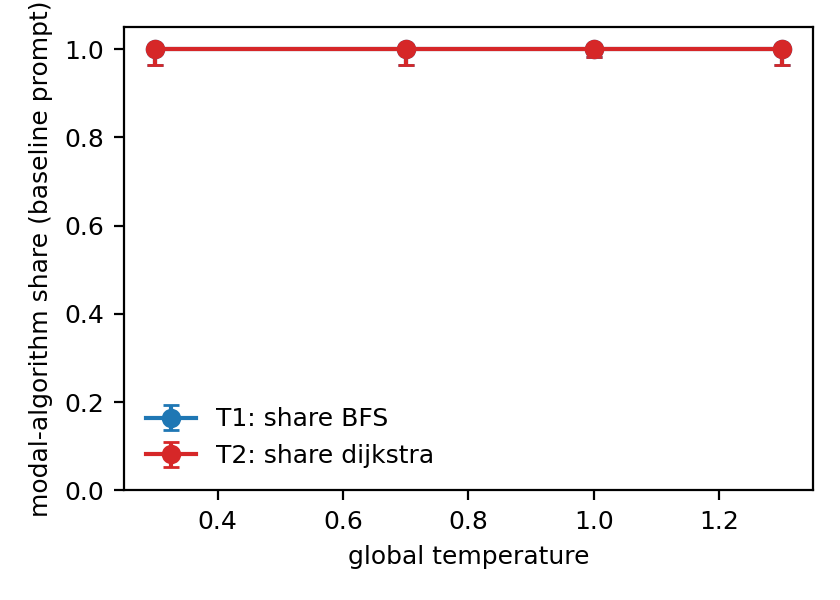

fig2_agreement_curves.png


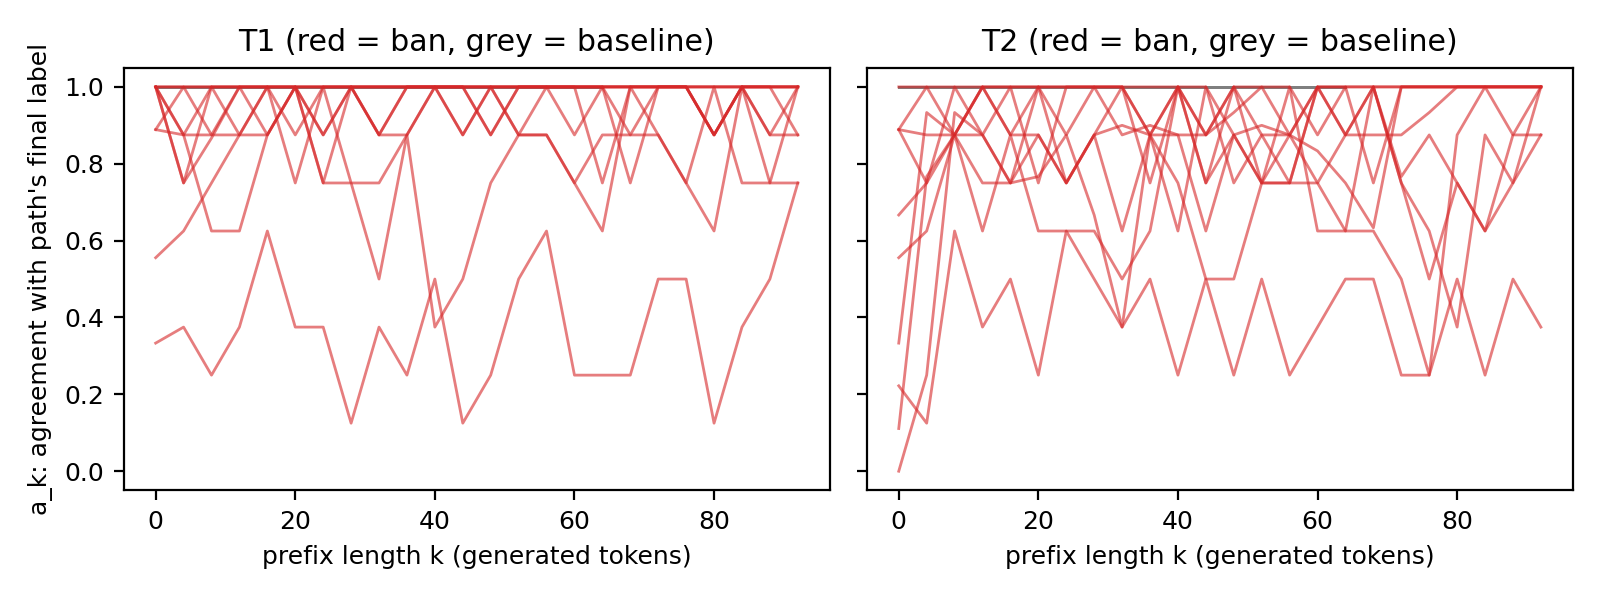

fig3_fork_index_hist.png


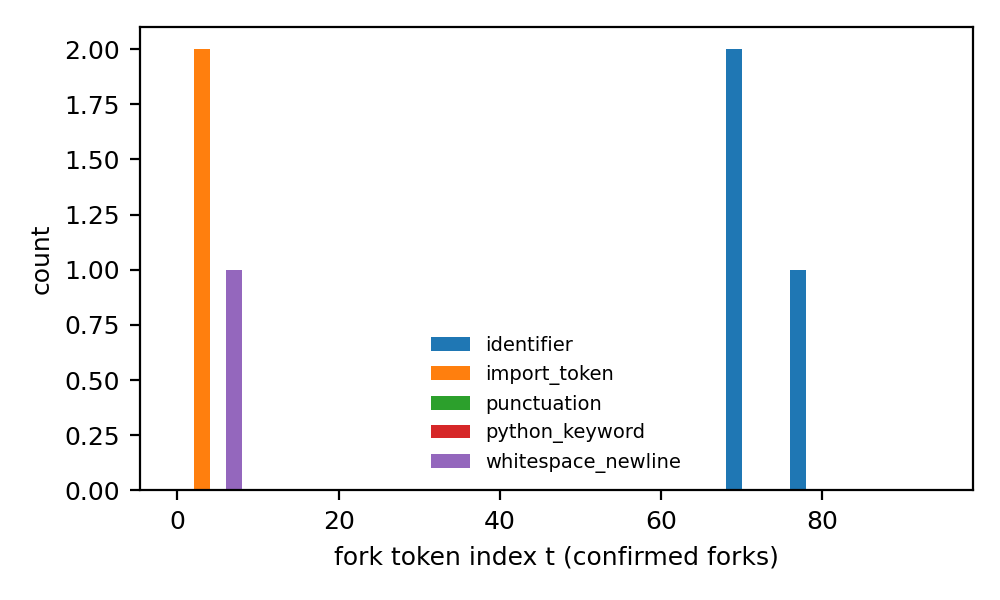

fig5_knob_frontier.png


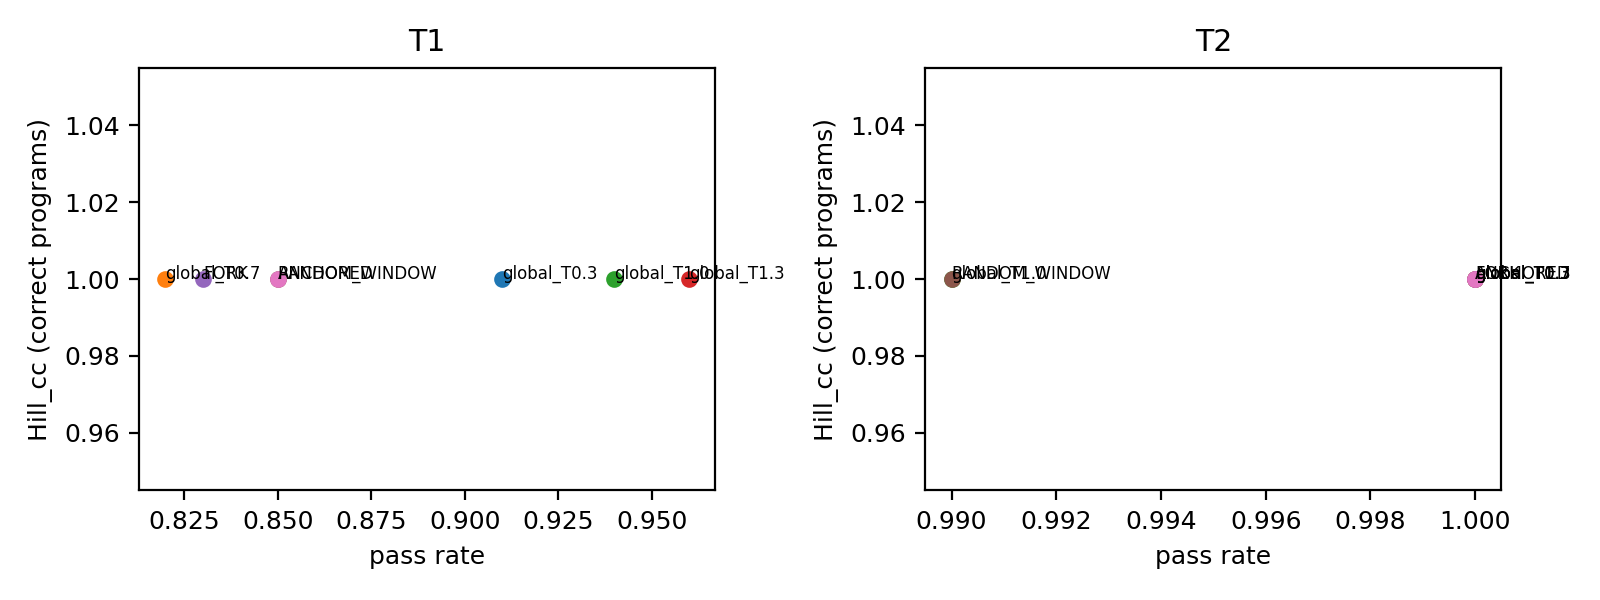

fig6_swap.png


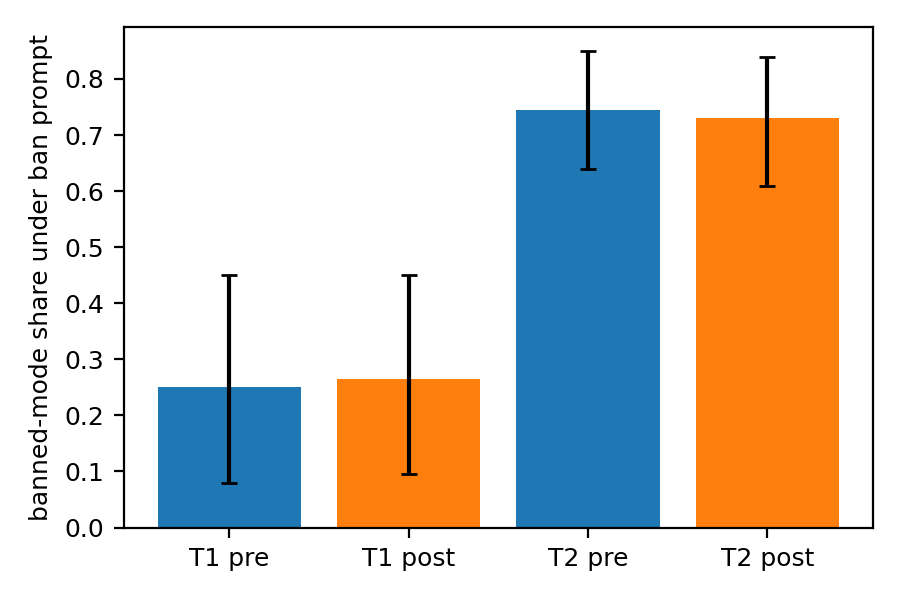

In [40]:
for fn in meta["figures"]:
    print(fn)
    display(Image(filename=str(FIG_DIR / fn), width=720))

### Where along a ban path is the algorithm decided?
Each panel is one ban base path. At every prefix length k it shows the label distribution of the continuations restarted after the base path's first k tokens; k = 0 is the prompt's other pool samples. Overlays:
* grey bands: change-point brackets;
* solid lines: confirmed forks, labelled with the fork token;
* dashed line: the base path's commitment token.

Both lines are drawn at the first prefix length that contains their token.

Baseline paths are not drawn, because every continuation there keeps the modal algorithm.

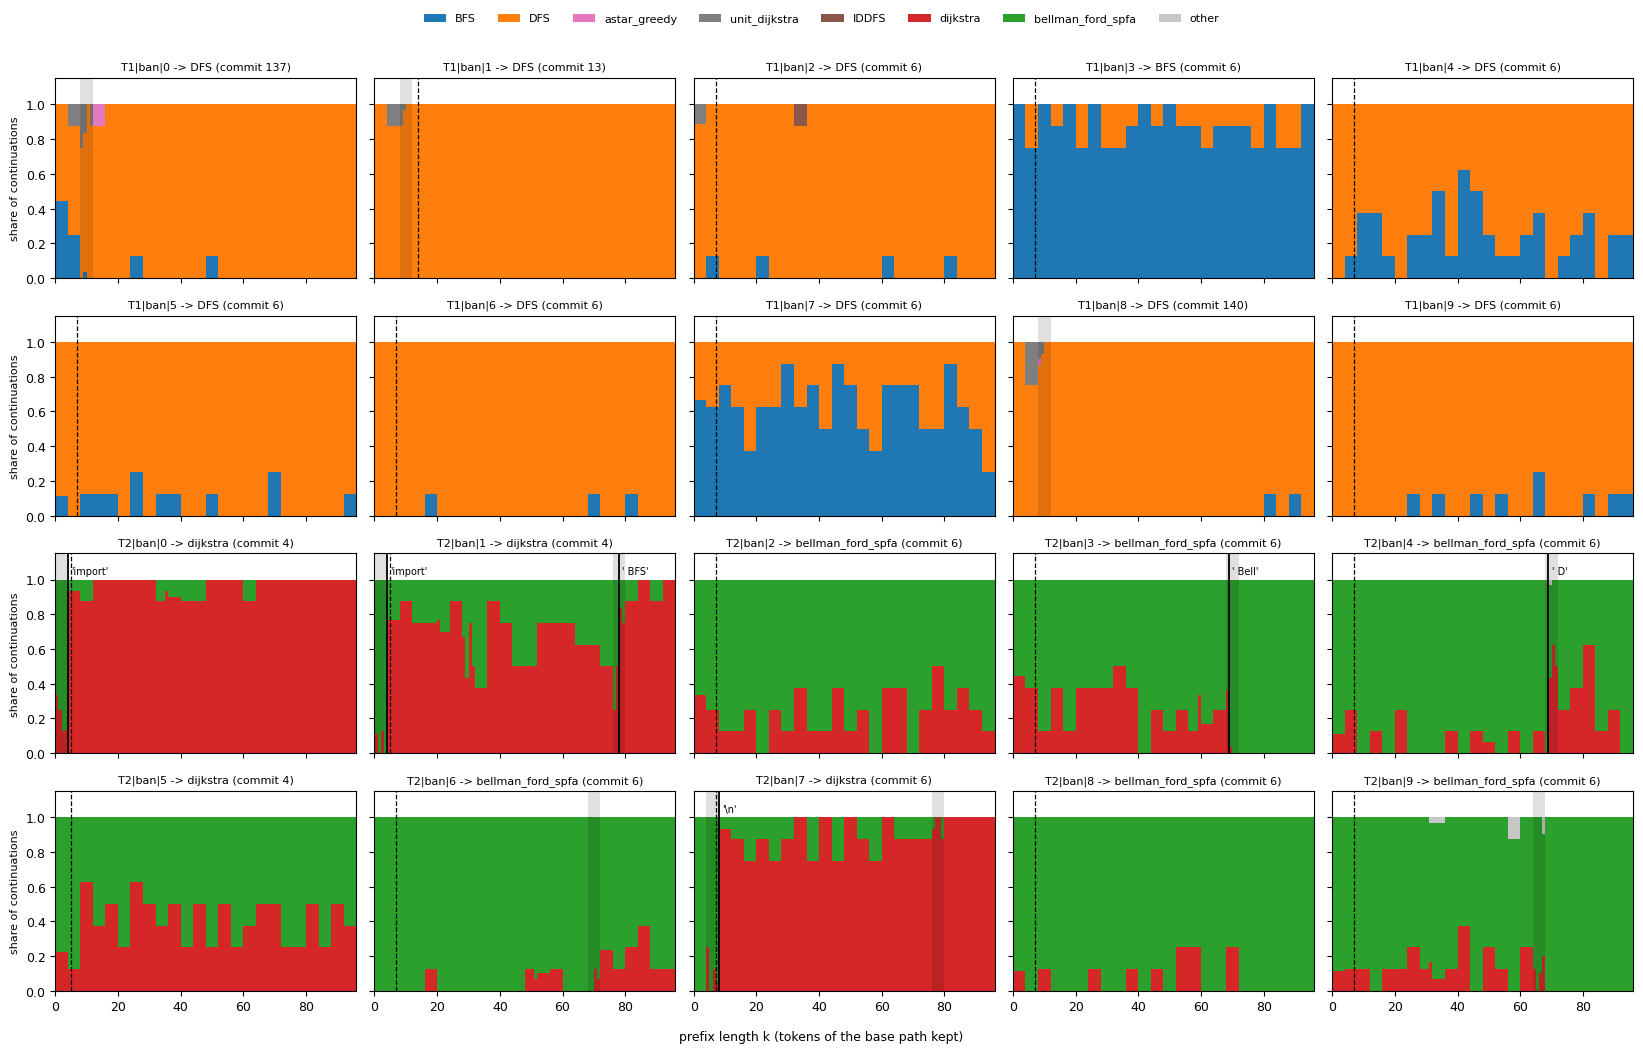

In [41]:
R2 = {k: read_jsonl(GEN_DIR / f"{k}.jsonl") for k in ("pools", "screen", "localise", "confirm")}
apply_final_labels(R2, json.loads((SUM_DIR / "judge.json").read_text()).get("jmap", {}) if USE_RECORDED_JUDGE else {})
by_pos = collections.defaultdict(list)
for f in ("screen", "localise", "confirm"):
    for r in R2[f]:
        by_pos[(r["base_path_id"], r["prefix_len"])].append(r["label_final"])
o0 = collections.defaultdict(list)
for r in R2["pools"]:
    if r["arm"] in ("G1", "G2") and r["sample_id"] != 0:
        o0[f'{r["task"]}|{r["condition"]}|{r["paraphrase_id"]}'].append(r["label_final"])
scr_paths = {p["bp_id"]: p for p in json.loads((SUM_DIR / "screen.json").read_text())["paths"]}
PAL = {"BFS": "#1f77b4", "DFS": "#ff7f0e", "bidirectional_BFS": "#9467bd", "IDDFS": "#8c564b",
       "astar_greedy": "#e377c2", "unit_dijkstra": "#7f7f7f", "dijkstra": "#d62728", "bellman_ford_spfa": "#2ca02c",
       "bidirectional_dijkstra": "#bcbd22", "floyd_warshall": "#17becf", "dial": "#aec7e8", "other": "#c7c7c7",
       "no_code": "#000000"}
ban = sorted([bp for bp in scr_paths if "|ban|" in bp], key=lambda b: (b.split("|")[0], int(b.split("|")[2])))
ncol = min(5, len(ban))
nrow = math.ceil(len(ban) / ncol)
fig_h = 2.4 * nrow + 0.9
fig, axes = plt.subplots(nrow, ncol, figsize=(3.3 * ncol, fig_h), sharex=True, sharey=True, squeeze=False)
for ax, bp in zip(axes.flat, ban):
    task, p = bp.split("|")[0], scr_paths[bp]
    ks = sorted({k for (b, k) in by_pos if b == bp and k > 0})
    pos = np.array([0] + ks + [96])
    dists = [counts_of(task, o0[bp] + by_pos.get((bp, 0), []))] + [counts_of(task, by_pos[(bp, k)]) for k in ks]
    P = np.array([d / d.sum() for d in dists])
    P = np.vstack([P, P[-1:]])
    base = np.zeros(len(pos))
    for j, lab in enumerate(CATS[task]):
        if P[:, j].any():
            ax.fill_between(pos, base, base + P[:, j], step="post", color=PAL.get(lab, "#999999"), lw=0, label=lab)
            base = base + P[:, j]
    for cp in p["change_points"]:
        ax.axvspan(*cp["bracket"], color="k", alpha=0.12, lw=0)
    for f in forks["forks"]:
        if f["bp_id"] == bp and f["confirmed"]:
            ax.axvline(f["t"] + 1, color="k", lw=1.3)
            ax.text(f["t"] + 2, 1.03, repr(f["token"]), fontsize=7)
    if p["commit_idx"] is not None and p["commit_idx"] < 96:
        ax.axvline(p["commit_idx"] + 1, color="k", ls="--", lw=0.9)
    ax.set_title(f'{bp} -> {p["final_label"]} (commit {p["commit_idx"]})', fontsize=8)
    ax.set_xlim(0, 96)
    ax.set_ylim(0, 1.15)
for ax in axes.flat[len(ban):]:
    ax.axis("off")
handles = {}
for ax in axes.flat:
    for h, l in zip(*ax.get_legend_handles_labels()):
        handles.setdefault(l, h)
fig.legend(list(handles.values()), list(handles.keys()), loc="upper center", bbox_to_anchor=(0.5, 1.0),
           ncol=len(handles), frameon=False, fontsize=8)
fig.supxlabel("prefix length k (tokens of the base path kept)", fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel("share of continuations", fontsize=8)
fig.tight_layout(rect=(0, 0, 1, 1 - 0.45 / fig_h))
plt.show()

## What the numbers say
**Temperature does not change the algorithm.**
* Under the baseline prompt, every program implements the modal algorithm: BFS on T1 and Dijkstra on T2. That is all 1,000 pool samples, at T = 0.3, 0.7, 1.0 and 1.3, and all 600 knob-arm samples.
* Temperature changes how the code is *written*. On T1, the within-algorithm phrasing diversity (Hill, θ = 0.8) rises from 6.3 at T = 0.3 to 44.7 at T = 1.3.

**A ban substitutes rather than diversifies.** With the modal algorithm banned (pool G2), the model does not spread over the catalogue. It moves to one named substitute:
* **T1:** DFS in 78 of 100 samples, BFS kept in 21, unit-cost Dijkstra in 1. The pass rate falls from 0.91 to 0.56.
* **T2:** Bellman–Ford/SPFA in 80, Dijkstra kept in 20. The pass rate stays at 1.00.

The sandbox labeller reproduces these counts on all 400 G1/G2 programs (section 3d).

**Under the baseline prompt the prompt decides. Under a ban, single tokens sometimes do.**
* Every baseline path is decided at k = 0 (R0 = 1.00): continuations from every prefix keep the modal algorithm.
* Ban paths are less settled: R0 = 0.80 on T1 and 0.40 on T2.
* Of the 17 ban paths not fixed at k = 0, 5 have a confirmed fork (F1 = 0.29 [0.13, 0.53]). All 6 confirmed forks are on T2. Each one decides whether the banned Dijkstra comes back, and four of them are tokens the model gave at most 15 % probability:
  * **The first code token, `import` (2 paths, t = 3).** The model gives it p = 0.10–0.15, against p = 0.85–0.90 for `from`. Restarted just before it, 26–30 of 30 continuations write SPFA; they mostly open with `from collections import deque`. Restarted just after it, where `import heapq` follows, 23–28 of 30 write Dijkstra.
  * **A single newline after `from collections import deque` (1 path, t = 7, p = 0.02).** It leaves room for a second line, `import heapq`.
  * **The algorithm's name in the plan comment (3 forks on 3 paths, t = 68–77):** ` Bell`, ` D` or ` BFS`. ` Bell` and ` D` are a coin flip at one of these positions.
* The model's own next-token entropy is 0.89 bits at the confirmed forks and 0.02 bits at the control positions. None of the 10 controls fires (F3 = 0).
* On T1 no fork is confirmed. 8 of the 10 ban paths are already decided at the prompt (R0 = 0.80). The change points on three paths, all at k = 8–12, were not confirmed at the token level, and T1|ban|7 stays mixed between BFS and DFS over the whole prefix range.

**The commitment token does not lock the choice in.**
* Swapping in the ban prompt just before or just after the token that first names the algorithm makes no difference. The ban effect is 0.750 vs 0.735 on T1 and 0.255 vs 0.270 on T2; pooled, pre − post = 0.000 [−0.045, 0.040]. So the pre-registered prediction "pre > post" fails.
* On T1, the ban still moves three quarters of the continuations off BFS after `from collections import deque` has been written.
* On T2 the ban is weak on both sides. The `pre` prefix already ends in `import`, the token the screen found to be a fork.

**Heating the fork window cannot diversify a single-mode distribution.**
* All seven arms produce one algorithm per task (Hill_cc = 1.00), so K1 = 0 [0, 0].
* FORK keeps the phrasing as uniform as T = 0.3 does (T1: 6.1 vs 6.3), while global T = 1.3 multiplies it.

**The verdict is INCONCLUSIVE, as in the stored run.**
* The fork criteria fail: F1 = 0.29 < 0.5, and D1 is False because there are no probes.
* K1 is null on both tasks.
* REFUTED does not apply either: T2's ban paths are mostly undecided at the prompt (R0 = 0.40), and F1 ≥ 0.25.